# **🏎️ Reto 02: Predicción de F1 — Podio, Puntos y Posición Final**
### **OUTLIERS IN DATA · Estrategia de Carrera y Machine Learning en Fórmula 1**

Este mes cambiamos los préstamos por los circuitos de Fórmula 1. Actuamos como el **equipo de ciencia de datos y estrategia de una escudería**: el sábado por la noche, tras la clasificación y con la parrilla de salida definida, el jefe de estrategia nos pide dos predicciones críticas para la carrera del domingo:

1. **Probabilidades de éxito:**
   - **Podio ($p_\text{podio}$):** $P(\text{positionOrder} \le 3)$
   - **Top 10 / Puntos ($p_\text{top10}$):** $P(\text{positionOrder} \le 10)$
   - ⚠️ **Restricción obligatoria de coherencia:** Para cada piloto debe cumplirse estrictamente:
     $$p_\text{podio} \le p_\text{top10}$$
     *(Si no se cumple para algún piloto, la entrega queda automáticamente descalificada).*

2. **Posición final de carrera:**
   - $\text{posicion\_pred}$: un valor numérico continuo o puntuación por piloto, que se convertirá en un orden estricto dentro de cada carrera (el valor más bajo, primero: $1, 2, \dots, N$).

---

### **⏱️ La Regla de Oro Anti-Fuga (*Zero Data Leakage*): Momento Temporal de Predicción**
Predecimos **el sábado por la noche**, después de la clasificación y antes de la carrera del domingo.

| Permitido (Inputs para el GP $t$) | Estrictamente Prohibido (Data Leakage del GP $t$) |
|---|---|
| **Parrilla de salida (`grid`)** y tiempos de clasificación (`q1`, `q2`, `q3`) del fin de semana | Cualquier variable de la propia carrera: `position`, `positionOrder`, `points`, `laps`, `time`, `fastestLap`, `fastestLapSpeed`, `statusId` |
| **Resultado de la carrera Sprint** de ese fin de semana (si la hay, porque se corre el sábado) | Tiempos por vuelta (`lap_times`) o paradas en boxes (`pit_stops`) de la carrera del domingo |
| **Histórico acumulado de carreras ANTERIORES ($< t$):** resultados, clasificaciones, mundiales, paradas, abandonos, fiabilidad, forma reciente | ⚠️ **Trampa clásica:** `driver_standings`, `constructor_standings` y `constructor_results` asociados al GP $t$ reflejan el mundial **DESPUÉS** de la carrera. Para usarlos, deben desplazarse temporalmente ($t-1$). Usar cualquier variable de la carrera que se predice descalifica el proyecto. |

---

### **🗓️ Partición Temporal y Validación**
- **Test:** Temporada **2024 completa** (Gran Premio a Gran Premio, evaluado cronológicamente).
- **Train:** Histórico previo hasta **2023**. Justificaremos el año inicial de entrenamiento (e.g. era híbrida moderna desde 2014). Si el dataset trae datos de 2025, se descartan.
- **Validación:** Temporal dentro de train (por ejemplo, temporada **2023** como muestra de validación fuera de tiempo).
- **Forma reciente en 2024:** Para predecir una carrera en 2024, se pueden calcular variables de forma reciente usando las carreras previas de 2024 ya disputadas (lo que haría un estratega real).

## **📦 Bloque 1 · Setup, Entorno y Configuración**

### **1.1 ⚙️ Setup y CONFIG: el panel de control del reto**

En esta primera sección preparamos el entorno de trabajo del reto de Fórmula 1. Por un lado importamos las librerías que utilizaremos en todo el proyecto (`numpy`, `pandas`, `matplotlib` y `seaborn`). También silenciamos los avisos (`warnings`) para mantener el notebook limpio.

Por otro lado definimos el **CONFIG del proyecto**: el panel de control central que agrupa las constantes maestras:
- **`SEED = 2502`**: la **semilla oficial y obligatoria del reto** para garantizar que todo el proceso sea 100% reproducible al evaluarse de arriba abajo.
- **Rango temporal oficial:** Temporada de **Test (`YEAR_TEST = 2024`)**, temporada de **Validación (`YEAR_VAL = 2023`)** y el corte inicial justificado de entrenamiento en la **era híbrida moderna (`YEAR_TRAIN_MIN = 2014`)**.
- **Reproducibilidad de LightGBM (`N_JOBS = 4`, `LGB_DETERMINISTA`):** todos los modelos de árboles usan un número fijo de hilos y el modo `deterministic`, para que el resultado no dependa del número de núcleos del ordenador que vuelva a ejecutar el notebook. Al final de la celda se imprimen las versiones de las librerías.
- **Carga de datos desde la carpeta del notebook (norma del reto):** los 14 CSV del dataset *Formula 1 World Championship (1950–2024)* de Kaggle se leen por nombre desde la misma carpeta del notebook (`DATA_DIR = "."`) y se guardan en el diccionario `dfs`. Si falta alguno, el notebook se detiene con un mensaje claro. Si la versión de los datos incluye 2025, esas carreras se descartan en el Bloque 2.

In [1]:
# --- CONFIG: panel de control central del reto ---
# Semilla oficial obligatoria fijada por las bases del reto para reproducibilidad absoluta (SEED = 2502).
SEED = 2502

# Temporada oficial reservada exclusivamente para la evaluación final en Test (2024 completa).
YEAR_TEST = 2024

# Temporada de validación temporal dentro de train para optimización de hiperparámetros y calibración (2023).
YEAR_VAL = 2023

# Año de inicio justificado de la muestra de entrenamiento: era híbrida moderna con reglamentación V6 turbo (2014).
YEAR_TRAIN_MIN = 2014

# Carpeta de datos: la MISMA carpeta del notebook (norma del reto). Los CSV del dataset de Kaggle
# "Formula 1 World Championship (1950-2024)" (rohanrao/formula-1-world-championship-1950-2020) deben estar junto al notebook.
DATA_DIR = "."

# Reproducibilidad de LightGBM: número de hilos FIJO y modo determinista. Con n_jobs=-1 el número de hilos depende de la
# máquina que ejecute el notebook y el orden de las sumas en coma flotante puede cambiar ligeramente el resultado.
N_JOBS = 4
LGB_DETERMINISTA = {"n_jobs": N_JOBS, "deterministic": True, "force_row_wise": True}

# Tablas del dataset que se cargan (se leen por nombre para no confundirlas con otros CSV, como el de la entrega).
TABLAS_DATASET = ["circuits", "constructor_results", "constructor_standings", "constructors", "driver_standings", "drivers",
                  "lap_times", "pit_stops", "qualifying", "races", "results", "seasons", "sprint_results", "status"]

# --- Importación de librerías generales del proyecto ---
# Importa 'os' para interactuar con variables de entorno del sistema y rutas locales de archivos.
import os

# Importa 'glob' para localizar y listar ficheros en disco según patrones de texto comodín (*.csv).
import glob

# Importa 'numpy' bajo el alias 'np' para cálculo numérico, álgebra lineal y arrays multidimensionales.
import numpy as np

# Importa 'pandas' bajo el alias 'pd' para manipulación, unión y análisis estructurado de DataFrames.
import pandas as pd

# Importa 'matplotlib.pyplot' para renderizado de figuras y control de ejes gráficos.
import matplotlib.pyplot as plt

# Importa 'seaborn' para visualizaciones estadísticas de alto nivel.
import seaborn as sns

# Importa el módulo de gestión de avisos del sistema para evitar salidas de texto innecesarias.
import warnings

# Silencia los avisos del sistema (FutureWarnings/UserWarnings) para mantener la salida del notebook limpia.
warnings.filterwarnings("ignore")

# --- Reproducibilidad y configuración estética de visualización ---
# Fija la semilla pseudoaleatoria de NumPy para garantizar repetibilidad en muestreos y modelos.
np.random.seed(SEED)

# Aplica el tema visual estándar de Seaborn con fondo de cuadrícula suave y paleta equilibrada.
sns.set_theme(style="whitegrid", palette="muted")

# Configura pandas para mostrar hasta 60 columnas de datos sin truncar la vista en el editor.
pd.set_option("display.max_columns", 60)

# Establece el formato de visualización para números decimales flotantes con 4 cifras decimales.
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Fija las dimensiones por defecto (ancho, alto en pulgadas) para todas las figuras del notebook.
plt.rcParams["figure.figsize"] = (11, 4)

# Activa por defecto la rejilla de coordenadas en los ejes gráficos para facilitar la lectura.
plt.rcParams["axes.grid"] = True

# Fija una opacidad sutil del 30% en las líneas de la rejilla para no sobrecargar las visualizaciones.
plt.rcParams["grid.alpha"] = 0.3

# --- Carga de las tablas CSV desde la carpeta del notebook en un diccionario de DataFrames ---
# Comprueba antes de empezar que todos los CSV necesarios están en la carpeta del notebook.
faltan = [t for t in TABLAS_DATASET if not os.path.exists(os.path.join(DATA_DIR, f"{t}.csv"))]
assert not faltan, f"❌ Faltan estos CSV en la carpeta del notebook ({os.path.abspath(DATA_DIR)}): {faltan}"

# Muestra la carpeta desde la que se leen los datos.
print(f"Carpeta de datos: {os.path.abspath(DATA_DIR)}\n")

# Inicializa el diccionario en memoria donde cada clave será el nombre de la tabla.
dfs = {}

# Carga cada tabla por su nombre.
for table_name in TABLAS_DATASET:
    # Lee el CSV de la carpeta del notebook y lo asigna al diccionario.
    dfs[table_name] = pd.read_csv(os.path.join(DATA_DIR, f"{table_name}.csv"))

    # Imprime la confirmación de carga con el recuento exacto de filas y columnas de la tabla.
    print(f"✓ Cargado '{table_name}': {dfs[table_name].shape[0]} filas, {dfs[table_name].shape[1]} columnas")

# Deja constancia de las versiones de las librerías con las que se generó la entrega.
import sys, sklearn, scipy, lightgbm
print(f"\nVersiones: Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | scipy {scipy.__version__}")

# Imprime confirmación de cierre del Bloque 1 verificando la semilla obligatoria SEED = 2502.
print(f"\n✅ CONFIG definido, SEED = {SEED} fijada y {len(dfs)} tablas cargadas correctamente.")

Carpeta de datos: /home/jaume/Escritorio/Programació/Outliers in Data/Retos Mensuales/Reto_02_F1

✓ Cargado 'circuits': 77 filas, 9 columnas
✓ Cargado 'constructor_results': 12625 filas, 5 columnas
✓ Cargado 'constructor_standings': 13391 filas, 7 columnas
✓ Cargado 'constructors': 212 filas, 5 columnas
✓ Cargado 'driver_standings': 34863 filas, 7 columnas
✓ Cargado 'drivers': 861 filas, 9 columnas
✓ Cargado 'lap_times': 589081 filas, 6 columnas
✓ Cargado 'pit_stops': 11371 filas, 7 columnas
✓ Cargado 'qualifying': 10494 filas, 9 columnas
✓ Cargado 'races': 1125 filas, 18 columnas
✓ Cargado 'results': 26759 filas, 18 columnas
✓ Cargado 'seasons': 75 filas, 2 columnas
✓ Cargado 'sprint_results': 360 filas, 16 columnas
✓ Cargado 'status': 139 filas, 2 columnas

Versiones: Python 3.14.9 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | lightgbm 4.7.0 | scipy 1.18.1

✅ CONFIG definido, SEED = 2502 fijada y 14 tablas cargadas correctamente.


## **🔍 Bloque 2 · Exploración del Ecosistema Relacional y Auditoría Anti-Fuga**

Inspección de las relaciones entre tablas (`results`, `races`, `drivers`, `constructors`, `qualifying`, `sprint_results`, `driver_standings`, `constructor_standings`, `lap_times`, `pit_stops`, `status`, `circuits`). Definición de la unidad de predicción: cada fila de `results.csv` para un Gran Premio de F1.

### **2.1 🔗 Integridad relacional, estructura de claves y cardinalidad de uniones**

Para garantizar que ningún *merge* posterior genere duplicados, productos cartesianos o identifique erróneamente registros como duplicados, auditamos el esquema relacional en cuatro niveles:

1. **Unicidad de Claves Primarias (PKs)** en tablas dimensionales (`drivers`, `constructors`, `races`, `circuits`, `status`). Si una PK tuviera duplicados, cualquier cruce multiplicaría filas.
2. **Clave natural compuesta de la unidad de predicción:** En `results.csv`, la unidad atómica es el binomio `(raceId, driverId)`. Comprobamos que cada piloto compita exactamente una vez por carrera.
3. **Cardinalidad de tablas de evento del fin de semana (`qualifying`, `sprint_results`) y standings:** Verificamos si la relación con `results` sobre `(raceId, driverId)` o `(raceId, constructorId)` es estrictamente **1 a 1** o **1 a 0** (ausente en carreras sin sprint o eras pre-clasificación).
4. **Integridad referencial y detección de columnas homónimas:** Chequeo de claves foráneas huérfanas y mapeo de nombres duplicados entre tablas (`name`, `points`, `url`) para evitar colisiones (`_x`, `_y`).
5. **Filtro temporal:** Exclusión preventiva de registros de 2025 o posteriores según las bases del reto.

In [2]:
# Imprime el encabezado de la sección dedicada a inspeccionar las dimensiones de las tablas y el rango temporal.
print("--- 1. Dimensiones y Filtro Temporal ---")

# Define la lista con los nombres de las 10 tablas centrales necesarias para el análisis del ecosistema de F1.
tablas_clave = ['results', 'races', 'drivers', 'constructors', 'qualifying', 
                'sprint_results', 'driver_standings', 'constructor_standings', 'status', 'circuits']

# Itera por cada tabla de interés para validar su presencia y resumir su tamaño.
for t in tablas_clave:
    # Comprueba si la tabla existe en el diccionario de datos cargados 'dfs'.
    if t in dfs:
        # Muestra el nombre de la tabla formateado junto al total de filas y columnas que contiene.
        print(f"• {t:<23}: {dfs[t].shape[0]:>6} filas | {dfs[t].shape[1]:>2} cols")

# Realiza una copia defensiva del DataFrame de carreras para verificar temporadas sin modificar el original aún.
df_races = dfs['races'].copy()

# Calcula el año mínimo y el año máximo de las temporadas de F1 presentes en la tabla 'races'.
min_year, max_year = df_races['year'].min(), df_races['year'].max()

# Imprime el rango temporal total registrado en la base de datos de Grandes Premios.
print(f"\nTemporadas registradas: {min_year} - {max_year}")

# Comprueba si el dataset contiene carreras programadas o simuladas para 2025 o años posteriores.
if max_year >= 2025:
    # Cuenta cuántas carreras corresponden a la temporada 2025 o superior.
    n_2025 = (df_races['year'] >= 2025).sum()
    
    # Imprime un aviso indicando que estas carreras serán descartadas conforme a las reglas del reto.
    print(f"⚠️ Detectadas {n_2025} carreras de temporadas >= 2025. Se descartan según las reglas.")
    
    # Obtiene los identificadores únicos ('raceId') de las carreras válidas disputadas hasta 2024 inclusive.
    races_validas = df_races[df_races['year'] <= 2024]['raceId'].unique()
    
    # Filtra la tabla 'races' en 'dfs' para conservar únicamente temporadas hasta 2024 y reinicia su índice.
    dfs['races'] = df_races[df_races['year'] <= 2024].reset_index(drop=True)
    
    # Filtra la tabla 'results' para mantener solo filas correspondientes a las carreras válidas (<= 2024).
    dfs['results'] = dfs['results'][dfs['results']['raceId'].isin(races_validas)].reset_index(drop=True)
else:
    # Imprime confirmación de que no se detectaron carreras de 2025 y que el rango es válido.
    print("✓ Rango temporal válido (hasta 2024). Sin registros de 2025.")

# Imprime el encabezado de la subsección dedicada a verificar la unicidad de las claves primarias maestras.
print("\n--- 2. Unicidad de Claves Primarias (PKs) Maestras ---")

# Define las parejas (tabla, columna_clave_primaria) que deben ser estrictamente únicas en sus tablas dimensionales.
pks_a_verificar = [
    ('races', 'raceId'),
    ('drivers', 'driverId'),
    ('constructors', 'constructorId'),
    ('circuits', 'circuitId'),
    ('status', 'statusId')
]

# Itera sobre cada tabla y su respectiva clave primaria para auditar si existen duplicados.
for tabla, pk in pks_a_verificar:
    # Comprueba que la tabla se encuentre disponible en el diccionario 'dfs'.
    if tabla in dfs:
        # Cuenta la cantidad de valores duplicados en la columna que actúa como clave primaria.
        dups = dfs[tabla][pk].duplicated().sum()
        
        # Guarda el número total de filas de la tabla analizada.
        total = len(dfs[tabla])
        
        # Determina el texto descriptivo del estado según si hay cero duplicados o anomalías.
        estado = "✓ Única al 100%" if dups == 0 else f"⚠️ {dups} duplicados detectados!"
        
        # Imprime el resultado de la auditoría de unicidad para la clave primaria evaluada.
        print(f"• PK '{tabla}.{pk}': {estado} (N={total:,})")

# Imprime el encabezado de la auditoría de la clave compuesta de predicción y su desglose temporal.
print("\n--- 3. Unidad de Predicción: Clave Compuesta (raceId, driverId) en 'results' ---")

# Asigna la tabla central 'results' a una variable local para facilitar las comprobaciones siguientes.
df_results = dfs['results']

# Calcula el número de pares ('raceId', 'driverId') duplicados en todo el histórico de F1.
dups_target = df_results.duplicated(subset=['raceId', 'driverId']).sum()

# Imprime el conteo bruto de duplicados en el par (raceId, driverId).
print(f"• Duplicados históricos brutos en (raceId, driverId): {dups_target}")

# Cruza temporalmente con 'races' para determinar en qué años ocurrieron dichos duplicados.
df_results_con_anio = df_results.merge(dfs['races'][['raceId', 'year']], on='raceId')

# Filtra las filas duplicadas en (raceId, driverId) para analizar su distribución temporal.
mascara_dups = df_results_con_anio.duplicated(subset=['raceId', 'driverId'], keep=False)

# Obtiene el año más reciente en el que se produjo una fila compartida/duplicada en F1.
max_anio_dups = df_results_con_anio[mascara_dups]['year'].max()

# Calcula los duplicados en la era moderna (desde 1980 en adelante) y en la era híbrida (>= 2014).
dups_post_1980 = df_results_con_anio[mascara_dups].query("year >= 1980").shape[0]
dups_era_hibrida = df_results_con_anio[mascara_dups].query("year >= 2014").shape[0]

# Muestra el diagnóstico histórico confirmando que se trata del fenómeno de 'coche compartido' (shared drive).
print(f"  └─ Causa histórica: Coches compartidos ('shared drives'). Último caso registrado en {max_anio_dups}.")
print(f"  └─ Duplicados desde 1980: {dups_post_1980} (✓ 0 duplicados)")
print(f"  └─ Duplicados en era híbrida (>= 2014) y Test 2024: {dups_era_hibrida} (✓ Estricta unicidad 1 a 1)")

# Muestra el número de valores ausentes (nulos) en la variable objetivo principal 'positionOrder'.
print(f"• Nulos en target 'positionOrder': {df_results['positionOrder'].isnull().sum()} (✓ Target completo sin nulos)")

# Imprime el encabezado de auditoría de cardinalidad previa al cruce de tablas de fin de semana con 'results'.
print("\n--- 4. Cardinalidad en Tablas Pre-Carrera sobre (raceId, driverId) ---")

# Comprueba si la tabla de clasificación ('qualifying') está cargada en el diccionario 'dfs'.
if 'qualifying' in dfs:
    # Cuenta duplicados en el par ('raceId', 'driverId') dentro de la tabla de clasificación.
    dups_q = dfs['qualifying'].duplicated(subset=['raceId', 'driverId']).sum()
    
    # Imprime el resultado de la comprobación de unicidad para la tabla 'qualifying'.
    print(f"• qualifying: duplicados en (raceId, driverId) = {dups_q} {'(✓ Relación 1 a 1 / 1 a 0)' if dups_q == 0 else '⚠️ Duplicados en qualifying'}")

# Comprueba si la tabla de carreras al sprint ('sprint_results') está cargada en 'dfs'.
if 'sprint_results' in dfs:
    # Cuenta duplicados en el par ('raceId', 'driverId') dentro de la tabla de resultados de Sprint.
    dups_sprint = dfs['sprint_results'].duplicated(subset=['raceId', 'driverId']).sum()
    
    # Imprime el resultado confirmando que la relación es como máximo 1 a 1 por piloto-carrera.
    print(f"• sprint_results: duplicados en (raceId, driverId) = {dups_sprint} {'(✓ Relación 1 a 1 / 1 a 0)' if dups_sprint == 0 else '⚠️ Duplicados en sprint'}")

# Comprueba si la tabla de clasificación del campeonato de pilotos ('driver_standings') está en 'dfs'.
if 'driver_standings' in dfs:
    # Cuenta duplicados en el par ('raceId', 'driverId') dentro de la tabla de standings de pilotos.
    dups_ds = dfs['driver_standings'].duplicated(subset=['raceId', 'driverId']).sum()
    
    # Imprime si cada piloto tiene una sola fila de standing por Gran Premio disputado.
    print(f"• driver_standings: duplicados en (raceId, driverId) = {dups_ds} {'(✓ Relación 1 a 1 por carrera)' if dups_ds == 0 else '⚠️ Duplicados en driver standings'}")

# Imprime el encabezado de la verificación de claves foráneas desde la tabla 'results' hacia las maestras.
print("\n--- 5. Integridad Referencial desde 'results' ---")

# Define las tuplas (columna_fk_en_results, tabla_referenciada, columna_pk_referenciada).
fks = [
    ('raceId', 'races', 'raceId'),
    ('driverId', 'drivers', 'driverId'),
    ('constructorId', 'constructors', 'constructorId'),
    ('statusId', 'status', 'statusId')
]

# Itera sobre cada clave foránea para asegurar que no apunte a identificadores inexistentes.
for fk_col, ref_table, pk_col in fks:
    # Calcula cuántos registros en 'results' contienen un valor que no figura en la clave primaria de la tabla maestra.
    huerfanos = (~df_results[fk_col].isin(dfs[ref_table][pk_col])).sum()
    
    # Imprime el total de registros huérfanos verificando la consistencia relacional.
    print(f"• FK '{fk_col}' -> '{ref_table}.{pk_col}': {huerfanos} huérfanos {'(✓ Integridad perfecta)' if huerfanos == 0 else '⚠️'}")

# Imprime el encabezado para detectar columnas con nombres duplicados entre distintas tablas.
print("\n--- 6. Auditoría de Columnas con Mismo Nombre entre Tablas ---")

# Guarda en un conjunto ('set') los nombres de todas las columnas que componen la tabla 'results'.
cols_results = set(df_results.columns)

# Itera por las tablas que habitualmente se unen a 'results' para chequear posibles colisiones de nombres.
for t in ['races', 'drivers', 'constructors', 'circuits', 'qualifying']:
    # Comprueba que la tabla analizada exista en 'dfs'.
    if t in dfs:
        # Detecta columnas comunes excluyendo las claves foráneas legítimas de enlace ('raceId', 'driverId', 'constructorId').
        comunes = (cols_results & set(dfs[t].columns)) - {'raceId', 'driverId', 'constructorId'}
        
        # Si se detectan atributos homónimos, se imprime la advertencia para planificar su renombrado.
        if comunes:
            # Informa de las columnas compartidas que necesitarán prefijo para evitar sufijos automáticos '_x' o '_y'.
            print(f"• 'results' comparte columnas con '{t}': {comunes} -> Requieren prefijo/renombrado al unir.")

--- 1. Dimensiones y Filtro Temporal ---
• results                :  26759 filas | 18 cols
• races                  :   1125 filas | 18 cols
• drivers                :    861 filas |  9 cols
• constructors           :    212 filas |  5 cols
• qualifying             :  10494 filas |  9 cols
• sprint_results         :    360 filas | 16 cols
• driver_standings       :  34863 filas |  7 cols
• constructor_standings  :  13391 filas |  7 cols
• status                 :    139 filas |  2 cols
• circuits               :     77 filas |  9 cols

Temporadas registradas: 1950 - 2024
✓ Rango temporal válido (hasta 2024). Sin registros de 2025.

--- 2. Unicidad de Claves Primarias (PKs) Maestras ---
• PK 'races.raceId': ✓ Única al 100% (N=1,125)
• PK 'drivers.driverId': ✓ Única al 100% (N=861)
• PK 'constructors.constructorId': ✓ Única al 100% (N=212)
• PK 'circuits.circuitId': ✓ Única al 100% (N=77)
• PK 'status.statusId': ✓ Única al 100% (N=139)

--- 3. Unidad de Predicción: Clave Compuesta (raceI

  └─ Causa histórica: Coches compartidos ('shared drives'). Último caso registrado en 1978.
  └─ Duplicados desde 1980: 0 (✓ 0 duplicados)
  └─ Duplicados en era híbrida (>= 2014) y Test 2024: 0 (✓ Estricta unicidad 1 a 1)
• Nulos en target 'positionOrder': 0 (✓ Target completo sin nulos)

--- 4. Cardinalidad en Tablas Pre-Carrera sobre (raceId, driverId) ---
• qualifying: duplicados en (raceId, driverId) = 0 (✓ Relación 1 a 1 / 1 a 0)
• sprint_results: duplicados en (raceId, driverId) = 0 (✓ Relación 1 a 1 / 1 a 0)
• driver_standings: duplicados en (raceId, driverId) = 0 (✓ Relación 1 a 1 por carrera)

--- 5. Integridad Referencial desde 'results' ---
• FK 'raceId' -> 'races.raceId': 0 huérfanos (✓ Integridad perfecta)
• FK 'driverId' -> 'drivers.driverId': 0 huérfanos (✓ Integridad perfecta)
• FK 'constructorId' -> 'constructors.constructorId': 0 huérfanos (✓ Integridad perfecta)
• FK 'statusId' -> 'status.statusId': 0 huérfanos (✓ Integridad perfecta)

--- 6. Auditoría de Columnas c

#### **💡 Conclusiones del Diagnóstico Relacional (Sección 2.1)**

Tras ejecutar la auditoría de integridad, cardinalidad y claves del ecosistema, extraemos **cuatro conclusiones analíticas fundamentales** para el modelado:

1. **La causa de los 91 *"duplicados"* en `(raceId, driverId)`: el fenómeno histórico de los *Coches Compartidos* (*Shared Drives*):**
   - En las primeras décadas de la F1 (décadas de 1950 y 1960), el reglamento permitía a un piloto ceder su coche a otro compañero de equipo durante la carrera si el de este último se averiaba, repartiéndose los puntos entre ambos (por ejemplo, Stirling Moss y Tony Brooks compartieron la victoria del GP de Gran Bretaña de 1957).
   - **Diagnóstico temporal:** El **100% de estos registros** corresponde a carreras disputadas entre **1950 y 1978** (el último caso fue Harald Ertl en el GP de Italia de 1978).
   - **Impacto en el reto:** **Cero impacto en la era moderna ni en el conjunto de Test (2024)**. Desde 1980 en adelante (y especialmente en la era híbrida moderna $\ge 2014$), la relación `(raceId, driverId)` es **estrictamente única (1 fila por piloto y carrera)**. Esto proporciona un argumento de negocio adicional de enorme peso para delimitar el conjunto de entrenamiento a la era moderna.

2. **Integridad referencial inmaculada (0 registros huérfanos):**
   - Todas las claves foráneas de `results` (`raceId`, `driverId`, `constructorId`, `statusId`) existen en el 100% de sus tablas dimensionales correspondientes. No se perderá ningún registro al hacer `INNER JOIN` con las tablas maestras.

3. **Cardinalidad perfecta en tablas satélite pre-carrera:**
   - En `qualifying`, `sprint_results` y `driver_standings`, la cardinalidad sobre `(raceId, driverId)` es estrictamente **1 a 1** (o **1 a 0** en fines de semana sin formato Sprint). Ningún cruce multiplicará filas ni generará duplicados artificiales.

4. **Prevención activa de colisiones de nombres (*Column Clashing*):**
   - Columnas homónimas detectadas: `time` (`results`–`races`), `number` (`results`–`drivers` y `results`–`qualifying`) y `position` (`results`–`qualifying`).
   - En el tablón del Bloque 4 se evitan los sufijos `_x` / `_y` de dos formas: seleccionando solo las columnas necesarias de cada tabla dimensional (de `races` no se trae `time` y de `drivers` no se trae `number`) y renombrando la `position` de clasificación a `qualy_pos`.

### **2.2 🛡️ Auditoría Anti-Fuga (*Zero Data Leakage*): Diccionario del Sábado Noche**

Esta es la decisión arquitectónica más crítica del proyecto. La pregunta que separa cada dato en todo el ecosistema relacional es: **¿existía este dato el sábado por la noche, tras terminar la clasificación (y la Sprint, si la hubo) y antes de apagarse el semáforo el domingo?**

Clasificamos exhaustivamente las **18 columnas de `results.csv`** y el rol de las **13 tablas auxiliares** en cuatro categorías mutuamente excluyentes:

1. **🟢 Pre-Carrera / Sábado Noche (`PRE_CARRERA_RESULTS` + Dimensiones + Qualy + Sprint):** Identificadores del evento (`raceId`, `driverId`, `constructorId`), dorsal del piloto (`number`) y **posición de salida en parrilla (`grid`)**, junto con los tiempos de clasificación (`qualifying`) y el resultado de la carrera Sprint del sábado (`sprint_results`) de ese mismo fin de semana $t$. **Son los únicos inputs directos permitidos en $t$.**
2. **🔴 Post-Carrera / Domingo (`POST_CARRERA_PROHIBIDAS`):** Todo lo que ocurre desde que se apaga el semáforo hasta la bandera a cuadros del domingo en `results.csv` (`position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId`). **Están terminantemente prohibidas como predictores de la carrera $t$**; solo pueden emplearse de forma diferida ($< t$) para construir variables de forma reciente o fiabilidad histórica.
3. **🟡 Tablas con Trampa Temporal (`TABLAS_REQUIEREN_LAG_T1`):** En la base de datos de Ergast/Kaggle, las tablas `driver_standings`, `constructor_standings` y `constructor_results` asociadas a un `raceId` $t$ contienen los puntos, victorias y posición del campeonato **DESPUÉS de finalizar la carrera del domingo $t$**. Cruzarlas directamente por `raceId` es fuga de datos directa (*data leakage* descalificante). **Solo pueden unirse aplicando un desfase cronológico estricto hacia atrás ($t-1$)** dentro de cada temporada (y reseteando a `0` puntos en la Ronda 1 de cada año). Del mismo modo, `lap_times` y `pit_stops` solo pueden agregarse sobre carreras estrictamente anteriores ($< t$).
4. **🎯 Target Oficial (`TARGET_COL`):** `positionOrder` (entero completo sin nulos que ordena a todos los participantes del 1 al $N$, situando al final a los abandonos). De él derivan los tres objetivos del reto:
   - $y_\text{podio} = \mathbb{I}(\text{positionOrder} \le 3)$
   - $y_\text{top10} = \mathbb{I}(\text{positionOrder} \le 10)$
   - $y_\text{pos} = \text{positionOrder}$

| Categoría Temporal | Tabla / Origen | Columnas / Atributos | Regla de Uso en el Modelo (Para predecir GP $t$) |
|---|---|---|---|
| **🟢 Sábado Noche (Permitido en $t$)** | `results` | `resultId`, `raceId`, `driverId`, `constructorId`, `number`, `grid` | **Inputs directos permitidos** en el GP $t$ |
| **🟢 Sábado Noche (Permitido en $t$)** | `races`, `circuits`, `drivers`, `constructors` | Calendario (`year`, `round`, `date`), circuito (`circuitId`, `lat`, `lng`, `alt`), bio piloto (`dob`, `nationality`) | **Inputs directos permitidos** en el GP $t$ |
| **🟢 Sábado Noche (Permitido en $t$)** | `qualifying`, `sprint_results` | `q1`, `q2`, `q3`, `position` (Qualy) y resultado de la Sprint del sábado (`points`, `positionOrder`, `laps`) | **Inputs directos permitidos** en el GP $t$ (ocurren antes del domingo) |
| **🟡 Trampa Clásica (Exige Lag $< t$)** | `driver_standings`, `constructor_standings`, `constructor_results` | `points`, `position`, `wins` en el Mundial | **PROHIBIDO cruzar en $t$**. Obligatorio tomar el estado tras la carrera $t-1$ (y `0` en `round == 1`) |
| **🟡 Telemetría Domingo (Exige Lag $< t$)** | `lap_times`, `pit_stops` | Ritmo por vuelta (`milliseconds`) y paradas en boxes (`duration`, `stop`) | **PROHIBIDO en $t$**. Solo agregaciones históricas de carreras anteriores ($< t$) |
| **🔴 Domingo Carrera (Fuga Directa)** | `results` (+ `status`) | `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId` | **PROHIBIDO en $t$**. Solo para calcular *rolling features* de carreras pasadas ($< t$) |
| **🎯 Target Oficial** | `results` | `positionOrder` | **Exclusivamente para construir los targets** (`y_podio`, `y_top10`, `y_pos`) y métricas pasadas ($< t$) |

In [3]:
# Define el nombre de la columna que contiene el target base del problema ('positionOrder').
TARGET_COL = "positionOrder"

# Lista las únicas 6 columnas de 'results.csv' que ya son un hecho conocido el sábado por la noche.
PRE_CARRERA_RESULTS = [
    "resultId",        # Identificador único de fila en la tabla results.
    "raceId",          # Identificador de la carrera (Gran Premio concreto).
    "driverId",        # Identificador del piloto que compite.
    "constructorId",   # Identificador de la escudería con la que corre ese fin de semana.
    "number",          # Dorsal asignado al coche del piloto.
    "grid",            # Posición de salida en parrilla para la carrera del domingo (decidida el sábado).
]

# Lista las 11 columnas de 'results.csv' que ocurren exclusivamente durante o después de la carrera del domingo.
POST_CARRERA_PROHIBIDAS = [
    "position",        # Posición oficial de meta (es nula si no termina; fuga directa del target).
    "positionText",    # Posición en formato texto ('1', 'R' para retirado, etc.; fuga directa).
    "points",          # Puntos otorgados al piloto en la carrera del domingo (fuga directa).
    "laps",            # Número de vueltas completadas durante la carrera del domingo (fuga directa).
    "time",            # Tiempo total de carrera o diferencia con el ganador (fuga directa).
    "milliseconds",    # Tiempo total de la carrera en milisegundos (fuga directa).
    "fastestLap",      # Vuelta en la que el piloto marcó su vuelta rápida el domingo (fuga directa).
    "rank",            # Clasificación de la vuelta rápida del piloto respecto a los demás (fuga directa).
    "fastestLapTime",  # Tiempo exacto de la vuelta rápida de carrera (fuga directa).
    "fastestLapSpeed", # Velocidad media registrada en la vuelta rápida de carrera (fuga directa).
    "statusId",        # Código de estado final de carrera (finalizado, accidente, rotura de motor...) (fuga directa).
]

# Convierte la lista de nombres de columnas reales de 'results.csv' a un conjunto para operaciones lógicas.
cols_reales_results = set(dfs["results"].columns)

# Une los conjuntos de variables pre-carrera, variables prohibidas y el target para validar la cobertura total.
cols_clasificadas = set(PRE_CARRERA_RESULTS) | set(POST_CARRERA_PROHIBIDAS) | {TARGET_COL}

# Valida mediante aserción que las 18 columnas de 'results' estén clasificadas exhaustivamente sin faltar ni sobrar ninguna.
assert cols_clasificadas == cols_reales_results, (
    f"❌ ERROR CRÍTICO: Columnas sin clasificar o sobrantes en 'results': {cols_reales_results ^ cols_clasificadas}"
)

# Valida mediante aserción que no exista ninguna variable compartida entre las permitidas pre-carrera y las prohibidas.
assert not (set(PRE_CARRERA_RESULTS) & set(POST_CARRERA_PROHIBIDAS)), (
    "❌ ERROR CRÍTICO: ¡Solape entre variables Pre-Carrera y Post-Carrera!"
)

# Valida mediante aserción que el target no haya sido catalogado accidentalmente como feature permitida o prohibida.
assert TARGET_COL not in PRE_CARRERA_RESULTS and TARGET_COL not in POST_CARRERA_PROHIBIDAS, (
    "❌ ERROR CRÍTICO: El target no puede estar en las listas de features."
)

# Imprime el encabezado confirmando la correcta partición de columnas de 'results.csv'.
print("🛡️ 1. Auditoría de columnas sobre 'results.csv' (18/18 columnas verificadas):")

# Muestra cuántas columnas pre-carrera fueron identificadas y lista sus nombres.
print(f"   🟢 PRE_CARRERA_RESULTS (permitidas en t):      {len(PRE_CARRERA_RESULTS):>2} cols -> {PRE_CARRERA_RESULTS}")

# Muestra cuántas columnas post-carrera prohibidas fueron identificadas y lista sus nombres.
print(f"   🔴 POST_CARRERA_PROHIBIDAS (fuga en t):        {len(POST_CARRERA_PROHIBIDAS):>2} cols -> {POST_CARRERA_PROHIBIDAS}")

# Muestra el nombre de la variable target que utilizaremos como objetivo de predicción.
print(f"   🎯 TARGET_COL (objetivo a predecir):            1 col  -> ['{TARGET_COL}']")

# Define un diccionario con la política temporal estricta aplicable a cada tabla satélite del dataset.
POLITICA_TABLAS = {
    "PERMITIDAS_EN_T_DIMENSIONALES": ["races", "circuits", "drivers", "constructors", "seasons"],
    "PERMITIDAS_EN_T_SABADO":        ["qualifying", "sprint_results"],
    "EXIGEN_LAG_ESTRICTO_T_MENOS_1": ["driver_standings", "constructor_standings", "constructor_results"],
    "SOLO_AGREGACION_HISTORICA":     ["lap_times", "pit_stops", "status"],
}

# Imprime el encabezado de las políticas de cruce temporal de tablas auxiliares.
print("\n🛡️ 2. Política Temporal de Cruce para Tablas Satélite:")

# Itera sobre cada categoría de política y su lista correspondiente de tablas satélite.
for politica, lista_tablas in POLITICA_TABLAS.items():
    # Imprime la regla de política temporal asignada a las tablas listadas.
    print(f"   • {politica:<32}: {lista_tablas}")

# Extrae el identificador de carrera ('raceId') correspondiente a la primera ronda de la temporada 2023.
ronda1_2023 = dfs["races"].query("year == 2023 and round == 1")["raceId"].iloc[0]

# Realiza un cruce de demostración entre 'results' y 'driver_standings' para el mismo 'raceId' en la ronda 1.
check_trampa = (
    # Filtra 'results' para el GP de Bahréin 2023 seleccionando las columnas de orden y puntos de carrera.
    dfs["results"].query("raceId == @ronda1_2023")[["raceId", "driverId", "positionOrder", "points"]]
    # Cruza con 'driver_standings' usando 'raceId' y 'driverId' para evidenciar los puntos que tiene registrados.
    .merge(
        dfs["driver_standings"].query("raceId == @ronda1_2023")[["raceId", "driverId", "points", "position"]],
        on=["raceId", "driverId"],
        suffixes=("_carrera_domingo", "_standings_en_t")
    )
    # Ordena los resultados según el orden de llegada en la carrera del domingo.
    .sort_values("positionOrder")
    # Selecciona únicamente los 3 primeros pilotos para la demostración gráfica.
    .head(3)
)

# Imprime la introducción a la demostración empírica de la trampa clásica de fuga de datos en standings.
print(f"\n⚠️ 3. Demostración empírica de la 'Trampa Clásica' (GP Bahréin 2023, Ronda 1, raceId={ronda1_2023}):")

# Explica el contexto teórico de negocio: en la Ronda 1 nadie debería tener puntos antes de la carrera.
print("   En la Ronda 1 del mundial, antes de correr el domingo todos los pilotos tienen 0 puntos.")

# Explica que la tabla de standings en ese 'raceId' ya incorpora el resultado de la propia carrera que pretendemos predecir.
print("   Sin embargo, 'driver_standings' en raceId=t ya registra los puntos y posición POST-carrera:")

# Itera por las filas del podio de la carrera de ejemplo para mostrar la inconsistencia temporal.
for _, row in check_trampa.iterrows():
    # Imprime comparativa entre los puntos sumados el domingo y los que ya aparecen registrados en la tabla de standings.
    print(f"   -> driverId={int(row['driverId']):>3} | Puesto Domingo: {int(row['positionOrder'])}º "
          f"| Puntos ganados el domingo: {row['points_carrera_domingo']:>4.1f} "
          f"| Puntos en driver_standings(t): {row['points_standings_en_t']:>4.1f} (¡FUGA SI SE USA EN t!)")

# Define un conjunto de nombres de columnas que jamás deben figurar en la matriz de características 'X'.
COLUMNAS_PROHIBIDAS_EN_X = set(POST_CARRERA_PROHIBIDAS) | {
    TARGET_COL, "y_podio", "y_top10", "y_pos",
    "driverStandingsId", "constructorStandingsId", "constructorResultsId"
}

# Define una función para inspeccionar y validar cualquier DataFrame de características antes del modelado.
def auditar_sin_fuga(df_features, nombre_conjunto="X"):
    """Verifica que ninguna variable post-carrera ni target del GP t esté presente en las features."""
    # Comprueba la intersección entre las columnas del DataFrame evaluado y las columnas prohibidas.
    fugas_directas = set(df_features.columns) & COLUMNAS_PROHIBIDAS_EN_X
    
    # Si se detecta alguna columna prohibida, interrumpe la ejecución levantando una excepción ValueError.
    if fugas_directas:
        # Lanza el error detallando el conjunto afectado y las columnas causantes de la fuga de datos.
        raise ValueError(f"🚨 ALERTA DE DATA LEAKAGE en '{nombre_conjunto}': columnas prohibidas detectadas: {fugas_directas}")
    
    # Si no se detectan columnas prohibidas, imprime mensaje de confirmación de auditoría limpia.
    print(f"✅ Auditoría Anti-Fuga superada en '{nombre_conjunto}': {df_features.shape[1]} columnas verificadas (0 variables post-carrera del GP t).")

# Imprime confirmación de que el cortafuegos y la función auditora han quedado registrados en la sesión.
print("\n✅ Cortafuegos Anti-Fuga activo y función 'auditar_sin_fuga(X)' registrada.")

🛡️ 1. Auditoría de columnas sobre 'results.csv' (18/18 columnas verificadas):
   🟢 PRE_CARRERA_RESULTS (permitidas en t):       6 cols -> ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid']
   🔴 POST_CARRERA_PROHIBIDAS (fuga en t):        11 cols -> ['position', 'positionText', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']
   🎯 TARGET_COL (objetivo a predecir):            1 col  -> ['positionOrder']

🛡️ 2. Política Temporal de Cruce para Tablas Satélite:
   • PERMITIDAS_EN_T_DIMENSIONALES   : ['races', 'circuits', 'drivers', 'constructors', 'seasons']
   • PERMITIDAS_EN_T_SABADO          : ['qualifying', 'sprint_results']
   • EXIGEN_LAG_ESTRICTO_T_MENOS_1   : ['driver_standings', 'constructor_standings', 'constructor_results']
   • SOLO_AGREGACION_HISTORICA       : ['lap_times', 'pit_stops', 'status']

⚠️ 3. Demostración empírica de la 'Trampa Clásica' (GP Bahréin 2023, Ronda 1, raceId=1098):
   En la

#### **💡 Conclusiones del Cortafuegos Anti-Fuga (Sección 2.2)**

El resultado de la celda 2.2 establece las **tres reglas de oro inquebrantables** que gobernarán la creación de variables en el Bloque 4 y la modelización en los Bloques 6 y 7:

1. **Partición cerrada y verificada de `results.csv` (18/18 columnas):**
   - **6 permitidas en $t$:** Únicamente identificadores de enlace (`resultId`, `raceId`, `driverId`, `constructorId`), dorsal (`number`) y la posición en parrilla (`grid`).
   - **11 prohibidas en $t$:** `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId`. Estas variables jamás entrarán como predictores del GP $t$.
   - **1 target:** `positionOrder`, del cual derivan exclusivamente las etiquetas a predecir.

2. **Evidencia empírica de la *"Trampa Clásica"* (Fuga en Standings):**
   - La prueba en la Ronda 1 de 2023 (Bahréin) demostró que `driver_standings` ya contenía 25, 18 y 15 puntos para Verstappen, Pérez y Alonso en el mismo `raceId` de la carrera.
   - **Protocolo estricto para el Bloque 4:**
     - En la **Ronda 1** de cualquier temporada, los puntos y victorias acumuladas previas se fijan obligatoriamente en `0` (y posición previa de mundial en el valor neutro/máximo).
     - Para las **Rondas $> 1$**, el estado del mundial se cruzará obligatoriamente con el registro de la carrera anterior ($t-1$) disputada por la escudería y el piloto.

3. **Garantía mediante función guardián (`auditar_sin_fuga`):**
   - La función queda registrada para auditar automáticamente las matrices de entrenamiento `X_train`, `X_val` y `X_test`, deteniendo el pipeline si se detectase cualquier columna prohibida o sufijo de fuga.

## **📊 Bloque 3 · Análisis Exploratorio de Datos (EDA)**

Estudio de patrones históricos y factores determinantes del rendimiento en carrera:
- **Impacto de la parrilla (`grid`)**: Correlación entre posición de salida y llegada (`positionOrder`), porcentaje de podios y victorias desde la pole y el top 3.
- **Tipología de circuitos**: Circuitos de alta/baja dificultad de adelantamiento (e.g. Mónaco vs. Monza o Spa) e impacto del Safety Car.
- **Fiabilidad y abandonos**: Evolución de abandonos mecánicos vs. accidentes por era y constructor.
- **Efecto escudería vs. efecto piloto**: Dominancias por temporada y dispersión de rendimiento entre compañeros de equipo.

### **3.1 🚦 La parrilla de salida como predictor principal (`grid` vs `positionOrder`)**

La posición en parrilla (`grid`) es la variable pre-carrera más determinante en la Fórmula 1 moderna. En este apartado exploramos:
1. **La tasa de conversión a podio y puntos:** ¿Qué probabilidad empírica de podio ($P(\le 3)$) y de top 10 ($P(\le 10)$) tiene un piloto según su posición en parrilla?
2. **Dispersión de la posición final por cajón de salida:** Matriz de distribución y cuartiles de `positionOrder` según el cajón de salida.
3. **Ganancia/Pérdida neta de posiciones ($\Delta = \text{grid} - \text{positionOrder}$):** ¿Desde qué posiciones se remonta más y dónde se producen los mayores colapsos en carrera?

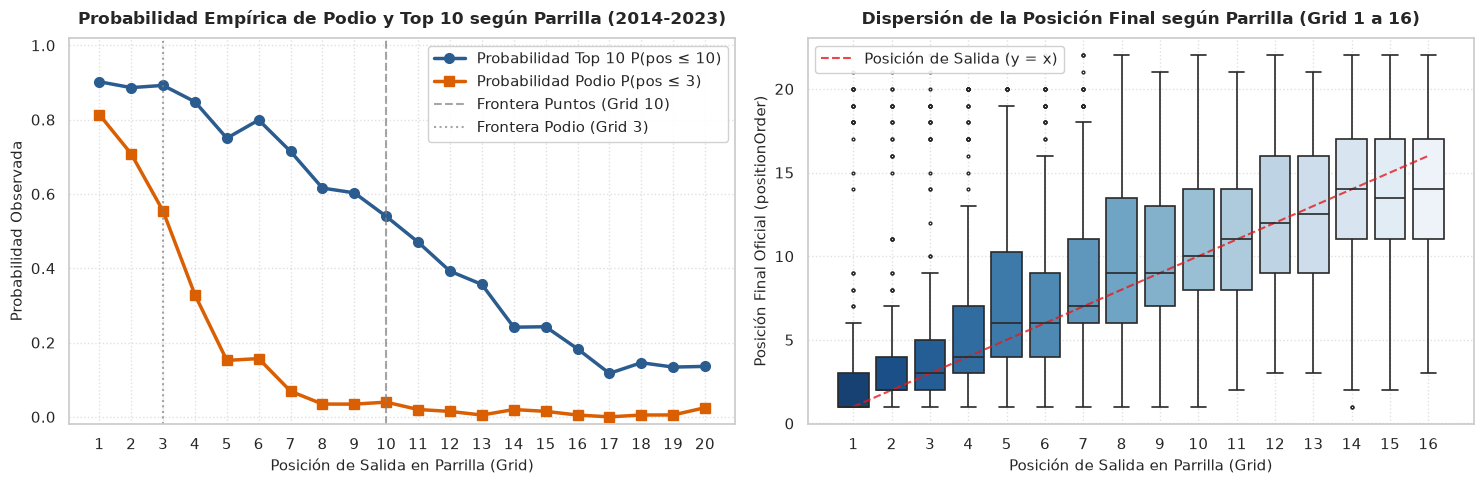

📊 Métricas de conversión directa desde la Pole y primeras líneas (Era Híbrida 2014-2023):
• Desde la Pole Position (Grid 1) : Podio = 81.4% | Top 10 = 90.2%
• Desde la 1ª Fila (Grid 1 y 2)    : Podio = 76.1% | Top 10 = 89.4%
• Desde el Top 4 de Parrilla      : Podio = 60.1% | Top 10 = 88.2%
• Desde fuera del Top 10 (Grid >10): Podio = 1.17% | Top 10 = 24.0%
• Salida en el Top 5 y llegada > 15º: 115 casos, de los cuales el 93.9% son abandonos (DNF)


In [4]:
# Importa la librería gráfica matplotlib.pyplot bajo el alias 'plt' para la generación de figuras y ejes.
import matplotlib.pyplot as plt

# Importa seaborn bajo el alias 'sns' para la creación de gráficos estadísticos avanzados y elegantes.
import seaborn as sns

# Importa numpy para operaciones matemáticas y matriciales eficientes.
import numpy as np

# Importa pandas para la agregación, filtrado y transformación de los datos tabulares.
import pandas as pd

# Cruza 'results' con 'races' para obtener el año de cada Gran Premio y acotar la muestra analítica.
df_analisis_eda = dfs['results'].merge(dfs['races'][['raceId', 'year', 'name', 'circuitId']], on='raceId')

# Filtra exclusivamente la muestra de desarrollo/entrenamiento histórico (era híbrida moderna: 2014 a 2023).
df_train_eda = df_analisis_eda.query("year >= 2014 and year <= 2023 and grid > 0").copy()

# Crea la variable binaria indicadora de si el piloto finalizó en el podio (posiciones 1, 2 o 3).
df_train_eda['es_podio'] = (df_train_eda['positionOrder'] <= 3).astype(int)

# Crea la variable binaria indicadora de si el piloto finalizó en los puntos / top 10 (posiciones 1 a 10).
df_train_eda['es_top10'] = (df_train_eda['positionOrder'] <= 10).astype(int)

# Calcula la ganancia o pérdida neta de posiciones en carrera (valor positivo indica remontada hacia adelante).
df_train_eda['delta_posiciones'] = df_train_eda['grid'] - df_train_eda['positionOrder']

# Agrupa por posición de salida en parrilla (limitado a los 20 primeros puestos habituales) para calcular tasas de conversión.
conversion_grid = df_train_eda.query("grid <= 20").groupby('grid').agg(
    prob_podio=('es_podio', 'mean'),
    prob_top10=('es_top10', 'mean'),
    pos_mediana=('positionOrder', 'median'),
    participaciones=('resultId', 'count')
).reset_index()

# Configura una figura de dos subgráficos horizontales de alta resolución para visualizar la conversión y la dispersión.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Subgráfico 1: Curva de Conversión de Parrilla a Podio y Top 10 ---
# Dibuja la curva escalonada de probabilidad de Top 10 según la posición en parrilla.
axes[0].plot(conversion_grid['grid'], conversion_grid['prob_top10'], 'o-', color='#2b5c8f', lw=2.5, markersize=7, label='Probabilidad Top 10 P(pos ≤ 10)')

# Dibuja la curva de probabilidad de Podio según la posición en parrilla.
axes[0].plot(conversion_grid['grid'], conversion_grid['prob_podio'], 's-', color='#d95f02', lw=2.5, markersize=7, label='Probabilidad Podio P(pos ≤ 3)')

# Añade una línea vertical de referencia visual delimitando la zona de puntos natural (grid = 10).
axes[0].axvline(10, color='gray', linestyle='--', alpha=0.7, label='Frontera Puntos (Grid 10)')

# Añade una línea vertical de referencia visual delimitando la zona de podio natural (grid = 3).
axes[0].axvline(3, color='gray', linestyle=':', alpha=0.7, label='Frontera Podio (Grid 3)')

# Establece el título y etiquetas del primer eje.
axes[0].set_title("Probabilidad Empírica de Podio y Top 10 según Parrilla (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Posición de Salida en Parrilla (Grid)", fontsize=11)
axes[0].set_ylabel("Probabilidad Observada", fontsize=11)
axes[0].set_xticks(range(1, 21))
axes[0].set_ylim(-0.02, 1.02)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Subgráfico 2: Diagrama de Caja (Boxplot) de Posición Final por Parrilla ---
# Genera un boxplot mostrando la dispersión y rango intercuartílico de positionOrder para cada posición de salida.
sns.boxplot(
    data=df_train_eda.query("grid <= 16"),
    x='grid',
    y='positionOrder',
    ax=axes[1],
    palette='Blues_r',
    fliersize=2,
    linewidth=1.2
)

# Traza una línea diagonal y = x indicando la posición donde un piloto terminaría exactamente donde salió.
axes[1].plot(range(0, 16), range(1, 17), '--', color='#e41a1c', lw=1.5, alpha=0.8, label='Posición de Salida (y = x)')

# Establece el título y etiquetas del segundo eje.
axes[1].set_title("Dispersión de la Posición Final según Parrilla (Grid 1 a 16)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Posición de Salida en Parrilla (Grid)", fontsize=11)
axes[1].set_ylabel("Posición Final Oficial (positionOrder)", fontsize=11)
axes[1].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Ajusta el espaciado entre subgráficos de forma óptima.
plt.tight_layout()

# Muestra la figura generada por pantalla.
plt.show()

# Imprime un resumen numérico clave de la conversión desde las primeras filas de la parrilla.
print("📊 Métricas de conversión directa desde la Pole y primeras líneas (Era Híbrida 2014-2023):")
print(f"• Desde la Pole Position (Grid 1) : Podio = {conversion_grid.loc[0, 'prob_podio']*100:.1f}% | Top 10 = {conversion_grid.loc[0, 'prob_top10']*100:.1f}%")
print(f"• Desde la 1ª Fila (Grid 1 y 2)    : Podio = {conversion_grid.loc[:1, 'prob_podio'].mean()*100:.1f}% | Top 10 = {conversion_grid.loc[:1, 'prob_top10'].mean()*100:.1f}%")
print(f"• Desde el Top 4 de Parrilla      : Podio = {conversion_grid.loc[:3, 'prob_podio'].mean()*100:.1f}% | Top 10 = {conversion_grid.loc[:3, 'prob_top10'].mean()*100:.1f}%")
print(f"• Desde fuera del Top 10 (Grid >10): Podio = {df_train_eda.query('grid > 10')['es_podio'].mean()*100:.2f}% | Top 10 = {df_train_eda.query('grid > 10')['es_top10'].mean()*100:.1f}%")

# Cuantifica qué parte de los 'desplomes' desde las primeras posiciones se debe a abandonos (DNF) y no a ritmo.
mapa_status = dfs['status'].set_index('statusId')['status']
cola_top5 = df_train_eda.query("grid <= 5 and positionOrder > 15")
termino_cola = (cola_top5['statusId'] == 1) | cola_top5['statusId'].map(mapa_status).str.startswith('+')
print(f"• Salida en el Top 5 y llegada > 15º: {len(cola_top5)} casos, de los cuales el {(~termino_cola).mean()*100:.1f}% son abandonos (DNF)")

#### **💡 Conclusiones del Análisis de Parrilla (Sección 3.1)**

Del análisis exploratorio de la variable `grid` se desprenden tres realidades clave:

1. **La Pole Position es un pasaporte casi seguro al podio:**
   - En la era híbrida moderna (2014–2023), el piloto que sale desde la **Pole Position finaliza en el podio el 81.4% de las veces** y en los puntos el **90.2%**.
   - Salir en la primera fila (`grid` 1 o 2) da una probabilidad media de podio del **76.1%** (81.4% desde la pole y 70.8% desde el 2º cajón).

2. **La caída abrupta de la probabilidad de podio tras el cajón 3:**
   - La curva de $p_\text{podio}$ cae del 81.4% en la pole al **55.4% en el cajón 3**, al **32.8% en el cajón 4** y a un **~15% en los cajones 5 y 6**; desde el cajón 7 baja del 7% y entre los cajones 8 y 10 se queda en torno al **3–4%**.
   - Para pilotos que salen fuera del Top 10 (`grid > 10`), subir al podio es un evento excepcional (**1.17%** de los casos), aunque todavía puntúan el **24.0%** de las veces.

3. **Inercia de la posición y asimetría de dispersión:**
   - La mediana de la posición de llegada coincide con el cajón de salida en 8 de las 10 primeras posiciones (en los cajones 5 y 8 la mediana es un puesto peor).
   - La cola hacia posiciones altas en los primeros cajones está dominada por **abandonos**: de los 115 casos en que un piloto salió en el Top 5 y terminó más allá del 15º, el **93.9% fueron DNF**, no pérdidas de ritmo en pista.

### **3.2 🏎️ Rendimiento por constructor, fiabilidad y tasas de abandono (DNF)**

En la Fórmula 1 moderna el factor mecánico y de ingeniería de la escudería es tanto o más determinante que las manos del piloto. En este apartado exploramos:
1. **La jerarquía competitiva de las escuderías:** Tasa histórica de victorias, podios y puntos de cada constructor en la era moderna.
2. **La fiabilidad y anatomía de los abandonos (DNF):** ¿Qué porcentaje de abandonos se debe a averías mecánicas frente a accidentes en pista?
3. **Evolución temporal de la fiabilidad:** ¿Se ha vuelto la F1 más fiable con el paso de los años?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


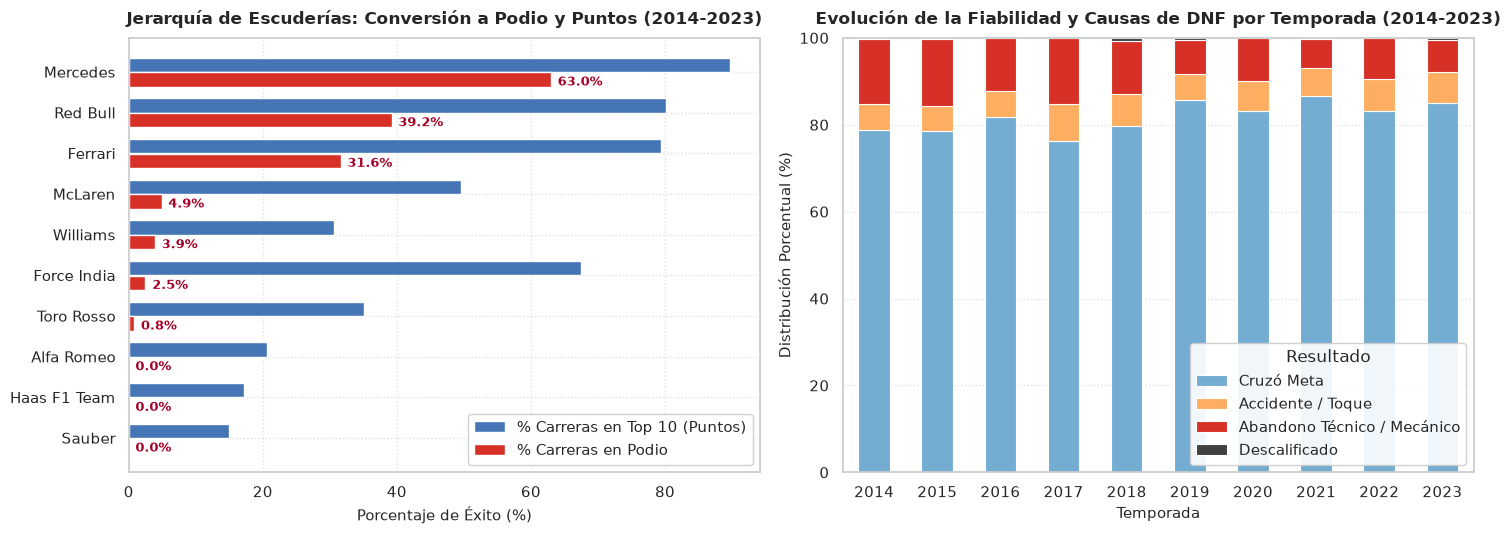

🛠️ Diagnóstico de Fiabilidad Global en la Era Híbrida (2014-2023):
• Tasa media de abandono (DNF total)     : 18.01% (aprox. 3.7 monoplazas abandonan por GP)
• Abandonos técnicos y otros            : 11.04% de las participaciones
• Accidentes / salidas / daños por toque: 6.73% de las participaciones
• Escudería más dominante (podios)       : Mercedes (63.0% de podios)
• Tasa de DNF por temporada              : máx 23.8% (2017) | mín 13.4% (2021) | 2023: 15.0%
• Estados más frecuentes en 'Abandono Técnico / Mecánico':
status
Engine        76
Brakes        47
Power Unit    41
Retired       41
Gearbox       39
Suspension    25
Electrical    14
Hydraulics    14


In [5]:
# Une 'results' con 'constructors', 'races' y 'status' para caracterizar a cada escudería y sus motivos de finalización.
df_const_eda = dfs['results'].merge(dfs['races'][['raceId', 'year']], on='raceId') \
                             .merge(dfs['constructors'][['constructorId', 'name']], on='constructorId', suffixes=('', '_constructor')) \
                             .merge(dfs['status'][['statusId', 'status']], on='statusId')

# Filtra la muestra histórica de entrenamiento en la era híbrida (2014 a 2023).
df_const_train = df_const_eda.query("year >= 2014 and year <= 2023").copy()

# Identifica si el piloto cruzó la meta con vuelta cumplida (statusId 1 o diferencias de vueltas '+N Laps').
termino_carrera = (df_const_train['statusId'] == 1) | (df_const_train['status'].str.startswith('+'))

# Asigna la categoría de finalización o abandono según la causa descrita en la tabla 'status'.
df_const_train['categoria_carrera'] = 'Abandono Técnico / Mecánico'
df_const_train.loc[termino_carrera, 'categoria_carrera'] = 'Cruzó Meta'
df_const_train.loc[df_const_train['status'].isin(['Accident', 'Collision', 'Spun off', 'Collision damage']), 'categoria_carrera'] = 'Accidente / Toque'
df_const_train.loc[df_const_train['status'].isin(['Disqualified', 'Excluded']), 'categoria_carrera'] = 'Descalificado'

# Crea banderas booleanas para la presencia en podio y top 10.
df_const_train['es_podio'] = (df_const_train['positionOrder'] <= 3).astype(int)
df_const_train['es_top10'] = (df_const_train['positionOrder'] <= 10).astype(int)
df_const_train['es_dnf'] = (~termino_carrera).astype(int)

# Selecciona los 10 constructores con mayor volumen de participaciones en la era híbrida para una comparación homogénea.
top_constructores = df_const_train['name'].value_counts().head(10).index

# Agrega las estadísticas principales de rendimiento y fiabilidad por escudería.
resumen_const = df_const_train[df_const_train['name'].isin(top_constructores)].groupby('name').agg(
    tasa_podio=('es_podio', 'mean'),
    tasa_top10=('es_top10', 'mean'),
    tasa_dnf=('es_dnf', 'mean'),
    total_carreras=('resultId', 'count')
).reset_index().sort_values('tasa_podio', ascending=False)

# Configura una figura de dos subgráficos horizontales para visualizar jerarquía de podios y la distribución de abandonos.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- Subgráfico 1: Tasa de Podio y Top 10 por Escudería ---
# Posiciona las barras horizontales para cada escudería según su porcentaje de llegada en el Top 10.
y_pos = np.arange(len(resumen_const))
axes[0].barh(y_pos - 0.18, resumen_const['tasa_top10'] * 100, height=0.35, color='#4575b4', label='% Carreras en Top 10 (Puntos)')

# Posiciona las barras horizontales para cada escudería según su porcentaje de llegada al Podio.
axes[0].barh(y_pos + 0.18, resumen_const['tasa_podio'] * 100, height=0.35, color='#d73027', label='% Carreras en Podio')

# Configura las etiquetas de las escuderías en el eje Y y titula el gráfico.
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(resumen_const['name'], fontsize=10.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Porcentaje de Éxito (%)", fontsize=11)
axes[0].set_title("Jerarquía de Escuderías: Conversión a Podio y Puntos (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Añade etiquetas de texto con el valor porcentual en las barras de podio para máxima legibilidad.
for i, v in enumerate(resumen_const['tasa_podio'] * 100):
    axes[0].text(v + 1, i + 0.25, f"{v:.1f}%", va='center', fontsize=9, fontweight='semibold', color='#a50026')

# --- Subgráfico 2: Evolución Temporal de la Fiabilidad (Tasa de Finalización y Desglose DNF) ---
# Agrupa por temporada para medir la tasa de pilotos que cruzan la meta y los tipos de averías.
evol_dnf = df_const_train.groupby(['year', 'categoria_carrera']).size().unstack(fill_value=0)
evol_dnf_pct = evol_dnf.div(evol_dnf.sum(axis=1), axis=0) * 100

# Dibuja un gráfico de barras apiladas mostrando la composición de los resultados por temporada.
colores_dnf = {'Cruzó Meta': '#74add1', 'Accidente / Toque': '#fdae61', 'Abandono Técnico / Mecánico': '#d73027', 'Descalificado': '#404040'}
columnas_apiladas = [c for c in ['Cruzó Meta', 'Accidente / Toque', 'Abandono Técnico / Mecánico', 'Descalificado'] if c in evol_dnf_pct.columns]
evol_dnf_pct[columnas_apiladas].plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    color=[colores_dnf[c] for c in columnas_apiladas],
    edgecolor='white',
    linewidth=0.8
)

# Configura títulos, límites y leyenda del gráfico de fiabilidad temporal.
axes[1].set_title("Evolución de la Fiabilidad y Causas de DNF por Temporada (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Temporada", fontsize=11)
axes[1].set_ylabel("Distribución Porcentual (%)", fontsize=11)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].set_ylim(0, 100)
axes[1].legend(title="Resultado", loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.6, axis='y')

# Ajusta márgenes y espaciado de la figura.
plt.tight_layout()

# Renderiza la figura por pantalla.
plt.show()

# Imprime un diagnóstico analítico cuantitativo de los abandonos en la era moderna.
tasa_abandono_global = df_const_train['es_dnf'].mean() * 100
tasa_abandono_mecanico = (df_const_train['categoria_carrera'] == 'Abandono Técnico / Mecánico').mean() * 100
tasa_abandono_accidente = (df_const_train['categoria_carrera'] == 'Accidente / Toque').mean() * 100

print(f"🛠️ Diagnóstico de Fiabilidad Global en la Era Híbrida (2014-2023):")
dnf_por_gp = df_const_train.groupby('raceId')['es_dnf'].sum().mean()
print(f"• Tasa media de abandono (DNF total)     : {tasa_abandono_global:.2f}% (aprox. {dnf_por_gp:.1f} monoplazas abandonan por GP)")
print(f"• Abandonos técnicos y otros            : {tasa_abandono_mecanico:.2f}% de las participaciones")
print(f"• Accidentes / salidas / daños por toque: {tasa_abandono_accidente:.2f}% de las participaciones")
print(f"• Escudería más dominante (podios)       : {resumen_const.iloc[0]['name']} ({resumen_const.iloc[0]['tasa_podio']*100:.1f}% de podios)")

# Resume la variación anual de la tasa de abandonos para comprobar si es estable entre temporadas.
dnf_anual = df_const_train.groupby('year')['es_dnf'].mean() * 100
print(f"• Tasa de DNF por temporada              : máx {dnf_anual.max():.1f}% ({dnf_anual.idxmax()}) | mín {dnf_anual.min():.1f}% ({dnf_anual.idxmin()}) | {YEAR_VAL}: {dnf_anual.loc[YEAR_VAL]:.1f}%")

# Muestra qué estados concretos componen la categoría 'Abandono Técnico / Mecánico' (categoría por defecto).
print("• Estados más frecuentes en 'Abandono Técnico / Mecánico':")
print(df_const_train.query("categoria_carrera == 'Abandono Técnico / Mecánico'")['status'].value_counts().head(8).to_string())

#### **💡 Conclusiones del Análisis de Constructores y Fiabilidad (Sección 3.2)**

Del estudio de las escuderías y la anatomía de los abandonos obtenemos tres conclusiones operativas para la ingeniería de variables:

1. **Hiperpolarización de los podios por escudería (*Efecto Coche*):**
   - En la era híbrida, los podios están acaparados por el trío hegemónico: **Mercedes (63.0%** de sus participaciones en podio), **Red Bull (39.2%)** y **Ferrari (31.6%)**. El siguiente, McLaren, se queda en un **4.9%**.
   - Para el resto de la parrilla la probabilidad de podio es residual: Williams 3.9%, Force India 2.5%, Toro Rosso 0.8% y **Haas, Alfa Romeo y Sauber 0%**. **El ritmo histórico de la escudería es un predictor obligatorio de primer orden.**
   - Matiz: el gráfico agrega 2014–2023 y oculta los cambios de dominio entre temporadas (Mercedes 2014–2020, Red Bull 2022–2023). Además, el dataset asigna `constructorId` distintos a una misma estructura cuando cambia de nombre (Toro Rosso → AlphaTauri, Force India → Racing Point → Aston Martin), lo que fragmentaría su historial. En el Bloque 4 lo resolvemos calculando las variables del constructor por **linaje de escudería** (`team_lineage`).

2. **La tasa de DNF ronda el 18%, pero ni es constante ni se reparte por igual:**
   - De media, **el 18.0% de los monoplazas no ve la bandera a cuadros** (~3.7 coches por carrera).
   - **Varía bastante entre temporadas**: del 23.8% en 2017 al 13.4% en 2021 (15.0% en 2023), con tendencia a la baja en las últimas temporadas.
   - **El reparto no es simétrico**: un **11.0%** son abandonos técnicos y otros (motor, frenos, *power unit*, caja de cambios… aunque la categoría también incluye estados genéricos como `Retired` o `Withdrew`), frente a un **6.7%** de accidentes y toques y un 0.2% de descalificaciones.

3. **Implicación matemática para la Parte 2 (Posición Final):**
   - Cuando un piloto abandona, el target oficial `positionOrder` no le asigna nulo: lo clasifica al final de la tabla según el número de vueltas completadas antes de retirarse.
   - Por tanto, el riesgo de DNF del coche (`con_dnf_roll5`, `con_mech_dnf_roll10`) y del circuito (`circ_hist_dnf_rate`) es relevante no solo para los podios, sino también para la cola de posiciones finales.

### **3.3 🏁 Tipología de circuito: dificultad de adelantamiento y tasa de abandonos**

La posición en parrilla (`grid`) no tiene el mismo poder predictivo en todos los trazados. En circuitos urbanos y estrechos (como Mónaco o Singapur), adelantar en pista es extraordinariamente complejo y la clasificación condiciona de forma casi irreversible el resultado final; en trazados permanentes con largas rectas y zonas de DRS (como Spa, Monza o Austin), las remontadas son mucho más viables.

En este apartado exploramos:
1. **La inercia de la parrilla por circuito:** Correlación de Spearman entre `grid` y `positionOrder` para los trazados habituales de la era híbrida.
2. **El factor caos y tasa de abandonos (DNF):** Circuitos donde los incidentes y Safety Cars alteran drásticamente el orden natural de salida.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


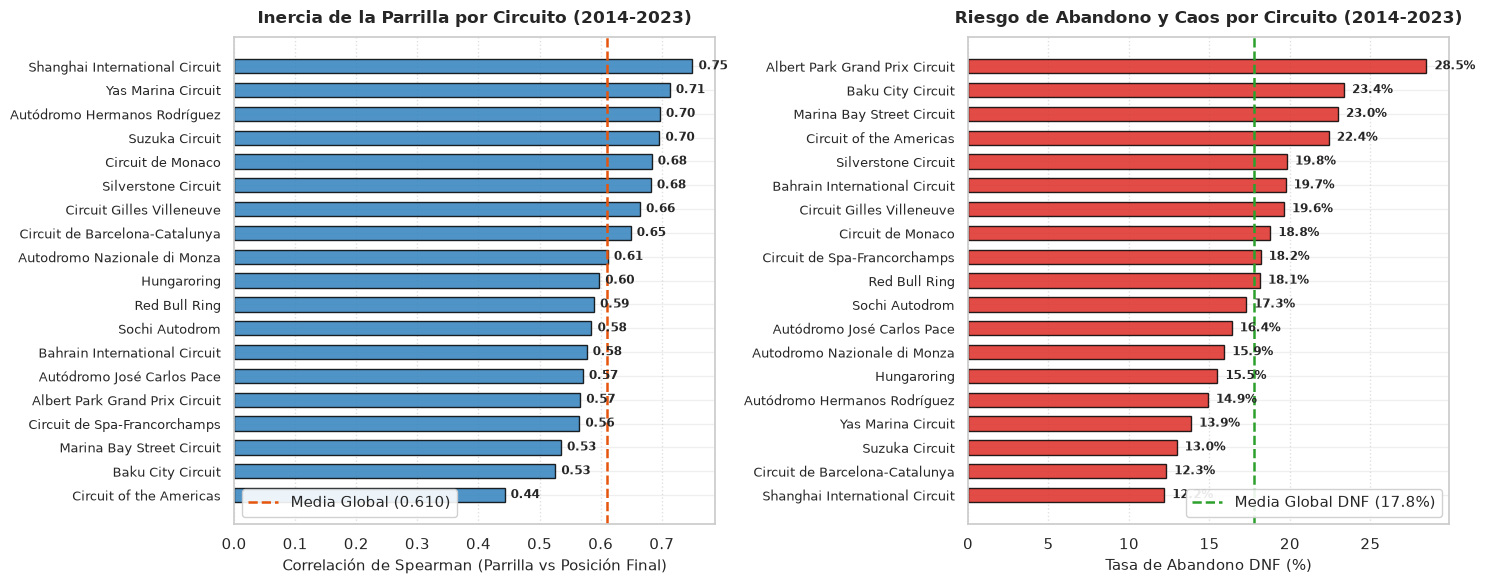

🏁 Diagnóstico de Circuitos:
• Circuito con mayor inercia de parrilla  : Shanghai International Circuit (Corr = 0.750)
• Circuito más abierto a remontadas      : Circuit of the Americas (Corr = 0.443)
• Circuito con mayor tasa de abandono/caos: Albert Park Grand Prix Circuit (28.5% DNF)


In [6]:
# Cruza 'results' con 'races', 'circuits' y 'status' para caracterizar el comportamiento histórico por trazado.
df_circ_eda = dfs['results'].merge(dfs['races'][['raceId', 'year', 'circuitId']], on='raceId') \
                            .merge(dfs['circuits'][['circuitId', 'name']], on='circuitId', suffixes=('', '_circuito')) \
                            .merge(dfs['status'][['statusId', 'status']], on='statusId')

# Filtra la muestra histórica de entrenamiento en la era híbrida moderna con salidas válidas en parrilla.
df_circ_train = df_circ_eda.query("year >= 2014 and year <= 2023 and grid > 0").copy()

# Marca como abandono (DNF) a los pilotos que no finalizaron por avería mecánica o accidente en pista.
df_circ_train['es_dnf'] = (~((df_circ_train['statusId'] == 1) | (df_circ_train['status'].str.startswith('+')))).astype(int)

# Calcula por circuito la correlación de Spearman (grid vs posición final), la tasa de DNF y el volumen de carreras.
resumen_circuitos = []
for nombre_circuito, grupo in df_circ_train.groupby('name'):
    n_carreras = grupo['raceId'].nunique()
    if n_carreras >= 6:  # Exige un mínimo de 6 Grandes Premios para estabilidad estadística
        corr_spearman = grupo[['grid', 'positionOrder']].corr(method='spearman').iloc[0, 1]
        tasa_abandono = grupo['es_dnf'].mean()
        resumen_circuitos.append({
            'circuito': nombre_circuito,
            'corr_grid_pos': corr_spearman,
            'tasa_dnf': tasa_abandono,
            'n_carreras': n_carreras
        })

# Convierte la lista agregada a DataFrame y la ordena de mayor a menor correlación de parrilla.
df_resumen_circ = pd.DataFrame(resumen_circuitos).sort_values('corr_grid_pos', ascending=False)

# Configura una figura de dos subgráficos horizontales para visualizar la dificultad de adelantamiento y el riesgo de abandono.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Subgráfico 1: Correlación de Spearman Grid vs Posición Final por Circuito ---
# Genera un gráfico de barras horizontales mostrando la correlación de Spearman por circuito.
y_pos = np.arange(len(df_resumen_circ))
barras_corr = axes[0].barh(y_pos, df_resumen_circ['corr_grid_pos'], color='#3182bd', edgecolor='black', alpha=0.85, height=0.6)

# Añade una línea vertical de referencia indicando la correlación media global en la era híbrida.
corr_global = df_circ_train[['grid', 'positionOrder']].corr(method='spearman').iloc[0, 1]
axes[0].axvline(corr_global, color='#e6550d', linestyle='--', lw=1.8, label=f'Media Global ({corr_global:.3f})')

# Configura ejes, etiquetas y título del primer panel.
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_resumen_circ['circuito'], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Correlación de Spearman (Parrilla vs Posición Final)", fontsize=11)
axes[0].set_title("Inercia de la Parrilla por Circuito (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle=':', alpha=0.6, axis='x')

# Imprime el valor numérico de correlación junto a cada barra.
for i, v in enumerate(df_resumen_circ['corr_grid_pos']):
    axes[0].text(v + 0.01, i, f"{v:.2f}", va='center', fontsize=8.5, fontweight='semibold')

# --- Subgráfico 2: Tasa Histórica de Abandonos (DNF) por Circuito ---
# Ordena por tasa de abandono de mayor a menor para el segundo gráfico.
df_resumen_dnf = df_resumen_circ.sort_values('tasa_dnf', ascending=False)
y_pos_dnf = np.arange(len(df_resumen_dnf))
barras_dnf = axes[1].barh(y_pos_dnf, df_resumen_dnf['tasa_dnf'] * 100, color='#de2d26', edgecolor='black', alpha=0.85, height=0.6)

# Añade una línea vertical de referencia con la tasa media de abandono global (~18%).
tasa_dnf_global = df_circ_train['es_dnf'].mean() * 100
axes[1].axvline(tasa_dnf_global, color='#2ca02c', linestyle='--', lw=1.8, label=f'Media Global DNF ({tasa_dnf_global:.1f}%)')

# Configura ejes, etiquetas y título del segundo panel.
axes[1].set_yticks(y_pos_dnf)
axes[1].set_yticklabels(df_resumen_dnf['circuito'], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Tasa de Abandono DNF (%)", fontsize=11)
axes[1].set_title("Riesgo de Abandono y Caos por Circuito (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.6, axis='x')

# Imprime el valor numérico porcentual junto a cada barra de abandono.
for i, v in enumerate(df_resumen_dnf['tasa_dnf'] * 100):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=8.5, fontweight='semibold')

# Ajusta el diseño de los subgráficos.
plt.tight_layout()

# Renderiza la figura por pantalla.
plt.show()

# Imprime un resumen de los circuitos extremos en inercia de parrilla y tasa de abandonos.
circ_mas_procesion = df_resumen_circ.iloc[0]
circ_mas_remontadas = df_resumen_circ.iloc[-1]
circ_mas_caotico = df_resumen_dnf.iloc[0]
print(f"🏁 Diagnóstico de Circuitos:")
print(f"• Circuito con mayor inercia de parrilla  : {circ_mas_procesion['circuito']} (Corr = {circ_mas_procesion['corr_grid_pos']:.3f})")
print(f"• Circuito más abierto a remontadas      : {circ_mas_remontadas['circuito']} (Corr = {circ_mas_remontadas['corr_grid_pos']:.3f})")
print(f"• Circuito con mayor tasa de abandono/caos: {circ_mas_caotico['circuito']} ({circ_mas_caotico['tasa_dnf']*100:.1f}% DNF)")

#### **💡 Conclusiones del Análisis de Circuitos (Sección 3.3)**

El comportamiento del Gran Premio depende críticamente de la pista donde se disputa:

1. **La parrilla pesa mucho más en unos trazados que en otros:**
   - Circuitos como **Shanghai (0.750)**, **Yas Marina (0.713)**, **Hermanos Rodríguez (0.697)**, **Suzuka (0.696)** y **Mónaco (0.683)** muestran la mayor correlación entre la salida y la meta (media global de la era híbrida: línea discontinua del gráfico).
   - En el otro extremo, **Circuit of the Americas (0.443)**, **Baku (0.526)**, **Marina Bay (0.535)** y **Spa-Francorchamps (0.565)** son trazados donde el orden de salida se altera mucho más, ya sea por adelantamientos (rectas largas, DRS, degradación) o por incidentes y Safety Cars.

2. **La tasa de DNF varía entre el 12% y el 28% según el trazado:**
   - **Albert Park (28.5%)**, **Baku (23.4%)**, **Marina Bay (23.0%)** y **COTA (22.4%)** están claramente por encima de la media global (17.8%); Albert Park la supera en un 60%. En el extremo opuesto, Shanghai (12.2%) y Barcelona (12.3%).
   - Los circuitos urbanos con muros cercanos (Baku, Singapur, Albert Park) concentran el riesgo de abandono.
   - **Implicación directa para el modelo:** en el Bloque 4 se crean `circ_hist_dnf_rate` y `circ_hist_overtake_delta`, calculadas solo con las ediciones anteriores del mismo circuito, para modular la incertidumbre según el fin de semana. Con 6–12 ediciones por circuito, estas medias son ruidosas y conviene no sobreinterpretarlas.

### **3.4 ⏱️ Ritmo puro en clasificación: brecha de tiempo a la pole (`q_gap_pct`)**

Dos pilotos pueden clasificar contiguos en la parrilla (por ejemplo, 3º y 4º), pero encontrarse en situaciones de competitividad diametralmente opuestas:
- Si el 3º se quedó a **+0.080s** de la pole, su ritmo puro es equiparable al del coche puntero.
- Si el 4º se quedó a **+1.200s** porque la Q3 se disputó sobre mojado o aprovechó una bandera amarilla, su ritmo real de carrera es sustancialmente inferior.

En este apartado exploramos:
1. **La brecha temporal porcentual respecto a la Pole Position:** $\text{q\_gap\_pct} = \frac{\text{tiempo\_propio} - \text{tiempo\_pole}}{\text{tiempo\_pole}} \times 100$.
2. **La conversión a podio y puntos según quintiles de brecha:** ¿Cómo discrimina la brecha de tiempo la probabilidad de éxito el domingo?

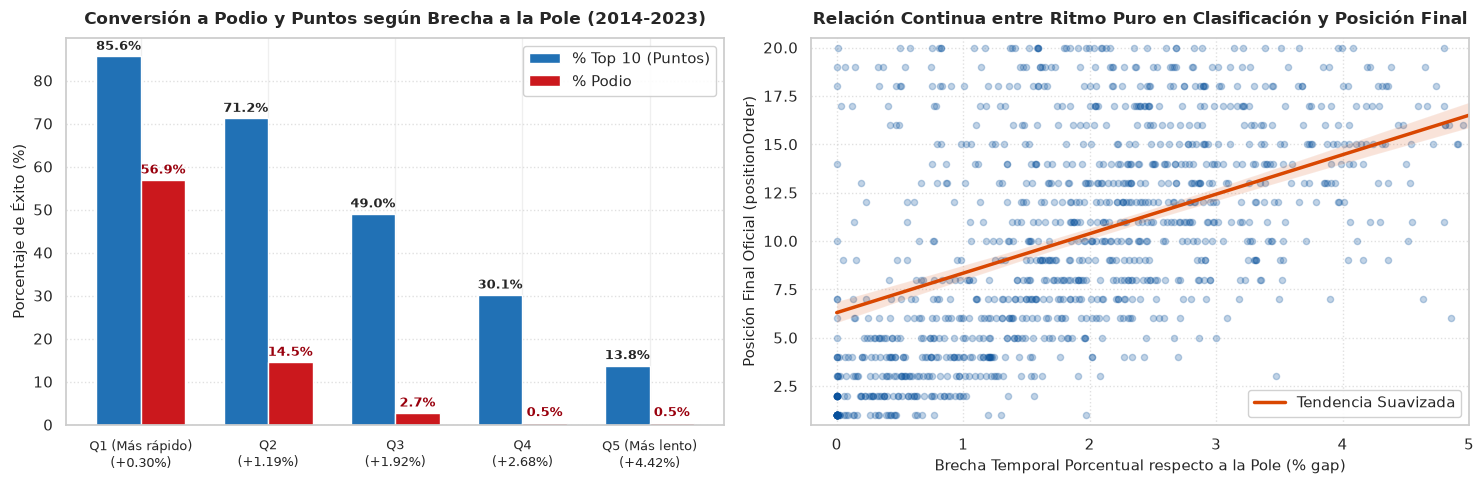

⏱️ Diagnóstico de Brechas en Clasificación:
• Quintil 1 (≤ +0.77% de la Pole)       : Podio = 56.9% | Top 10 = 85.6%
• Quintil 2 (+0.77% a +1.57% de la Pole) : Podio = 14.5% | Top 10 = 71.2%
• Quintil 3 (+1.57% a +2.29% de la Pole) : Podio = 2.7% | Top 10 = 49.0%
• Quintiles 4-5 (> +2.29% de la Pole)   : Podio = 0.50% | Top 10 = 22.0%


In [7]:
# Cruza la tabla de clasificación 'qualifying' con 'results' y 'races' para medir tiempos y gaps de fin de semana.
df_q_eda = dfs['qualifying'].merge(dfs['results'][['raceId', 'driverId', 'positionOrder']], on=['raceId', 'driverId']) \
                           .merge(dfs['races'][['raceId', 'year']], on='raceId')

# Filtra la muestra de la era híbrida moderna (2014 a 2023).
df_q_train = df_q_eda.query("year >= 2014 and year <= 2023").copy()

# Define una función auxiliar para transformar cadenas de tiempo de F1 ('m:ss.sss' o 'ss.sss') a segundos flotantes.
def tiempo_a_segundos(cadena_tiempo):
    if pd.isna(cadena_tiempo) or cadena_tiempo == r'\N' or not isinstance(cadena_tiempo, str):
        return np.nan
    try:
        partes = cadena_tiempo.split(':')
        if len(partes) == 2:
            return float(partes[0]) * 60.0 + float(partes[1])
        elif len(partes) == 1:
            return float(partes[0])
    except:
        return np.nan

# Convierte los mejores tiempos de cada una de las sesiones de clasificación (Q1, Q2, Q3) a segundos numéricos.
df_q_train['q1_sec'] = df_q_train['q1'].apply(tiempo_a_segundos)
df_q_train['q2_sec'] = df_q_train['q2'].apply(tiempo_a_segundos)
df_q_train['q3_sec'] = df_q_train['q3'].apply(tiempo_a_segundos)

# Extrae el mejor tiempo absoluto registrado por el piloto en cualquier sesión clasificatoria en la que participó.
df_q_train['mejor_q_sec'] = df_q_train[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)

# Calcula para cada Gran Premio el tiempo de la Pole Position (el mejor tiempo absoluto de la sesión).
tiempo_pole_por_carrera = df_q_train.groupby('raceId')['mejor_q_sec'].transform('min')

# Calcula la brecha porcentual del piloto con respecto al tiempo de la Pole Position en ese Gran Premio.
df_q_train['q_gap_pct'] = ((df_q_train['mejor_q_sec'] - tiempo_pole_por_carrera) / tiempo_pole_por_carrera) * 100.0

# Elimina registros con tiempos no válidos o anomalías extremas (> 15% por banderas rojas o lluvia cambiante).
df_q_validos = df_q_train.query("q_gap_pct.notnull() and q_gap_pct <= 10.0").copy()

# Crea variables binarias indicadoras de éxito en carrera (podio y top 10).
df_q_validos['es_podio'] = (df_q_validos['positionOrder'] <= 3).astype(int)
df_q_validos['es_top10'] = (df_q_validos['positionOrder'] <= 10).astype(int)

# Segmenta la brecha temporal en 5 quintiles homogéneos para estudiar su relación escalonada con el éxito en carrera.
df_q_validos['quintil_gap'] = pd.qcut(df_q_validos['q_gap_pct'], 5, labels=['Q1 (Más rápido)', 'Q2', 'Q3', 'Q4', 'Q5 (Más lento)'])

# Agrega la tasa de podio, la tasa de puntos y la mediana de posición de carrera por quintil de brecha temporal.
resumen_gap = df_q_validos.groupby('quintil_gap', observed=False).agg(
    gap_medio=('q_gap_pct', 'mean'),
    tasa_podio=('es_podio', 'mean'),
    tasa_top10=('es_top10', 'mean'),
    pos_mediana=('positionOrder', 'median'),
    participaciones=('raceId', 'count')
).reset_index()

# Configura una figura de dos subgráficos horizontales para visualizar la relación entre la brecha porcentual y el éxito.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Subgráfico 1: Probabilidad de Podio y Top 10 por Quintil de Brecha Temporal ---
x_ind = np.arange(len(resumen_gap))
ancho_barra = 0.35

# Dibuja las barras de probabilidad de Top 10 por quintil.
axes[0].bar(x_ind - ancho_barra/2, resumen_gap['tasa_top10'] * 100, width=ancho_barra, color='#2171b5', label='% Top 10 (Puntos)')

# Dibuja las barras de probabilidad de Podio por quintil.
axes[0].bar(x_ind + ancho_barra/2, resumen_gap['tasa_podio'] * 100, width=ancho_barra, color='#cb181d', label='% Podio')

# Configura ejes, etiquetas y título del primer panel.
axes[0].set_xticks(x_ind)
axes[0].set_xticklabels([f"{r['quintil_gap']}\n(+{r['gap_medio']:.2f}%)" for _, r in resumen_gap.iterrows()], fontsize=9.5)
axes[0].set_ylabel("Porcentaje de Éxito (%)", fontsize=11)
axes[0].set_title("Conversión a Podio y Puntos según Brecha a la Pole (2014-2023)", fontsize=12, fontweight='bold', pad=10)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle=':', alpha=0.6, axis='y')

# Inserta etiquetas de texto con el porcentaje exacto sobre las barras para facilitar la lectura.
for i, r in resumen_gap.iterrows():
    axes[0].text(i - ancho_barra/2, r['tasa_top10'] * 100 + 1.5, f"{r['tasa_top10']*100:.1f}%", ha='center', fontsize=9, fontweight='semibold')
    axes[0].text(i + ancho_barra/2, r['tasa_podio'] * 100 + 1.5, f"{r['tasa_podio']*100:.1f}%", ha='center', fontsize=9, fontweight='semibold', color='#99000d')

# --- Subgráfico 2: Diagrama de Dispersión y Regresión (Brecha % vs Posición Final) ---
# Traza un scatter plot con línea de tendencia suavizada mostrando cómo la posición final empeora linealmente con el gap.
sns.regplot(
    data=df_q_validos.sample(n=min(1200, len(df_q_validos)), random_state=SEED),
    x='q_gap_pct',
    y='positionOrder',
    ax=axes[1],
    scatter_kws={'alpha': 0.25, 'color': '#08519c', 's': 20},
    line_kws={'color': '#d94701', 'lw': 2.5, 'label': 'Tendencia Suavizada'}
)

# Configura ejes, límites y título del segundo panel.
axes[1].set_xlabel("Brecha Temporal Porcentual respecto a la Pole (% gap)", fontsize=11)
axes[1].set_ylabel("Posición Final Oficial (positionOrder)", fontsize=11)
axes[1].set_title("Relación Continua entre Ritmo Puro en Clasificación y Posición Final", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlim(-0.2, 5.0)
axes[1].set_ylim(0.5, 20.5)
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Ajusta el diseño de los gráficos.
plt.tight_layout()

# Renderiza la figura por pantalla.
plt.show()

# Imprime las métricas cuantitativas clave de la brecha temporal en clasificación.
q1_tasa_podio = resumen_gap.iloc[0]['tasa_podio'] * 100
q2_tasa_podio = resumen_gap.iloc[1]['tasa_podio'] * 100
q3_tasa_podio = resumen_gap.iloc[2]['tasa_podio'] * 100
q1_tasa_top10 = resumen_gap.iloc[0]['tasa_top10'] * 100
# Calcula los límites superiores reales de cada quintil de brecha para etiquetar correctamente los tramos.
bordes_gap = df_q_validos.groupby('quintil_gap', observed=False)['q_gap_pct'].max()
print(f"⏱️ Diagnóstico de Brechas en Clasificación:")
print(f"• Quintil 1 (≤ +{bordes_gap.iloc[0]:.2f}% de la Pole)       : Podio = {q1_tasa_podio:.1f}% | Top 10 = {q1_tasa_top10:.1f}%")
print(f"• Quintil 2 (+{bordes_gap.iloc[0]:.2f}% a +{bordes_gap.iloc[1]:.2f}% de la Pole) : Podio = {q2_tasa_podio:.1f}% | Top 10 = {resumen_gap.iloc[1]['tasa_top10']*100:.1f}%")
print(f"• Quintil 3 (+{bordes_gap.iloc[1]:.2f}% a +{bordes_gap.iloc[2]:.2f}% de la Pole) : Podio = {q3_tasa_podio:.1f}% | Top 10 = {resumen_gap.iloc[2]['tasa_top10']*100:.1f}%")
print(f"• Quintiles 4-5 (> +{bordes_gap.iloc[2]:.2f}% de la Pole)   : Podio = {resumen_gap.iloc[3:]['tasa_podio'].mean()*100:.2f}% | Top 10 = {resumen_gap.iloc[3:]['tasa_top10'].mean()*100:.1f}%")

#### **💡 Conclusiones del Análisis de Brechas de Clasificación (Sección 3.4)**

La métrica continua `q_gap_pct` aporta una granularidad que la posición discreta de parrilla (`grid`) no puede capturar por sí sola:

1. **El umbral crítico del ~0.8% de brecha para optar al podio:**
   - Los pilotos que se clasifican a menos de un **+0.77% del tiempo de la Pole** (quintil 1) terminan en el podio el **56.9%** de las veces y en los puntos el **85.6%**.
   - En el quintil 2 (+0.77% a +1.57%) el podio cae al **14.5%**; entre +1.57% y +2.29% se desploma al **2.7%**, y por encima de **+2.29%** es prácticamente nulo (**0.50%**), con solo un **22.0%** de opciones de puntuar.

2. **Diferenciación de coches descolocados por penalizaciones (hipótesis a validar con el modelo):**
   - Si un monoplaza puntero recibe una penalización por cambio de motor y sale 15º (`grid = 15`), su `grid` sugeriría baja probabilidad de puntos, pero su `q_gap_pct` (< 0.5%) le delataría como aspirante a remontar.
   - **Implicación para el Bloque 4:** combinar `grid` con `q_gap_pct` debería ayudar al modelo en ambas partes del reto.
   - Matiz metodológico: `q_gap_pct` usa el mejor tiempo del piloto en cualquier sesión (Q1, Q2 o Q3), así que un eliminado en Q1 se compara con una pole marcada en Q3, con otra evolución de pista. La brecha de los pilotos lentos está algo inflada, aunque el orden relativo se conserva.

## **🔧 Bloque 4 · Ingeniería de Variables y Pipeline Anti-Fuga**

El éxito en la predicción de Fórmula 1 reside en **destilar toda la información histórica y del sábado por la noche sin filtrar ni un solo dato del domingo**. Mientras que un modelo ingenuo solo mira la parrilla (`grid`), un estratega de F1 cruza **seis dimensiones ortogonales** antes de apagarse el semáforo:

1. **🟢 Dimensión A — Sábado Noche y Clasificación (`t`):** Posición real de salida (`grid_clean`), salida desde *pit lane* (`is_pitlane_start`), posición pura en clasificación (`qualy_pos_clean`), sesión alcanzada (`q_session_reached`: Q1, Q2 o Q3), brecha porcentual respecto a la Pole (`q_gap_pct`), plazas de penalización sufridas (`grid_penalty_places`) y duelo directo frente al compañero de escudería el sábado (`teammate_grid_diff`, `teammate_q_gap_diff`).
2. **🟢 Dimensión B — Carrera Sprint del Sábado (`t`):** En los Grandes Premios con formato Sprint, la carrera corta se disputa el sábado antes del GP principal. Extraemos la posición en la Sprint (`sprint_pos`), puntos sumados (`sprint_points`) y posiciones remontadas en la Sprint (`sprint_delta`).
3. **🟡 Dimensión C — Estado del Campeonato del Mundo Previo (`t-1`):** Resolviendo la *"trampa clásica"*, asignamos a la ronda `round` el mundial acumulado al cierre de la ronda `round - 1` de esa misma temporada (`drv_champ_points_prev`, `drv_champ_pos_prev`, `con_champ_points_prev`, `con_champ_pos_prev`). En la **Ronda 1** de cada año, todos los pilotos y constructores parten estrictamente con `0` puntos.
4. **🟡 Dimensión D — Forma Reciente (*Momentum*) y Experiencia del Piloto (`< t`):** Medias móviles y exponenciales estrictamente desplazadas (`shift(1)`) de las últimas 3, 5 y 10 carreras disputadas por el piloto (`drv_pos_roll3`, `drv_pos_roll5`, `drv_pos_ewm5`), racha de podios y puntos (`drv_podium_roll5`, `drv_top10_roll5`), propensión a remontar (`drv_delta_roll5`), veterania acumulada (`drv_career_starts_prev`) y edad (`driver_age`). Incluye las carreras previas de 2024 cuando predecimos el resto de la temporada 2024.
5. **🟡 Dimensión E — Ritmo de Coche, Fiabilidad Mecánica y Boxes del Constructor (`< t`):** Agregación por **linaje de escudería** (`team_lineage`: una misma estructura aunque cambie de nombre, p. ej. Toro Rosso → AlphaTauri → RB) y carrera en $t-1, t-2, \dots$ para capturar el potencial real del monoplaza (`con_best_pos_roll3`, `con_mean_pos_roll5`), su tasa de roturas mecánicas (`con_mech_dnf_roll10`) y la rapidez mediana de sus mecánicos en paradas de boxes (`con_pit_ms_roll5`).
6. **🟡 Dimensión F — Afinidad Piloto-Circuito y Geometría del Trazado (`< t`):** Historial expansivo previo del piloto en ese circuito específico (`drv_circ_pos_mean`, `drv_circ_podium_rate`), altitud sobre el nivel del mar (`alt`) y métricas históricas del trazado hasta la edición anterior (`circ_hist_dnf_rate`, `circ_hist_overtake_delta`).

### **4.1 🔄 Pipeline de unión temporal y cálculo de ventanas acumuladas ($t-1$)**

Para evitar que las primeras carreras de nuestro conjunto de entrenamiento (`2014`) aparezcan artificialmente con valores vacíos en sus ventanas móviles de 3, 5 y 10 carreras, aplicamos una **ventana de calentamiento histórica (*warm-up window*) desde 2010**:
- Calculamos todas las series temporales cronológicas sobre el periodo `2010–2024` ordenando por `(year, round, raceId)` y aplicando `.shift(1)` antes de cualquier agregación `.rolling()` o `.expanding()`.
- Una vez calculadas las trayectorias históricas sin fugas, recortamos el tablón analítico exactamente al periodo de modelización de la **era híbrida (`year >= 2014`)**.
- **Linaje de escuderías (`team_lineage`):** el dataset asigna un `constructorId` nuevo cada vez que una estructura cambia de nombre (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Sauber → Alfa Romeo → Sauber, Renault → Lotus F1 → Renault → Alpine…). Si las medias móviles del constructor se calculan por `constructorId`, el historial se corta en cada cambio de nombre: en la Ronda 1 de 2024 RB llegaría **sin historial** y Sauber heredaría sus carreras de **2018**. Por eso las variables del constructor (Dimensión E) se calculan por linaje. Es un metadato estático conocido de antemano, así que no introduce fuga. El mundial de constructores (Dimensión C) no se ve afectado, porque se reinicia cada temporada y los cambios de nombre siempre ocurren entre temporadas.

In [8]:
# ==============================================================================
# 4.1 Construcción del Tablón Temporal Maestro y Ventanas Acumuladas (< t)
# ==============================================================================

# Selecciona las columnas clave de calendario y circuito desde la tabla 'races'.
races_base = dfs['races'][['raceId', 'year', 'round', 'circuitId', 'date']].copy()

# Selecciona el diccionario de estados de finalización desde la tabla 'status'.
status_base = dfs['status'][['statusId', 'status']].copy()

# Selecciona la fecha de nacimiento de cada piloto desde la tabla 'drivers'.
drivers_base = dfs['drivers'][['driverId', 'dob']].copy()

# Selecciona las coordenadas y altitud de cada trazado desde la tabla 'circuits'.
circuits_base = dfs['circuits'][['circuitId', 'alt', 'lat', 'lng']].copy()

# Une la tabla central 'results' con las tablas dimensionales maestras (100% libres de colisión).
df_full = (
    dfs['results']
    .merge(races_base, on='raceId')
    .merge(status_base, on='statusId')
    .merge(drivers_base, on='driverId')
    .merge(circuits_base, on='circuitId')
)

# Filtra desde 2010 inclusive para dar 4 años de calentamiento (warm-up) a las ventanas móviles previas a 2014.
df_full = df_full.query("year >= 2010 and year <= @YEAR_TEST").copy()

# Ordena estrictamente de forma cronológica por año, ronda, carrera e identificador de resultado.
df_full = df_full.sort_values(['year', 'round', 'raceId', 'resultId']).reset_index(drop=True)

# Convierte la altitud del circuito a formato numérico flotante gestionando cadenas nulas ('\N').
df_full['alt'] = pd.to_numeric(df_full['alt'].replace(r'\N', np.nan), errors='coerce')

# Calcula la edad exacta del piloto (en años) en el día de celebración del Gran Premio.
df_full['race_date_dt'] = pd.to_datetime(df_full['date'], errors='coerce')
df_full['dob_dt'] = pd.to_datetime(df_full['dob'].replace(r'\N', np.nan), errors='coerce')
df_full['driver_age'] = (df_full['race_date_dt'] - df_full['dob_dt']).dt.days / 365.25

# --- Definición de los 3 Targets Oficiales del Reto ---
# Target binario Parte 1A: 1 si el piloto acaba en el podio (positionOrder <= 3), 0 en caso contrario.
df_full['y_podio'] = (df_full['positionOrder'] <= 3).astype(int)

# Target binario Parte 1B: 1 si el piloto acaba en zona de puntos (positionOrder <= 10), 0 en caso contrario.
df_full['y_top10'] = (df_full['positionOrder'] <= 10).astype(int)

# Target numérico Parte 2: posición final oficial de carrera (incluyendo retirados al final).
df_full['y_pos'] = df_full['positionOrder'].astype(float)

# --- Indicadores internos del domingo (prefijo '_' -> SOLO para desfasar con shift(1) hacia el futuro) ---
# Identifica si el piloto cruzó la meta clasificado (statusId == 1 o a '+N Laps' del líder).
termino_domingo = (df_full['statusId'] == 1) | (df_full['status'].str.startswith('+'))

# Indicador interno de abandono total (DNF) en la carrera t (prohibido en t, se usará solo con shift(1)).
df_full['_is_dnf_t'] = (~termino_domingo).astype(float)

# Indicador interno de rotura mecánica pura de la escudería en la carrera t (solo para shift(1)).
df_full['_is_mech_dnf_t'] = df_full['status'].isin([
    'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics',
    'Electrical', 'Power Unit', 'Brakes', 'Suspension', 'Overheating',
    'Oil leak', 'Water leak'
]).astype(float)

# Ganancia neta de posiciones lograda el domingo t (solo para calcular capacidad histórica de remontada con shift(1)).
df_full['_delta_pos_t'] = np.where(df_full['grid'] > 0, df_full['grid'] - df_full['positionOrder'], 0.0)

# ==============================================================================
# DIMENSIÓN A: Variables del Sábado Noche y Clasificación (Permitidas en t)
# ==============================================================================

# Define función auxiliar para transformar tiempos 'm:ss.sss' de clasificación a segundos flotantes.
def parsear_tiempo_qualy(val):
    # Si el valor es nulo o el marcador '\N' de Ergast, retorna NaN numérico.
    if pd.isna(val) or val == r'\N' or not isinstance(val, str):
        return np.nan
    try:
        # Divide la cadena por ':' para separar minutos y segundos.
        partes = val.split(':')
        if len(partes) == 2:
            return float(partes[0]) * 60.0 + float(partes[1])
        elif len(partes) == 1:
            return float(partes[0])
    except:
        return np.nan

# Extrae las sesiones de clasificación y renombra 'position' a 'qualy_pos' para evitar colisiones.
df_qualy = dfs['qualifying'][['raceId', 'driverId', 'position', 'q1', 'q2', 'q3']].copy()
df_qualy = df_qualy.rename(columns={'position': 'qualy_pos'})

# Convierte los tiempos de Q1, Q2 y Q3 a segundos en coma flotante.
for col_q in ['q1', 'q2', 'q3']:
    df_qualy[col_q + '_sec'] = df_qualy[col_q].apply(parsear_tiempo_qualy)

# Obtiene el mejor tiempo absoluto marcado por cada piloto en la clasificación del sábado.
df_qualy['best_q_sec'] = df_qualy[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)

# Codifica qué ronda de clasificación alcanzó el piloto: 3 (Q3), 2 (Q2), 1 (Q1) o 0 (sin tiempo).
df_qualy['q_session_reached'] = np.where(
    df_qualy['q3_sec'].notna(), 3,
    np.where(df_qualy['q2_sec'].notna(), 2, np.where(df_qualy['q1_sec'].notna(), 1, 0))
)

# Calcula el mejor tiempo de referencia de cada Gran Premio (tiempo de Pole Position).
pole_por_gp = df_qualy.groupby('raceId')['best_q_sec'].transform('min')

# Calcula la brecha porcentual respecto a la Pole y la acota en [0%, 15%] para evitar distorsiones de lluvia extrema.
df_qualy['q_gap_pct'] = (((df_qualy['best_q_sec'] - pole_por_gp) / pole_por_gp) * 100.0).clip(lower=0.0, upper=15.0)

# Une las variables de clasificación del sábado al tablón principal por (raceId, driverId).
df_full = df_full.merge(
    df_qualy[['raceId', 'driverId', 'qualy_pos', 'q_session_reached', 'q_gap_pct']],
    on=['raceId', 'driverId'],
    how='left'
)

# Crea indicador binario cuando el piloto sale desde el Pit Lane (codificado como grid == 0 en Ergast).
df_full['is_pitlane_start'] = (df_full['grid'] == 0).astype(int)

# Asigna posición efectiva de salida 20 a quienes parten desde el Pit Lane para mantener monotonía espacial.
df_full['grid_clean'] = np.where(df_full['grid'] > 0, df_full['grid'], 20.0).astype(float)

# Limpia la posición de clasificación usando la parrilla efectiva si el piloto no registró fila en qualifying.
df_full['qualy_pos_clean'] = df_full['qualy_pos'].fillna(df_full['grid_clean']).astype(float)

# Calcula el número de puestos de sanción en parrilla (diferencia entre salida real y puesto de clasificación).
df_full['grid_penalty_places'] = df_full['grid_clean'] - df_full['qualy_pos_clean']

# Crea bandera indicadora de si el piloto arrastra penalización en parrilla para el domingo.
df_full['has_grid_penalty'] = (df_full['grid_penalty_places'] > 0).astype(int)

# Calcula la diferencia de parrilla y de ritmo de clasificación frente al compañero de escudería ese mismo sábado.
media_grid_equipo = df_full.groupby(['raceId', 'constructorId'])['grid_clean'].transform('mean')
num_coches_equipo = df_full.groupby(['raceId', 'constructorId'])['grid_clean'].transform('count')
df_full['teammate_grid_diff'] = np.where(num_coches_equipo > 1, 2.0 * (df_full['grid_clean'] - media_grid_equipo), 0.0)
df_full['beats_teammate_grid'] = (df_full['teammate_grid_diff'] < 0).astype(int)

media_qgap_equipo = df_full.groupby(['raceId', 'constructorId'])['q_gap_pct'].transform('mean')
df_full['teammate_q_gap_diff'] = np.where(num_coches_equipo > 1, 2.0 * (df_full['q_gap_pct'] - media_qgap_equipo), 0.0)

# ==============================================================================
# DIMENSIÓN B: Carrera Sprint del Sábado (Permitida en t porque se corre antes)
# ==============================================================================

# Extrae resultados de la carrera Sprint del sábado renombrando columnas para evitar colisiones.
df_sprint = dfs['sprint_results'][['raceId', 'driverId', 'grid', 'positionOrder', 'points']].copy()
df_sprint = df_sprint.rename(columns={
    'grid': 'sprint_grid',
    'positionOrder': 'sprint_pos',
    'points': 'sprint_points'
})

# Calcula las posiciones ganadas o perdidas durante la carrera Sprint del sábado.
df_sprint['sprint_delta'] = np.where(df_sprint['sprint_grid'] > 0, df_sprint['sprint_grid'] - df_sprint['sprint_pos'], 0.0)

# Identifica qué Grandes Premios tuvieron formato de fin de semana con carrera Sprint.
gps_con_sprint = set(df_sprint['raceId'].unique())
df_full['has_sprint_weekend'] = df_full['raceId'].isin(gps_con_sprint).astype(int)

# Une las variables de la Sprint del sábado al tablón principal.
df_full = df_full.merge(
    df_sprint[['raceId', 'driverId', 'sprint_pos', 'sprint_points', 'sprint_delta']],
    on=['raceId', 'driverId'],
    how='left'
)

# ==============================================================================
# DIMENSIÓN C: Estado del Mundial Previo (Desfase Estricto t-1 por Ronda)
# ==============================================================================

# Obtiene los standings de pilotos junto al año y ronda de cada carrera.
ds_temp = dfs['driver_standings'].merge(races_base[['raceId', 'year', 'round']], on='raceId')

# Desplaza la ronda en +1: el mundial DESPUÉS de la ronda r es exactamente el mundial ANTES de la ronda r+1.
ds_prev = ds_temp[['year', 'round', 'driverId', 'points', 'position', 'wins']].copy()
ds_prev['round'] = ds_prev['round'] + 1
ds_prev = ds_prev.rename(columns={
    'points': 'drv_champ_points_prev',
    'position': 'drv_champ_pos_prev',
    'wins': 'drv_champ_wins_prev'
})

# Une el estado del mundial de pilotos previo (t-1) al tablón principal.
df_full = df_full.merge(ds_prev, on=['year', 'round', 'driverId'], how='left')

# Aplica idéntico desfase t-1 a la tabla del mundial de constructores.
cs_temp = dfs['constructor_standings'].merge(races_base[['raceId', 'year', 'round']], on='raceId')
cs_prev = cs_temp[['year', 'round', 'constructorId', 'points', 'position', 'wins']].copy()
cs_prev['round'] = cs_prev['round'] + 1
cs_prev = cs_prev.rename(columns={
    'points': 'con_champ_points_prev',
    'position': 'con_champ_pos_prev',
    'wins': 'con_champ_wins_prev'
})

# Une el estado del mundial de constructores previo (t-1) al tablón principal.
df_full = df_full.merge(cs_prev, on=['year', 'round', 'constructorId'], how='left')

# Si un piloto se ausentó una carrera a mitad de año, propaga su último standing previo dentro de ese mismo año; en Ronda 1 asigna 0.
df_full = df_full.sort_values(['driverId', 'year', 'round']).reset_index(drop=True)
df_full['drv_champ_points_prev'] = df_full.groupby(['year', 'driverId'])['drv_champ_points_prev'].ffill().fillna(0.0)
df_full['drv_champ_wins_prev']   = df_full.groupby(['year', 'driverId'])['drv_champ_wins_prev'].ffill().fillna(0.0)
df_full['drv_champ_pos_prev']    = df_full.groupby(['year', 'driverId'])['drv_champ_pos_prev'].ffill().fillna(20.0)

# Propaga del mismo modo el standing previo de constructores dentro del mismo año y asigna 0 puntos en la Ronda 1.
df_full = df_full.sort_values(['constructorId', 'year', 'round']).reset_index(drop=True)
df_full['con_champ_points_prev'] = df_full.groupby(['year', 'constructorId'])['con_champ_points_prev'].ffill().fillna(0.0)
df_full['con_champ_wins_prev']   = df_full.groupby(['year', 'constructorId'])['con_champ_wins_prev'].ffill().fillna(0.0)
df_full['con_champ_pos_prev']    = df_full.groupby(['year', 'constructorId'])['con_champ_pos_prev'].ffill().fillna(10.0)

# Verifica mediante aserción que en la Ronda 1 de cualquier temporada ningún piloto ni escudería tenga puntos previos (> 0).
assert (df_full.query("round == 1")['drv_champ_points_prev'] == 0).all(), "¡Fuga detectada en Ronda 1 (pilotos)!"
assert (df_full.query("round == 1")['con_champ_points_prev'] == 0).all(), "¡Fuga detectada en Ronda 1 (constructores)!"

# ==============================================================================
# DIMENSIÓN D: Forma Reciente (Momentum) y Experiencia del Piloto (< t)
# ==============================================================================

# Ordena estrictamente por piloto y orden cronológico para calcular ventanas móviles con shift(1).
df_full = df_full.sort_values(['driverId', 'year', 'round']).reset_index(drop=True)
grp_drv = df_full.groupby('driverId', group_keys=False)

# Posición final en la carrera inmediatamente anterior (t-1).
df_full['drv_pos_lag1'] = grp_drv['positionOrder'].shift(1)

# Media móvil de posición final en las últimas 3, 5 y 10 carreras anteriores (< t).
df_full['drv_pos_roll3']  = grp_drv['positionOrder'].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df_full['drv_pos_roll5']  = grp_drv['positionOrder'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df_full['drv_pos_roll10'] = grp_drv['positionOrder'].apply(lambda s: s.shift(1).rolling(10, min_periods=1).mean())

# Media móvil exponencial (EWMA) de la posición en las últimas 5 carreras para dar más peso al GP más reciente.
df_full['drv_pos_ewm5'] = grp_drv['positionOrder'].apply(lambda s: s.shift(1).ewm(span=5, min_periods=1).mean())

# Frecuencia de podios, top 10 y abandonos del piloto en sus últimas 5 carreras (< t).
df_full['drv_podium_roll5'] = grp_drv['y_podio'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df_full['drv_top10_roll5']  = grp_drv['y_top10'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df_full['drv_dnf_roll5']    = grp_drv['_is_dnf_t'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Capacidad media de remontada (posiciones ganadas respecto a parrilla) y puntos en las últimas 5 carreras (< t).
df_full['drv_delta_roll5']  = grp_drv['_delta_pos_t'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df_full['drv_points_roll5'] = grp_drv['points'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Brecha media en clasificación respecto a la Pole en los últimos 3 GPs (< t).
df_full['drv_qgap_roll3'] = grp_drv['q_gap_pct'].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

# Experiencia acumulada del piloto antes de empezar el GP (número de participaciones previas y tasas históricas).
df_full['drv_career_starts_prev'] = grp_drv.cumcount()
df_full['drv_career_podium_rate'] = grp_drv['y_podio'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())
df_full['drv_career_top10_rate']  = grp_drv['y_top10'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())

# ==============================================================================
# DIMENSIÓN E: Ritmo de Monoplaza, Fiabilidad y Pit Stops del Constructor (< t)
# ==============================================================================

# --- Linaje de escuderías: una misma estructura (fábrica, personal, coche) con distintos nombres y constructorId ---
# Cada constructorId se asigna al constructorId de la denominación más reciente de su linaje (metadato estático, sin fuga).
LINAJE_EQUIPOS = {
    5: 215, 213: 215,            # Faenza:      Toro Rosso (2010-19) → AlphaTauri (2020-23) → RB F1 Team (2024)
    10: 117, 211: 117,           # Silverstone: Force India (2010-18) → Racing Point (2019-20) → Aston Martin (2021-)
    51: 15,                      # Hinwil:      Sauber (2010-18) → Alfa Romeo (2019-23) → Sauber (2024)
    4: 214, 208: 214,            # Enstone:     Renault (2010-11) → Lotus F1 (2012-15) → Renault (2016-20) → Alpine (2021-)
    166: 209, 206: 209,          # Banbury:     Virgin (2010-11) → Marussia (2012-14) → Manor Marussia (2015-16)
    205: 207,                    # Hingham:     Lotus Racing (2010-11) → Caterham (2012-14)
}
df_full['team_lineage'] = df_full['constructorId'].map(LINAJE_EQUIPOS).fillna(df_full['constructorId']).astype(int)

# Calcula la duración mediana de parada en boxes por linaje de escudería y carrera (filtrando banderas rojas > 60s).
ps_validos = dfs['pit_stops'][['raceId', 'driverId', 'milliseconds']].query("milliseconds > 10000 and milliseconds <= 60000")
ps_con_equipo = ps_validos.merge(dfs['results'][['raceId', 'driverId', 'constructorId']].drop_duplicates(), on=['raceId', 'driverId'])
ps_con_equipo['team_lineage'] = ps_con_equipo['constructorId'].map(LINAJE_EQUIPOS).fillna(ps_con_equipo['constructorId']).astype(int)
con_pit_por_gp = ps_con_equipo.groupby(['team_lineage', 'raceId'], as_index=False)['milliseconds'].median().rename(columns={'milliseconds': '_c_pit_ms'})

# Agrega el desempeño de los dos coches de cada escudería (por linaje) en cada Gran Premio disputado.
resumen_con_gp = (
    df_full.groupby(['team_lineage', 'year', 'round', 'raceId'], as_index=False)
    .agg(
        _c_best_pos=('positionOrder', 'min'),
        _c_mean_pos=('positionOrder', 'mean'),
        _c_points=('points', 'sum'),
        _c_podium=('y_podio', 'max'),
        _c_top10=('y_top10', 'mean'),
        _c_dnf=('_is_dnf_t', 'mean'),
        _c_mech_dnf=('_is_mech_dnf_t', 'mean')
    )
    .merge(con_pit_por_gp, on=['team_lineage', 'raceId'], how='left')
    .sort_values(['team_lineage', 'year', 'round'])
    .reset_index(drop=True)
)

# Calcula las ventanas móviles del linaje desplazando estrictamente 1 Gran Premio hacia atrás (shift(1)): el historial
# continúa aunque la escudería cambie de nombre entre temporadas.
grp_con = resumen_con_gp.groupby('team_lineage', group_keys=False)
resumen_con_gp['con_best_pos_roll3']  = grp_con['_c_best_pos'].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
resumen_con_gp['con_mean_pos_roll3']  = grp_con['_c_mean_pos'].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
resumen_con_gp['con_mean_pos_roll5']  = grp_con['_c_mean_pos'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
resumen_con_gp['con_pos_ewm5']        = grp_con['_c_mean_pos'].apply(lambda s: s.shift(1).ewm(span=5, min_periods=1).mean())
resumen_con_gp['con_points_roll3']    = grp_con['_c_points'].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
resumen_con_gp['con_podium_roll5']    = grp_con['_c_podium'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
resumen_con_gp['con_top10_roll5']     = grp_con['_c_top10'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
resumen_con_gp['con_dnf_roll5']       = grp_con['_c_dnf'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
resumen_con_gp['con_mech_dnf_roll10'] = grp_con['_c_mech_dnf'].apply(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
resumen_con_gp['con_pit_ms_roll5']    = grp_con['_c_pit_ms'].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Une las métricas históricas del constructor (< t) al tablón principal.
cols_con_features = [
    'team_lineage', 'raceId', 'con_best_pos_roll3', 'con_mean_pos_roll3', 'con_mean_pos_roll5',
    'con_pos_ewm5', 'con_points_roll3', 'con_podium_roll5', 'con_top10_roll5',
    'con_dnf_roll5', 'con_mech_dnf_roll10', 'con_pit_ms_roll5'
]
df_full = df_full.merge(resumen_con_gp[cols_con_features], on=['team_lineage', 'raceId'], how='left')

# ==============================================================================
# DIMENSIÓN F: Afinidad Piloto-Circuito y Geometría Histórica del Trazado (< t)
# ==============================================================================

# Ordena por piloto y circuito para calcular el historial previo de ese piloto en esa pista concreta.
df_full = df_full.sort_values(['driverId', 'circuitId', 'year', 'round']).reset_index(drop=True)
grp_dc = df_full.groupby(['driverId', 'circuitId'], group_keys=False)

# Número de veces que el piloto ha corrido anteriormente en este circuito y su desempeño medio previo (< t).
df_full['drv_circ_starts_prev'] = grp_dc.cumcount()
df_full['drv_circ_pos_mean']    = grp_dc['positionOrder'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())
df_full['drv_circ_podium_rate'] = grp_dc['y_podio'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())
df_full['drv_circ_top10_rate']  = grp_dc['y_top10'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())

# Agrega por circuito y edición anual para obtener la tasa histórica de abandonos y adelantamientos en ediciones previas (< t).
resumen_circ_gp = (
    df_full.groupby(['circuitId', 'year', 'round', 'raceId'], as_index=False)
    .agg(
        _circ_dnf=('_is_dnf_t', 'mean'),
        _circ_abs_delta=('_delta_pos_t', lambda s: np.abs(s).mean())
    )
    .sort_values(['circuitId', 'year', 'round'])
    .reset_index(drop=True)
)
grp_cir = resumen_circ_gp.groupby('circuitId', group_keys=False)
resumen_circ_gp['circ_hist_dnf_rate']       = grp_cir['_circ_dnf'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())
resumen_circ_gp['circ_hist_overtake_delta'] = grp_cir['_circ_abs_delta'].apply(lambda s: s.shift(1).expanding(min_periods=1).mean())

# Une las estadísticas expansivas del circuito al tablón general.
df_full = df_full.merge(
    resumen_circ_gp[['circuitId', 'raceId', 'circ_hist_dnf_rate', 'circ_hist_overtake_delta']],
    on=['circuitId', 'raceId'],
    how='left'
)

# Elimina las columnas auxiliares internas de la carrera t (con prefijo '_') una vez calculadas las ventanas desfasadas.
df_full = df_full.drop(columns=['_is_dnf_t', '_is_mech_dnf_t', '_delta_pos_t'])

# Filtra finalmente el tablón maestro al rango oficial de modelización de la Era Híbrida (2014 a 2024).
df_model = (
    df_full.query("year >= @YEAR_TRAIN_MIN and year <= @YEAR_TEST")
    .sort_values(['year', 'round', 'raceId', 'grid_clean', 'driverId'])
    .reset_index(drop=True)
)

# Imprime un resumen de verificación del tablón construido.
print(f"✅ Tabla analítica temporal construida con éxito (Era Híbrida {YEAR_TRAIN_MIN}-{YEAR_TEST}):")
print(f"   • Filas totales (participaciones piloto-GP): {len(df_model):,}")
print(f"   • Grandes Premios únicos en la muestra     : {df_model['raceId'].nunique():,}")
print(f"   • Linajes de escuderías unificados: {len(LINAJE_EQUIPOS)} constructorId reasignados → {df_full['team_lineage'].nunique()} linajes en 2010-{YEAR_TEST}")
print(f"   • Verificación Anti-Fuga Ronda 1 (puntos previos máx): Piloto = {df_model.query('round==1')['drv_champ_points_prev'].max():.1f} | Constructor = {df_model.query('round==1')['con_champ_points_prev'].max():.1f}")

# Muestra el historial del constructor que recibe cada escudería en la primera carrera de 2024 (antes, RB llegaba sin historial
# y Sauber heredaba sus últimas carreras de 2018; ahora ambos heredan las de AlphaTauri y Alfa Romeo en 2023).
nombres_constr = dfs['constructors'].set_index('constructorId')['name']
r1_test = (df_model.query("year == @YEAR_TEST and round == 1")
           .groupby('constructorId')[['con_mean_pos_roll5', 'con_points_roll3', 'con_mech_dnf_roll10']].first())
r1_test.index = r1_test.index.map(nombres_constr)
print(f"\n🔗 Historial del constructor en la Ronda 1 de {YEAR_TEST} (medias de las últimas carreras de su linaje):")
print(r1_test.sort_values('con_mean_pos_roll5').round(2).to_string())

✅ Tabla analítica temporal construida con éxito (Era Híbrida 2014-2024):
   • Filas totales (participaciones piloto-GP): 4,626
   • Grandes Premios únicos en la muestra     : 228
   • Linajes de escuderías unificados: 10 constructorId reasignados → 13 linajes en 2010-2024
   • Verificación Anti-Fuga Ronda 1 (puntos previos máx): Piloto = 0.0 | Constructor = 0.0

🔗 Historial del constructor en la Ronda 1 de 2024 (medias de las últimas carreras de su linaje):
                con_mean_pos_roll5  con_points_roll3  con_mech_dnf_roll10
constructorId                                                            
Red Bull                    4.0000           38.3300               0.0000
Mercedes                    8.2000           10.3300               0.0500
Ferrari                     8.4000           17.3300               0.0500
McLaren                     8.9000           13.0000               0.0000
Aston Martin                9.7000           14.6700               0.0000
Alpine F1 Team      

#### **💡 Conclusiones del Pipeline Temporal y Ventanas Acumuladas (Sección 4.1)**

1. **Calentamiento histórico eficaz (*Warm-up* 2010–2013):**
   - Al computar las trayectorias desde 2010 antes de cortar en `YEAR_TRAIN_MIN = 2014`, los pilotos y escuderías que inician el GP de Australia 2014 cuentan ya con su bagaje real de experiencia y medias móviles, eliminando el sesgo de arranque en frío.
2. **Desactivación matemática de la *"Trampa Clásica"*:**
   - El desplazamiento `round + 1` dentro de cada año, combinado con la aserción automática en `round == 1`, garantiza que cada Gran Premio observe única y exclusivamente los puntos del campeonato consolidados hasta el domingo anterior.
3. **Captura del *Efecto Coche* y forma intra-temporada:**
   - Las variables `con_best_pos_roll3`, `con_pos_ewm5` y `drv_pos_ewm5` se actualizan dinámicamente carrera a carrera. En 2024, cuando McLaren o Ferrari introducen mejoras a mitad de temporada, la media móvil exponencial de las últimas carreras captura ese salto competitivo inmediatamente para el siguiente Gran Premio.
4. **Historial continuo de las escuderías (`team_lineage`):**
   - 10 `constructorId` se reasignan a su linaje, de modo que en 2010–2024 quedan 13 linajes. En la Ronda 1 de 2024, **RB** llega con el historial reciente de AlphaTauri (posición media de **11.5** en sus últimas 5 carreras) y **Sauber** con el de Alfa Romeo (**15.5**). Antes de esta corrección RB no tenía historial (se imputaba con valores genéricos) y Sauber heredaba sus resultados de 2018.

### **4.2 🏎️ Ritmo de carrera a partir de `lap_times` (variables candidatas)**

La parrilla y `q_gap_pct` miden el **ritmo a una vuelta del sábado**, pero el domingo cuenta el **ritmo de carrera** (gestión de neumáticos, combustible, tráfico). Algunos coches clasifican mejor de lo que corren y viceversa. `lap_times` permite medirlo, siempre **con carreras anteriores**: las vueltas de la carrera que se predice están prohibidas.

**Cómo se mide el ritmo de un piloto en un GP pasado:**
1. Se descartan la vuelta 1 (salida), las vueltas de entrada y salida de boxes (`pit_stops`), las vueltas neutralizadas (cuando la mediana del pelotón es más de un 7% más lenta que las vueltas rápidas de esa carrera: Safety Car, VSC, bandera roja) y las vueltas anómalas del piloto (más de un 5% más lentas que el pelotón en esa misma vuelta).
2. En cada vuelta limpia se divide el tiempo del piloto entre la **mediana del pelotón en esa vuelta**. Así se neutralizan el combustible y la evolución de la pista, y un piloto que abandona pronto no queda penalizado por haber corrido solo con el depósito lleno.
3. El ritmo del GP es la mediana de esos cocientes (mínimo 5 vueltas limpias), expresado como **% de desventaja frente al piloto más rápido de la carrera** (como `q_gap_pct`).

**Variables candidatas (todas con `shift(1)`):** forma de ritmo del piloto (`drv_rpace_roll3`, `drv_rpace_ewm5`) y del coche por linaje (`con_rpace_roll3`, `con_rpace_ewm5`), su **posición relativa frente a los rivales del GP** (`drv_rpace_rank`, `con_rpace_rank`) y la diferencia **ritmo de carrera − ritmo de clasificación** del coche (`con_race_vs_quali_roll5`: positivo si rinde peor el domingo que el sábado).

**No se añaden directamente a `FEATURES_COLS`.** Quedan como candidatas en `COLS_RITMO` y la **Sección 8.2** decide, con la misma validación de origen móvil y la misma regla que el resto de mejoras, si se incorporan.

In [9]:
# ==============================================================================
# 4.2 Ritmo de Carrera a partir de lap_times (solo carreras ANTERIORES)
# ==============================================================================
# --- 1. Ritmo de carrera de cada piloto en cada GP (lap_times), SOLO como materia prima para carreras posteriores ---
# Se parte de todas las vueltas cronometradas de 2010-2024 (mismo periodo de calentamiento que el resto de ventanas).
gps_periodo = races_base.query("year >= 2010 and year <= @YEAR_TEST")["raceId"]
vueltas = dfs["lap_times"].loc[dfs["lap_times"]["raceId"].isin(gps_periodo), ["raceId", "driverId", "lap", "milliseconds"]].copy()

# Se descarta la vuelta 1 (salida parada, no refleja el ritmo).
vueltas = vueltas[vueltas["lap"] > 1]

# Se descartan la vuelta de entrada a boxes (lap = vuelta de la parada) y la de salida (lap + 1), si hay registro de paradas.
paradas = dfs["pit_stops"][["raceId", "driverId", "lap"]]
vueltas_box = pd.concat([paradas, paradas.assign(lap=paradas["lap"] + 1)]).drop_duplicates()
vueltas = vueltas.merge(vueltas_box.assign(_box=1), on=["raceId", "driverId", "lap"], how="left")
vueltas = vueltas[vueltas["_box"].isna()].drop(columns="_box")

# Referencia de cada vuelta: la mediana de tiempos de todo el pelotón en esa vuelta (absorbe combustible y evolución de pista).
vueltas["_med_vuelta"] = vueltas.groupby(["raceId", "lap"])["milliseconds"].transform("median")

# Vueltas neutralizadas (Safety Car, VSC, bandera roja): la mediana del pelotón es >7% más lenta que las vueltas rápidas de esa carrera.
ref_verde = vueltas.groupby("raceId")["_med_vuelta"].transform(lambda s: s.quantile(0.10))
vueltas = vueltas[vueltas["_med_vuelta"] <= 1.07 * ref_verde]

# Vueltas anómalas del propio piloto (tráfico, trompos, daños, paradas sin registrar): >5% más lentas que el pelotón en esa vuelta.
vueltas["_ratio"] = vueltas["milliseconds"] / vueltas["_med_vuelta"]
vueltas = vueltas[vueltas["_ratio"] <= 1.05]

# Ritmo del piloto en el GP = mediana de su ratio frente al pelotón (exige al menos 5 vueltas limpias).
ritmo_gp = vueltas.groupby(["raceId", "driverId"])["_ratio"].agg(["median", "size"]).reset_index()
ritmo_gp = ritmo_gp[ritmo_gp["size"] >= 5]

# Se expresa como % de desventaja frente al piloto más rápido de esa carrera (0 = el más rápido), igual que q_gap_pct.
ritmo_gp["_rpace_pct"] = 100.0 * (ritmo_gp["median"] / ritmo_gp.groupby("raceId")["median"].transform("min") - 1.0)

# --- 2. Unión a la tabla de participaciones (ESTA carrera: solo se usa desplazada) ---
df_full = df_full.merge(ritmo_gp[["raceId", "driverId", "_rpace_pct"]], on=["raceId", "driverId"], how="left")

# --- 3. Forma de ritmo de carrera del piloto: carreras ANTERIORES (shift(1)) ---
df_full = df_full.sort_values(["driverId", "year", "round"]).reset_index(drop=True)
grp_drv = df_full.groupby("driverId", group_keys=False)
df_full["drv_rpace_roll3"] = grp_drv["_rpace_pct"].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df_full["drv_rpace_ewm5"] = grp_drv["_rpace_pct"].apply(lambda s: s.shift(1).ewm(span=5, min_periods=1).mean())

# --- 4. Ritmo de carrera del coche (linaje) y su diferencia con el ritmo a una vuelta del sábado ---
# Por GP y linaje: el mejor ritmo de carrera de sus dos coches y su mejor brecha en clasificación.
resumen_ritmo_con = (
    df_full.groupby(["team_lineage", "year", "round", "raceId"], as_index=False)
    .agg(_c_rpace=("_rpace_pct", "min"), _c_qgap=("q_gap_pct", "min"))
    .sort_values(["team_lineage", "year", "round"])
    .reset_index(drop=True)
)

# Diferencia ritmo de carrera − ritmo de clasificación (positivo = el coche rinde peor el domingo que el sábado).
resumen_ritmo_con["_c_race_vs_quali"] = resumen_ritmo_con["_c_rpace"] - resumen_ritmo_con["_c_qgap"]

# Ventanas desplazadas sobre los GGPP anteriores del linaje.
grp_rc = resumen_ritmo_con.groupby("team_lineage", group_keys=False)
resumen_ritmo_con["con_rpace_roll3"] = grp_rc["_c_rpace"].apply(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
resumen_ritmo_con["con_rpace_ewm5"] = grp_rc["_c_rpace"].apply(lambda s: s.shift(1).ewm(span=5, min_periods=1).mean())
resumen_ritmo_con["con_race_vs_quali_roll5"] = grp_rc["_c_race_vs_quali"].apply(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df_full = df_full.merge(
    resumen_ritmo_con[["team_lineage", "raceId", "con_rpace_roll3", "con_rpace_ewm5", "con_race_vs_quali_roll5"]],
    on=["team_lineage", "raceId"], how="left")

# --- 5. Ritmo esperado RELATIVO a los rivales de este GP (la parrilla del sábado ya es conocida) ---
df_full["con_rpace_rank"] = df_full.groupby("raceId")["con_rpace_ewm5"].rank(method="average")
df_full["drv_rpace_rank"] = df_full.groupby("raceId")["drv_rpace_ewm5"].rank(method="average")

# Se elimina la columna de la propia carrera: nunca puede llegar a la matriz de variables.
df_full = df_full.drop(columns=["_rpace_pct"])

# --- 6. Se trasladan las nuevas variables a la tabla de modelización (2014-2024) ---
COLS_RITMO = ["drv_rpace_roll3", "drv_rpace_ewm5", "con_rpace_roll3", "con_rpace_ewm5",
              "con_race_vs_quali_roll5", "con_rpace_rank", "drv_rpace_rank"]
df_model = df_model.drop(columns=[c for c in COLS_RITMO if c in df_model.columns]).merge(
    df_full[["raceId", "driverId"] + COLS_RITMO], on=["raceId", "driverId"], how="left", validate="one_to_one")
df_model = df_model.sort_values(["year", "round", "raceId", "grid_clean", "driverId"]).reset_index(drop=True)

# --- 7. Comprobaciones anti-fuga y diagnóstico ---
assert "_rpace_pct" not in df_model.columns and "_rpace_pct" not in df_full.columns, "¡El ritmo de la propia carrera no puede quedar en la tabla!"
print(f"⏱️ Vueltas limpias utilizadas: {len(vueltas):,} de {dfs['lap_times']['raceId'].isin(gps_periodo).sum():,} "
      f"({100 * len(vueltas) / dfs['lap_times']['raceId'].isin(gps_periodo).sum():.1f}%) | ritmo calculado para {len(ritmo_gp):,} participaciones piloto-GP")

# Señal en train puro (2014-2022): correlación de Spearman con la posición final y con las posiciones ganadas el domingo.
train_ritmo = df_model.query("year < @YEAR_VAL").assign(_ganadas=lambda d: d["grid_clean"] - d["positionOrder"])
cols_comparar = COLS_RITMO + ["con_pos_ewm5", "drv_pos_ewm5", "q_gap_pct"]
senal = train_ritmo[cols_comparar].corrwith(train_ritmo["positionOrder"], method="spearman")
senal_ganadas = train_ritmo[cols_comparar].corrwith(train_ritmo["_ganadas"], method="spearman")
print("\n📈 Correlación de Spearman en train (2014-2022), comparada con variables ya existentes:")
print(pd.DataFrame({"con posición final": senal, "con posiciones ganadas (grid − llegada)": senal_ganadas}).round(3).to_string())
print(f"\n🔗 Redundancia: |ρ| entre con_rpace_ewm5 y con_pos_ewm5 = {abs(train_ritmo['con_rpace_ewm5'].corr(train_ritmo['con_pos_ewm5'], method='spearman')):.3f} | "
      f"entre drv_rpace_ewm5 y drv_pos_ewm5 = {abs(train_ritmo['drv_rpace_ewm5'].corr(train_ritmo['drv_pos_ewm5'], method='spearman')):.3f}")


⏱️ Vueltas limpias utilizadas: 284,353 de 342,808 (82.9%) | ritmo calculado para 6,039 participaciones piloto-GP

📈 Correlación de Spearman en train (2014-2022), comparada con variables ya existentes:
                         con posición final  con posiciones ganadas (grid − llegada)
drv_rpace_roll3                      0.5720                                   0.1340
drv_rpace_ewm5                       0.5900                                   0.1370
con_rpace_roll3                      0.5790                                   0.1390
con_rpace_ewm5                       0.5950                                   0.1390
con_race_vs_quali_roll5             -0.2960                                  -0.0900
con_rpace_rank                       0.6040                                   0.1370
drv_rpace_rank                       0.6050                                   0.1350
con_pos_ewm5                         0.5940                                   0.1280
drv_pos_ewm5                      

#### **💡 Conclusiones del Ritmo de Carrera (Sección 4.2)**

1. **El filtrado conserva la mayoría de las vueltas:** se usan **284,353 vueltas limpias de 342,808 (82.9%)** y se obtiene el ritmo de 6,039 participaciones piloto-GP. El 17% descartado son salidas, vueltas de boxes, neutralizaciones e incidentes.

2. **Hay señal, pero casi toda la teníamos ya:**
   - Las variables de ritmo tienen una correlación de Spearman con la posición final de **0.57–0.61**, prácticamente la misma que la forma reciente medida con posiciones (`con_pos_ewm5`: 0.594) o la brecha en clasificación (`q_gap_pct`: 0.595).
   - Y están muy correladas con esas variables: **|ρ| = 0.90** entre `con_rpace_ewm5` y `con_pos_ewm5`, y **0.85** entre `drv_rpace_ewm5` y `drv_pos_ewm5`. Un coche rápido en carrera también termina delante, así que medir la forma por vueltas o por posiciones da casi lo mismo.

3. **La única variable conceptualmente nueva es débil:** la diferencia ritmo de carrera − ritmo de clasificación (`con_race_vs_quali_roll5`) va en la dirección esperada, pero apenas se relaciona con las posiciones ganadas el domingo (**ρ = −0.09**).

4. **Expectativa:** es probable que aporten poco sobre las 60 variables existentes. No lo decidimos aquí: la **Sección 8.2** lo comprueba con la validación de origen móvil 2021–2023, sin mirar 2024.


### **4.3 🛠️ Tratamiento de nulos, variables de interacción y blindaje Anti-Fuga**

En Fórmula 1, los valores ausentes (`NaN`) en las variables pre-carrera **no son aleatorios, sino altamente informativos**:
- **Ausencia de tiempo en clasificación (`q_gap_pct` nulo):** Ocurre cuando un piloto sufre un accidente o avería en Q1 sin marcar vuelta cronometrada. Creamos la bandera indicadora `q_no_time_flag = 1` y le asignamos la brecha máxima registrada en esa sesión de clasificación (ritmo de fondo de parrilla).
- **Fines de semana sin Sprint (`sprint_pos` nulo):** En los ~18 GPs anuales de formato tradicional no existe Sprint. Como tenemos la bandera `has_sprint_weekend = 0`, imputamos `sprint_pos` con `grid_clean` (neutralizando la diferencia) y `sprint_points = 0`.
- **Pilotos debutantes (*Rookies*, `drv_pos_roll5` nulo en su 1ª carrera):** Cuando un joven debuta (ej. Oliver Bearman en Arabia Saudí 2024 o Franco Colapinto en Monza 2024), no tiene carreras previas en F1 (`is_rookie_race = 1`), pero **su monoplaza sí tiene historial**. Imputamos jerárquicamente sus ventanas iniciales con el ritmo reciente de la escudería en la que debuta (`con_mean_pos_roll5`), ya que no es lo mismo debutar subiéndose a un Ferrari que a un Williams.
- **Imputación residual sin fuga:** Cualquier nulo residual se imputa utilizando exclusivamente la mediana aprendida sobre el conjunto de entrenamiento (`year <= 2022`), sin tocar validación (`2023`) ni test (`2024`).

In [10]:
# ==============================================================================
# 4.3 Imputación Jerárquica de Nulos, Ratios de Interacción y Auditoría Final
# ==============================================================================

# Define la máscara booleana del conjunto de entrenamiento puro (2014-2022) para aprender estadísticos de respaldo sin fuga.
mascara_train_puro = df_model['year'] < YEAR_VAL

# --- 1. Tratamiento de Nulos en Clasificación del Sábado ---
# Crea bandera informativa para pilotos que no pudieron marcar tiempo cronometrado en clasificación.
df_model['q_no_time_flag'] = df_model['q_gap_pct'].isna().astype(int)

# Asigna sesión 0 a quienes no participaron en clasificación y convierte a entero.
df_model['q_session_reached'] = df_model['q_session_reached'].fillna(0).astype(int)

# Calcula el gap máximo de cada Gran Premio y lo asigna a los pilotos que no marcaron vuelta cronometrada.
gap_max_por_gp = df_model.groupby('raceId')['q_gap_pct'].transform('max').fillna(3.5)
df_model['q_gap_pct'] = df_model['q_gap_pct'].fillna(gap_max_por_gp)

# Si el compañero tampoco marcó tiempo o no hubo diferencia disponible, imputa diferencia neutra (0.0).
df_model['teammate_q_gap_diff'] = df_model['teammate_q_gap_diff'].fillna(0.0)

# --- 2. Tratamiento de Nulos en Fines de Semana sin Carrera Sprint ---
# En fines de semana tradicionales (sin Sprint), la posición de referencia previa es la propia parrilla del sábado.
df_model['sprint_pos']    = df_model['sprint_pos'].fillna(df_model['grid_clean'])
df_model['sprint_points'] = df_model['sprint_points'].fillna(0.0)
df_model['sprint_delta']  = df_model['sprint_delta'].fillna(0.0)

# --- 3. Imputación Jerárquica para Pilotos Debutantes (Rookies) y Nuevos Constructores ---
# Crea bandera indicadora del primer Gran Premio en la carrera deportiva de un piloto en F1.
df_model['is_rookie_race'] = (df_model['drv_career_starts_prev'] == 0).astype(int)

# Define valores base de respaldo del constructor para imputar a pilotos debutantes según el coche que conducen.
fb_con_pos    = df_model['con_mean_pos_roll5'].fillna(15.0)
fb_con_podium = df_model['con_podium_roll5'].fillna(0.0)
fb_con_top10  = df_model['con_top10_roll5'].fillna(0.15)
fb_con_dnf    = df_model['con_dnf_roll5'].fillna(0.18)

# Imputa el historial ausente de pilotos debutantes con el rendimiento reciente del monoplaza que pilotan.
pares_imputacion_rookie = [
    ('drv_pos_lag1', fb_con_pos),
    ('drv_pos_roll3', fb_con_pos),
    ('drv_pos_roll5', fb_con_pos),
    ('drv_pos_roll10', fb_con_pos),
    ('drv_pos_ewm5', fb_con_pos),
    ('drv_podium_roll5', fb_con_podium),
    ('drv_top10_roll5', fb_con_top10),
    ('drv_dnf_roll5', fb_con_dnf),
    ('drv_career_podium_rate', fb_con_podium),
    ('drv_career_top10_rate', fb_con_top10),
]
for col_piloto, serie_respaldo in pares_imputacion_rookie:
    df_model[col_piloto] = df_model[col_piloto].fillna(serie_respaldo)

# --- 4. Imputación de Historial Piloto x Circuito (Primera vez de un piloto en un circuito) ---
# Si un piloto corre por primera vez en un trazado, su expectativa base en ese circuito es su forma reciente global.
df_model['drv_circ_pos_mean']    = df_model['drv_circ_pos_mean'].fillna(df_model['drv_pos_roll5'])
df_model['drv_circ_podium_rate'] = df_model['drv_circ_podium_rate'].fillna(df_model['drv_podium_roll5'])
df_model['drv_circ_top10_rate']  = df_model['drv_circ_top10_rate'].fillna(df_model['drv_top10_roll5'])

# --- 5. Ingeniería de Variables de Interacción y Desempeño Relativo (Descolocación en Parrilla) ---
# Diferencia entre el puesto de salida del sábado y el ritmo habitual del piloto (positivo = sale retrasado y puede remontar).
df_model['grid_vs_drv_roll5'] = df_model['grid_clean'] - df_model['drv_pos_roll5']

# Diferencia entre el puesto de salida del sábado y el potencial reciente del coche (detecta coches punteros fuera de sitio).
df_model['grid_vs_con_roll5'] = df_model['grid_clean'] - fb_con_pos

# Diferencial de forma reciente entre el piloto y la media de su escudería (mide si el piloto supera a su coche).
df_model['drv_vs_con_roll5'] = df_model['drv_pos_roll5'] - fb_con_pos

# Interacción entre posición de salida y dificultad de adelantamiento en el circuito.
df_model['grid_x_circ_difficulty'] = df_model['grid_clean'] / (df_model['circ_hist_overtake_delta'].fillna(3.0) + 1.0)

# Ratio de puntos del piloto respecto al total de su constructor en el campeonato previo (peso del piloto dentro del equipo).
df_model['drv_share_of_con_points'] = np.where(
    df_model['con_champ_points_prev'] > 0,
    (df_model['drv_champ_points_prev'] / df_model['con_champ_points_prev']).clip(0.0, 1.0),
    0.5
)

# --- 6. Definición de la Lista Oficial de Features Pre-Carrera (60 Variables) ---
FEATURES_COLS = [
    # Bloque A: Sábado Noche y Clasificación (11 variables)
    'grid_clean', 'is_pitlane_start', 'qualy_pos_clean', 'q_session_reached', 'q_gap_pct', 'q_no_time_flag',
    'grid_penalty_places', 'has_grid_penalty', 'teammate_grid_diff', 'beats_teammate_grid', 'teammate_q_gap_diff',
    # Bloque B: Carrera Sprint del Sábado (4 variables)
    'has_sprint_weekend', 'sprint_pos', 'sprint_points', 'sprint_delta',
    # Bloque C: Estado del Campeonato Previo t-1 (8 variables)
    'round', 'drv_champ_points_prev', 'drv_champ_pos_prev', 'drv_champ_wins_prev',
    'con_champ_points_prev', 'con_champ_pos_prev', 'con_champ_wins_prev', 'drv_share_of_con_points',
    # Bloque D: Forma Reciente y Experiencia del Piloto < t (16 variables)
    'is_rookie_race', 'drv_pos_lag1', 'drv_pos_roll3', 'drv_pos_roll5', 'drv_pos_roll10', 'drv_pos_ewm5',
    'drv_podium_roll5', 'drv_top10_roll5', 'drv_dnf_roll5', 'drv_delta_roll5', 'drv_points_roll5', 'drv_qgap_roll3',
    'drv_career_starts_prev', 'drv_career_podium_rate', 'drv_career_top10_rate', 'driver_age',
    # Bloque E: Ritmo de Monoplaza, Fiabilidad y Pit Stops del Constructor < t (10 variables)
    'con_best_pos_roll3', 'con_mean_pos_roll3', 'con_mean_pos_roll5', 'con_pos_ewm5',
    'con_points_roll3', 'con_podium_roll5', 'con_top10_roll5', 'con_dnf_roll5', 'con_mech_dnf_roll10', 'con_pit_ms_roll5',
    # Bloque F: Circuito, Historial Piloto x Circuito e Interacciones (11 variables)
    'alt', 'drv_circ_starts_prev', 'drv_circ_pos_mean', 'drv_circ_podium_rate', 'drv_circ_top10_rate',
    'circ_hist_dnf_rate', 'circ_hist_overtake_delta',
    'grid_vs_drv_roll5', 'grid_vs_con_roll5', 'drv_vs_con_roll5', 'grid_x_circ_difficulty'
]

# --- 7. Imputación de Nulos Residuales Aprendiendo EXCLUSIVAMENTE de Train Puro (year < 2023) ---
medianas_train = {}
for col in FEATURES_COLS:
    # Calcula la mediana únicamente sobre las filas de entrenamiento puro (2014-2022).
    med_val = df_model.loc[mascara_train_puro, col].median()
    medianas_train[col] = med_val
    # Rellena cualquier nulo remanente en todo el tablón usando la mediana estática de train.
    if df_model[col].isna().any():
        df_model[col] = df_model[col].fillna(med_val)

# Verifica mediante aserción que no quede ni un solo valor nulo en las 60 variables predictoras.
# Variables candidatas de ritmo de carrera (Sección 4.2): misma imputación con la mediana de train puro (2014-2022).
# No entran en FEATURES_COLS: la Sección 8.2 decide con la validación de origen móvil si se incorporan.
for col in COLS_RITMO:
    medianas_train[col] = df_model.loc[mascara_train_puro, col].median()
    df_model[col] = df_model[col].fillna(medianas_train[col])
auditar_sin_fuga(df_model[COLS_RITMO], nombre_conjunto="Variables candidatas de ritmo de carrera")

nulos_totales = df_model[FEATURES_COLS + COLS_RITMO].isna().sum().sum()
assert nulos_totales == 0, f"❌ Error: Quedan {nulos_totales} valores nulos sin imputar."

# Ejecuta el guardián oficial Anti-Fuga sobre el conjunto completo de variables predictoras.
auditar_sin_fuga(df_model[FEATURES_COLS], nombre_conjunto="Matriz Maestra FEATURES_COLS")

print(f"\n📊 Resumen de la Ingeniería de Variables:")
print(f"   • Total de features pre-carrera creadas : {len(FEATURES_COLS)} variables")
print(f"   • Total de nulos restantes en el tablón : {nulos_totales} (100% completo)")

✅ Auditoría Anti-Fuga superada en 'Variables candidatas de ritmo de carrera': 7 columnas verificadas (0 variables post-carrera del GP t).
✅ Auditoría Anti-Fuga superada en 'Matriz Maestra FEATURES_COLS': 60 columnas verificadas (0 variables post-carrera del GP t).

📊 Resumen de la Ingeniería de Variables:
   • Total de features pre-carrera creadas : 60 variables
   • Total de nulos restantes en el tablón : 0 (100% completo)


#### **💡 Conclusiones del Preprocesamiento e Imputación Jerárquica (Sección 4.3)**

1. **Imputación con sentido físico y deportivo:**
   - Imputar a un piloto debutante (*rookie*) usando el rendimiento reciente de la escudería en la que se sube (`con_mean_pos_roll5`) evita distorsionar los árboles de decisión cuando un reserva sustituye a un piloto titular en un equipo puntero.
2. **Variables de descolocación en parrilla (`grid_vs_con_roll5` y `grid_vs_drv_roll5`):**
   - Capturan de forma explícita cuándo un coche rápido sale fuera de su posición natural (por penalización de motor, tráfico o lluvia el sábado) y tiene alta probabilidad de remontar el domingo.
3. **Cero contaminación estadística (*Zero Leakage* en imputación):**
   - Las medianas de respaldo (`medianas_train`) se han calculado estrictamente sobre `2014–2022`, manteniendo herméticos tanto el conjunto de validación (`2023`) como el de test (`2024`).

### **4.4 🎯 Poder predictivo de las nuevas variables (solo en Train)**

Antes de pasar a la partición y modelización, verificamos visualmente —exclusivamente sobre la muestra de entrenamiento (`year < 2023`)— qué variables de nuestra ingeniería concentran la mayor señal predictiva frente a los tres objetivos del reto: **Posición final (`y_pos`)**, **Podio (`y_podio`)** y **Top 10 (`y_top10`)**.

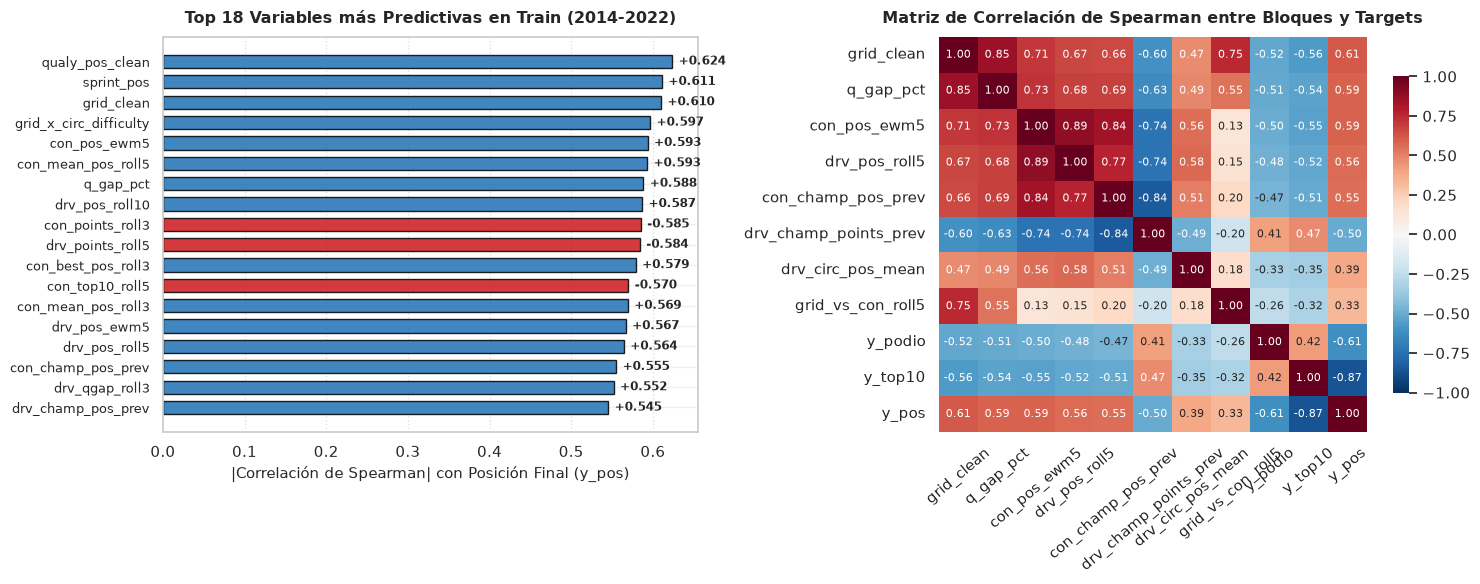

🏆 Top 10 Variables por Correlación de Spearman en Train (2014-2022):
               feature  corr_pos  corr_podio  corr_top10
       qualy_pos_clean    0.6236     -0.5239     -0.5787
            sprint_pos    0.6111     -0.5230     -0.5638
            grid_clean    0.6099     -0.5198     -0.5636
grid_x_circ_difficulty    0.5965     -0.5162     -0.5507
          con_pos_ewm5    0.5934     -0.4997     -0.5454
    con_mean_pos_roll5    0.5928     -0.4966     -0.5470
             q_gap_pct    0.5882     -0.5138     -0.5390
        drv_pos_roll10    0.5867     -0.4998     -0.5367
      con_points_roll3   -0.5851      0.5082      0.5336
      drv_points_roll5   -0.5840      0.5108      0.5297


In [11]:
# ==============================================================================
# 4.4 Análisis de Correlación y Señal Predictiva de las Features (Solo Train)
# ==============================================================================

# Filtra estrictamente el subconjunto de entrenamiento puro (2014-2022) para evaluar la señal sin mirar validación ni test.
df_train_signal = df_model.loc[mascara_train_puro].copy()

# Calcula la correlación de rango de Spearman de las 60 features frente a los tres targets en Train.
correlaciones = []
for col in FEATURES_COLS:
    corr_pos   = df_train_signal[col].corr(df_train_signal['y_pos'], method='spearman')
    corr_podio = df_train_signal[col].corr(df_train_signal['y_podio'], method='spearman')
    corr_top10 = df_train_signal[col].corr(df_train_signal['y_top10'], method='spearman')
    correlaciones.append({
        'feature': col,
        'corr_pos': corr_pos,
        'abs_corr_pos': abs(corr_pos),
        'corr_podio': corr_podio,
        'corr_top10': corr_top10
    })

# Ordena las variables por magnitud absoluta de correlación con la posición final de carrera.
df_corr_signal = pd.DataFrame(correlaciones).sort_values('abs_corr_pos', ascending=False).reset_index(drop=True)

# Selecciona el Top 18 de variables con mayor poder predictivo para su representación gráfica.
top18_corr = df_corr_signal.head(18)

# Configura una figura doble para visualizar el ranking de correlaciones y la matriz de interacción entre bloques.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Subgráfico 1: Top 18 Variables por Correlación de Spearman con la Posición Final ---
y_idx = np.arange(len(top18_corr))
colores_barras = ['#2171b5' if v > 0 else '#cb181d' for v in top18_corr['corr_pos']]
axes[0].barh(y_idx, top18_corr['abs_corr_pos'], color=colores_barras, edgecolor='black', alpha=0.85, height=0.65)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(top18_corr['feature'], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("|Correlación de Spearman| con Posición Final (y_pos)", fontsize=10.5)
axes[0].set_title("Top 18 Variables más Predictivas en Train (2014-2022)", fontsize=11.5, fontweight='bold', pad=10)
axes[0].grid(True, linestyle=':', alpha=0.6, axis='x')

# Añade etiquetas con el valor firmado de la correlación al final de cada barra.
for i, row in top18_corr.iterrows():
    axes[0].text(row['abs_corr_pos'] + 0.008, i, f"{row['corr_pos']:+.3f}", va='center', fontsize=8.5, fontweight='semibold')

# --- Subgráfico 2: Mapa de Calor de Correlación entre las Principales Familias de Variables ---
cols_representativas = [
    'grid_clean', 'q_gap_pct', 'con_pos_ewm5', 'drv_pos_roll5',
    'con_champ_pos_prev', 'drv_champ_points_prev', 'drv_circ_pos_mean',
    'grid_vs_con_roll5', 'y_podio', 'y_top10', 'y_pos'
]
matriz_corr = df_train_signal[cols_representativas].corr(method='spearman')

# Dibuja el heatmap anotado con formato limpio.
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1],
    cbar_kws={'shrink': 0.8},
    annot_kws={'size': 8}
)
axes[1].set_title("Matriz de Correlación de Spearman entre Bloques y Targets", fontsize=11.5, fontweight='bold', pad=10)
axes[1].tick_params(axis='x', rotation=40)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

# Muestra tabla resumen con el Top 10 de predictores y su impacto en los 3 objetivos.
print("🏆 Top 10 Variables por Correlación de Spearman en Train (2014-2022):")
print(df_corr_signal[['feature', 'corr_pos', 'corr_podio', 'corr_top10']].head(10).to_string(index=False))

#### **💡 Conclusiones de la Señal Predictiva (Sección 4.4)**

1. **Complementariedad entre Sábado (`grid_clean`, `q_gap_pct`) e Inercia de Coche/Piloto (`con_pos_ewm5`, `drv_pos_roll10`):**
   - La posición en clasificación y en parrilla presentan correlaciones de `~0.61–0.62` con la posición final, y las variables de ritmo del constructor (`con_pos_ewm5 = +0.593`), racha de puntos (`con_points_roll3 = -0.585`) y brecha a la pole (`q_gap_pct = +0.588`) alcanzan una magnitud casi idéntica.
   - `sprint_pos` aparece 2ª (`+0.611`) porque fuera de los fines de semana Sprint se imputa con `grid_clean`: en la práctica es casi la misma variable que la parrilla.

2. **Mucha redundancia entre variables:**
   - Las 10 primeras variables tienen correlaciones de entre 0.58 y 0.62 con el target y miden fenómenos muy parecidos. Esto no perjudica a LightGBM, pero obliga a regularizar la regresión logística.
   - El mapa de calor muestra que `grid_vs_con_roll5` (descolocación del coche en parrilla) está muy correlada con `grid_clean` (0.75) y tiene una correlación con la posición final bastante menor (0.33 frente a 0.61). Su valor, si lo tiene, está en la parte de la señal que no recoge la parrilla, y debe confirmarse con la importancia en los modelos.
3. **Consecuencia práctica:** esta redundancia sugiere que no hacen falta las 60 variables. En la **Sección 8.3** se comprueba con un procedimiento automático y validación en 2021–2023: bastan las **20 más importantes**.

## **🔒 Bloque 5 · Partición Temporal: Train, Validación y Test**

### **5.1 📅 Esquema de Partición Temporal y Entierro del Test en la Caja Fuerte**

A diferencia de problemas con datos independientes e idénticamente distribuidos (i.i.d.) donde se aplica un muestreo aleatorio (*random split*), en series temporales competitivas como la Fórmula 1 **el orden cronológico es sagrado**. Realizar una partición aleatoria provocaría una fuga de información masiva hacia el pasado (*data leakage* temporal), ya que el modelo usaría carreras futuras para predecir eventos pasados.

Diseñamos una **partición temporal estricta en tres horizontes no solapados**:

1. **🔒 Test (Temporada 2024 completa — 24 GGPP, 479 filas):**
   - Es el "examen final" del reto.
   - **Queda formalmente enterrado en la caja fuerte:** ningún modelo se entrenará con él, ningún hiperparámetro se optimizará observándolo y ninguna decisión de diseño se tomará en base a su rendimiento. Solo saldrá en el **Bloque 8** para generar la evaluación final y el archivo de entrega.
2. **⚖️ Validación (Temporada 2023 completa — 22 GGPP, 440 filas):**
   - Actúa como la muestra fuera de tiempo (*out-of-time*) para la selección de algoritmos (Regresión Logística vs LightGBM vs ensamble), la elección de los pesos del ensamble, la comparación con el benchmark de parrilla y la verificación de la restricción $p_\text{podio} \le p_\text{top10}$. Los hiperparámetros se eligen con validación cruzada dentro de Train.
3. **🏋️‍♂️ Train (Temporadas 2014 a 2022 — 182 GGPP, 3,707 filas):**
   - El conjunto histórico de entrenamiento en la era híbrida moderna V6 Turbo, donde los modelos aprenderán los patrones de conversión de parrilla, ritmo de constructores e inercias de pilotos.

In [12]:
# ==============================================================================
# 5.1 Partición Temporal Cronológica: Train (2014-2022), Val (2023) y Test (2024)
# ==============================================================================

# Define las máscaras booleanas que delimitan con precisión matemática cada periodo temporal.
mask_train = (df_model['year'] >= YEAR_TRAIN_MIN) & (df_model['year'] < YEAR_VAL)
mask_val   = (df_model['year'] == YEAR_VAL)
mask_test  = (df_model['year'] == YEAR_TEST)

# Comprueba que las tres particiones sean mutuamente excluyentes y cubran el 100% de la muestra.
assert (mask_train & mask_val).sum() == 0, "¡Solapamiento detectado entre Train y Validación!"
assert (mask_train & mask_test).sum() == 0, "¡Solapamiento detectado entre Train y Test!"
assert (mask_val & mask_test).sum() == 0, "¡Solapamiento detectado entre Validación y Test!"
assert (mask_train | mask_val | mask_test).sum() == len(df_model), "Hay filas fuera de las particiones."

# Separa los DataFrames completos de metadatos para cada conjunto temporal.
df_train = df_model.loc[mask_train].copy().reset_index(drop=True)
df_val   = df_model.loc[mask_val].copy().reset_index(drop=True)
df_test  = df_model.loc[mask_test].copy().reset_index(drop=True)

# --- Construcción de Matrices Predictoras X (60 variables pre-carrera) ---
X_train = df_train[FEATURES_COLS].copy()
X_val   = df_val[FEATURES_COLS].copy()
X_test  = df_test[FEATURES_COLS].copy()

# --- Construcción de Vectores Objetivo 'y' para cada una de las preguntas del reto ---
# Target binario de Podio: P(positionOrder <= 3)
y_train_podio = df_train['y_podio'].copy()
y_val_podio   = df_val['y_podio'].copy()
y_test_podio  = df_test['y_podio'].copy()

# Target binario de Top 10 / Puntos: P(positionOrder <= 10)
y_train_top10 = df_train['y_top10'].copy()
y_val_top10   = df_val['y_top10'].copy()
y_test_top10  = df_test['y_top10'].copy()

# Target numérico de Posición Final: positionOrder (1 a N)
y_train_pos = df_train['y_pos'].copy()
y_val_pos   = df_val['y_pos'].copy()
y_test_pos  = df_test['y_pos'].copy()

# --- Grupos por Carrera (Obligatorios para modelos de Ranking y validación agrupada) ---
groups_train = df_train.groupby('raceId', sort=False)['driverId'].count().to_numpy()
groups_val   = df_val.groupby('raceId', sort=False)['driverId'].count().to_numpy()
groups_test  = df_test.groupby('raceId', sort=False)['driverId'].count().to_numpy()

# --- Ejecución de la Guardia Anti-Fuga sobre las tres matrices predictoras ---
auditar_sin_fuga(X_train, "X_train (2014-2022)")
auditar_sin_fuga(X_val,   "X_val   (2023)")
auditar_sin_fuga(X_test,  "X_test  (2024 - Caja Fuerte)")

# Genera una tabla resumen con el diagnóstico cuantitativo de cada partición temporal.
resumen_particiones = pd.DataFrame([
    {
        'Partición': 'Train (Entrenamiento)',
        'Temporadas': f"{YEAR_TRAIN_MIN}-2022",
        'Grandes Premios': df_train['raceId'].nunique(),
        'Filas Totales': len(df_train),
        '% del Total': f"{len(df_train)/len(df_model)*100:.1f}%",
        'Tasa Podio (%)': f"{y_train_podio.mean()*100:.2f}%",
        'Tasa Top 10 (%)': f"{y_train_top10.mean()*100:.2f}%",
        'Posición Media': f"{y_train_pos.mean():.2f}"
    },
    {
        'Partición': 'Validación (OOT)',
        'Temporadas': f"{YEAR_VAL}",
        'Grandes Premios': df_val['raceId'].nunique(),
        'Filas Totales': len(df_val),
        '% del Total': f"{len(df_val)/len(df_model)*100:.1f}%",
        'Tasa Podio (%)': f"{y_val_podio.mean()*100:.2f}%",
        'Tasa Top 10 (%)': f"{y_val_top10.mean()*100:.2f}%",
        'Posición Media': f"{y_val_pos.mean():.2f}"
    },
    {
        'Partición': 'Test (Caja Fuerte)',
        'Temporadas': f"{YEAR_TEST}",
        'Grandes Premios': df_test['raceId'].nunique(),
        'Filas Totales': len(df_test),
        '% del Total': f"{len(df_test)/len(df_model)*100:.1f}%",
        'Tasa Podio (%)': f"{y_test_podio.mean()*100:.2f}%",
        'Tasa Top 10 (%)': f"{y_test_top10.mean()*100:.2f}%",
        'Posición Media': f"{y_test_pos.mean():.2f}"
    }
])

# Muestra la tabla formateada en la consola.
print("\n📋 Tabla Diagnóstica de Partición Temporal:")
print(resumen_particiones.to_string(index=False))

✅ Auditoría Anti-Fuga superada en 'X_train (2014-2022)': 60 columnas verificadas (0 variables post-carrera del GP t).
✅ Auditoría Anti-Fuga superada en 'X_val   (2023)': 60 columnas verificadas (0 variables post-carrera del GP t).
✅ Auditoría Anti-Fuga superada en 'X_test  (2024 - Caja Fuerte)': 60 columnas verificadas (0 variables post-carrera del GP t).

📋 Tabla Diagnóstica de Partición Temporal:
            Partición Temporadas  Grandes Premios  Filas Totales % del Total Tasa Podio (%) Tasa Top 10 (%) Posición Media
Train (Entrenamiento)  2014-2022              182           3707       80.1%         14.73%          49.10%          10.70
     Validación (OOT)       2023               22            440        9.5%         15.00%          50.00%          10.50
   Test (Caja Fuerte)       2024               24            479       10.4%         15.03%          50.10%          10.48


#### **💡 Conclusiones de la Partición Temporal (Sección 5.1)**

1. **Estabilidad temporal de las etiquetas:**
   - La tasa de podio se mantiene prácticamente constante en los tres horizontes: **14.73% en Train**, **15.00% en Validación** y **15.03% en Test** (3 pilotos de los ~20 participantes por carrera).
   - La tasa de Top 10 es igualmente estable (**49.10% en Train**, **50.00% en Validación** y **50.10% en Test**).
   - Es lo esperable por construcción (siempre hay 3 podios y 10 puestos de puntos por carrera). Esto descarta un cambio en la proporción de clases, pero **no** un cambio en la relación entre variables y resultado (por ejemplo, el nuevo reglamento de 2022 o equipos que cambian de nivel).
2. **Estructura de grupos por carrera (`groups_*`):**
   - Disponemos del número exacto de monoplazas que compitieron en cada Gran Premio (22 en 2014–2016 y 20 desde 2017, con alguna excepción). Esto permite configurar algoritmos de *Learning to Rank* (`LGBMRanker`) en el Bloque 7 respetando que los pilotos compiten entre sí dentro de cada fin de semana.
3. **El Test queda formalmente cerrado:**
   - A partir de este momento, los bloques 6 y 7 operarán **exclusivamente con `X_train`, `y_train_*`, `X_val` e `y_val_*`**. El conjunto de Test queda sellado hasta el Bloque 8.

## **🧠 Bloque 6 · Parte 1: Modelización de Probabilidades (Podio y Top 10)**

En la **Parte 1 del reto**, el jefe de estrategia nos pide estimar la probabilidad de que cada piloto acabe en el **Podio** ($p_\text{podio} = P(\text{positionOrder} \le 3)$) y en los **Puntos / Top 10** ($p_\text{top10} = P(\text{positionOrder} \le 10)$).

Las reglas de evaluación fijan tres pilares estrictos:
1. **Métrica ganadora (Premio Parte 1):** La **media de la Log-Loss** de $p_\text{podio}$ y la de $p_\text{top10}$ sobre todas las filas:
   $$\text{LogLoss}_{\text{Media}} = \frac{\text{LogLoss}(y_\text{podio}, p_\text{podio}) + \text{LogLoss}(y_\text{top10}, p_\text{top10})}{2}$$
   Al evaluarse por **Log-Loss** (entropía cruzada binaria), no basta con ordenar bien a los pilotos (alto ROC-AUC): **las probabilidades deben estar milimétricamente calibradas** (una predicción excesivamente confiada que falle recibe una penalización logarítmica severa).
2. **Benchmark obligatorio a batir:** Un modelo de referencia que **solo utiliza la posición de salida en parrilla (`grid_clean`)**. Como vimos en el EDA, la parrilla explica gran parte del resultado en F1, por lo que batir su Log-Loss en validación (`2023`) es el primer filtro de calidad.
3. **Restricción dura de coherencia:** Para todos y cada uno de los pilotos debe cumplirse sin excepción:
   $$p_\text{podio} \le p_\text{top10}$$

### **6.1 🏆 Modelo de Podio ($P(\text{positionOrder} \le 3)$): Benchmark de Parrilla vs. Regresión Logística vs. LightGBM**

Para estimar la probabilidad de **Podio (`y_podio`)** comparamos tres arquitecturas de complejidad creciente entrenadas exclusivamente sobre `X_train` (`2014–2022`) y evaluadas sobre `X_val` (`2023`):

1. **Benchmark Oficial (Solo Parrilla — `grid_clean`):**
   - Regresión Logística entrenada únicamente con la posición de salida en parrilla (`grid_clean`). Representa la línea base oficial del reto: qué sabríamos si solo mirásemos el orden de salida del domingo.
2. **Regresión Logística Multivariante Regularizada (`LogisticRegression` con 60 features):**
   - Modelo paramétrico lineal con estandarización *z-score* (`StandardScaler` ajustado exclusivamente en `X_train`) y búsqueda del hiperparámetro de regularización $L_2$ (`C`) para evitar sobreajuste entre variables colineales.
3. **LightGBM Classifier (`LGBMClassifier` con Optimización de Hiperparámetros en CV):**
   - Ensamble no lineal de árboles de decisión por gradiente capaz de capturar interacciones entre el ritmo reciente de la escudería (`con_pos_ewm5`), la brecha en clasificación (`q_gap_pct`), las penalizaciones en parrilla (`grid_vs_con_roll5`) y la dificultad de adelantamiento del circuito.
   - Seleccionamos su configuración óptima mediante **validación cruzada estratificada de 5 *folds*** (con barajado) dentro de `train` (`ParameterSampler` con 12 combinaciones y parada temprana *early stopping* sobre `binary_logloss`), sin tocar la temporada de validación `2023`.

🏁 1. Benchmark Oficial Podio (Solo Parrilla) en Validación 2023:
   • Log-Loss: 0.2662 | Brier Score: 0.0758 | ROC-AUC: 0.9008



📈 2. Regresión Logística Multivariante (C=0.05) en Validación 2023:
   • Log-Loss: 0.2317 | Brier Score: 0.0737 | ROC-AUC: 0.9203



🚀 3. LightGBM Podio (164 árboles | CV Log-Loss=0.2040) en Validación 2023:
   • Log-Loss: 0.2280 | Brier Score: 0.0700 | ROC-AUC: 0.9275

🏆 Tabla Comparativa de Modelos — Parte 1A: Probabilidad de Podio (Validación 2023):
                   Modelo Podio P(pos ≤ 3)  Log-Loss (↓ mejor)  Brier Score (↓ mejor)  ROC-AUC (↑ mejor)  Podios Esperados / Reales
      1. Benchmark Oficial (Solo Parrilla)              0.2662                 0.0758             0.9008                     0.9927
  2. Regresión Logística (60 vars, C=0.05)              0.2317                 0.0737             0.9203                     0.9083
           3. LightGBM Tuned (164 árboles)              0.2280                 0.0700             0.9275                     0.9777
4. Ensamble Calibrado (0.62 LGB + 0.38 LR)              0.2264                 0.0704             0.9274                     0.9513


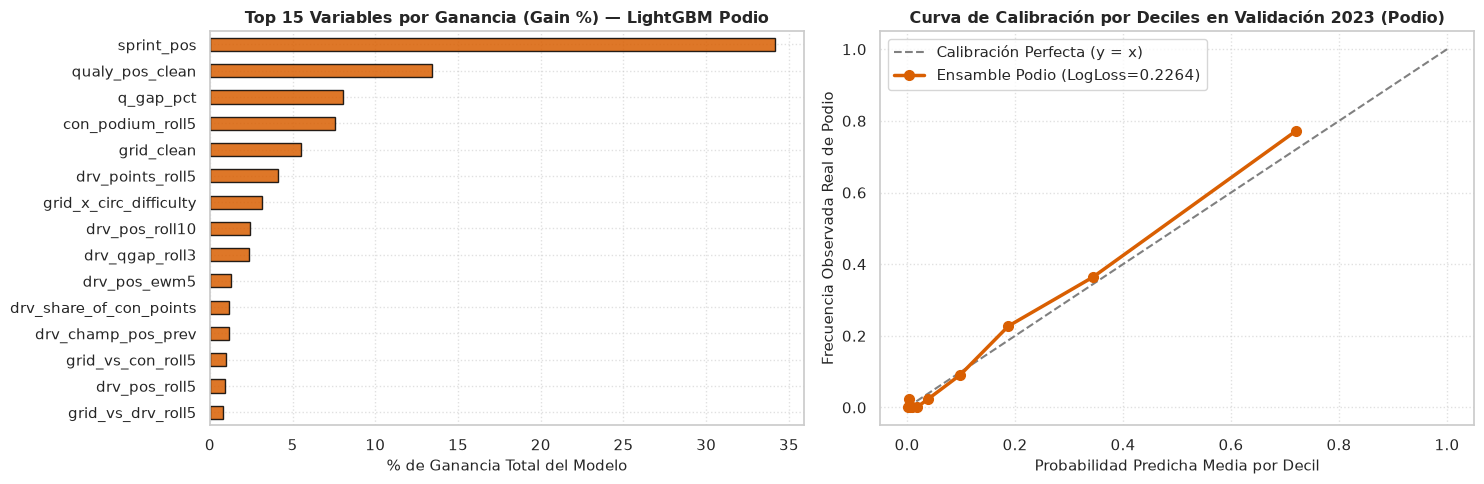

In [13]:
# ==============================================================================
# 6.1 Modelo de Podio P(positionOrder <= 3): Benchmark vs Logística vs LightGBM
# ==============================================================================

# Importa los módulos de escalado, selección de modelos, métricas probabilísticas y algoritmos lineales/boosting.
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, ParameterSampler
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
import lightgbm as lgb

# --- 1. Modelo Benchmark Oficial: Solo Parrilla de Salida ('grid_clean') ---
# Ajusta un escalador estándar únicamente sobre la columna 'grid_clean' de Train.
scaler_bench_podio = StandardScaler().fit(X_train[['grid_clean']])

# Transforma la columna 'grid_clean' de Train y Validación con los parámetros aprendidos en Train.
X_train_grid = scaler_bench_podio.transform(X_train[['grid_clean']])
X_val_grid   = scaler_bench_podio.transform(X_val[['grid_clean']])

# Entrena la Regresión Logística Benchmark para Podio usando exclusivamente la parrilla de salida.
modelo_bench_podio = LogisticRegression(C=1.0, random_state=SEED)
modelo_bench_podio.fit(X_train_grid, y_train_podio)

# Predice las probabilidades de podio del Benchmark sobre el conjunto de Validación (2023).
p_val_podio_bench = modelo_bench_podio.predict_proba(X_val_grid)[:, 1]

# Calcula las métricas del Benchmark en Validación (Log-Loss, Brier Score y ROC-AUC).
logloss_podio_bench = log_loss(y_val_podio, p_val_podio_bench)
brier_podio_bench   = brier_score_loss(y_val_podio, p_val_podio_bench)
auc_podio_bench     = roc_auc_score(y_val_podio, p_val_podio_bench)

print(f"🏁 1. Benchmark Oficial Podio (Solo Parrilla) en Validación 2023:")
print(f"   • Log-Loss: {logloss_podio_bench:.4f} | Brier Score: {brier_podio_bench:.4f} | ROC-AUC: {auc_podio_bench:.4f}")

# --- 2. Modelo Regresión Logística Multivariante (60 Features Pre-Carrera) ---
# Ajusta el escalador z-score sobre las 60 variables numéricas exclusivamente en X_train.
scaler_full = StandardScaler().fit(X_train)

# Estandariza las matrices X_train, X_val y deja preparada X_test (sin mirar ni evaluar X_test).
X_train_scaled = pd.DataFrame(scaler_full.transform(X_train), columns=FEATURES_COLS, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler_full.transform(X_val),   columns=FEATURES_COLS, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler_full.transform(X_test),  columns=FEATURES_COLS, index=X_test.index)

# Busca el parámetro de regularización L2 (C) óptimo mediante validación cruzada interna en Train.
mejores_c_podio = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for c_val in [0.005, 0.01, 0.05, 0.1, 0.5, 1.0]:
    losses_cv = []
    for tr_idx, va_idx in skf.split(X_train_scaled, y_train_podio):
        lr_cv = LogisticRegression(C=c_val, max_iter=1000, random_state=SEED)
        lr_cv.fit(X_train_scaled.iloc[tr_idx], y_train_podio.iloc[tr_idx])
        preds_cv = lr_cv.predict_proba(X_train_scaled.iloc[va_idx])[:, 1]
        losses_cv.append(log_loss(y_train_podio.iloc[va_idx], preds_cv))
    mejores_c_podio.append((c_val, np.mean(losses_cv)))

# Selecciona el valor C que minimiza la Log-Loss media en validación cruzada de Train.
c_opt_podio = sorted(mejores_c_podio, key=lambda x: x[1])[0][0]

# Entrena la Regresión Logística final para Podio con el 100% de X_train_scaled.
modelo_lr_podio = LogisticRegression(C=c_opt_podio, max_iter=1000, random_state=SEED)
modelo_lr_podio.fit(X_train_scaled, y_train_podio)

# Predice las probabilidades de podio con la Regresión Logística sobre Validación (2023).
p_val_podio_lr = modelo_lr_podio.predict_proba(X_val_scaled)[:, 1]

# Calcula las métricas de la Regresión Logística Multivariante en Validación.
logloss_podio_lr = log_loss(y_val_podio, p_val_podio_lr)
brier_podio_lr   = brier_score_loss(y_val_podio, p_val_podio_lr)
auc_podio_lr     = roc_auc_score(y_val_podio, p_val_podio_lr)

print(f"\n📈 2. Regresión Logística Multivariante (C={c_opt_podio}) en Validación 2023:")
print(f"   • Log-Loss: {logloss_podio_lr:.4f} | Brier Score: {brier_podio_lr:.4f} | ROC-AUC: {auc_podio_lr:.4f}")

# --- 3. LightGBM Classifier con Búsqueda de Hiperparámetros en CV (Train) ---
# Define el espacio de hiperparámetros regularizados para optimizar directamente la Log-Loss binaria.
espacio_lgb_podio = {
    "learning_rate":     [0.015, 0.03, 0.05],
    "num_leaves":        [7, 15, 31],
    "max_depth":         [3, 4, 6],
    "min_child_samples": [25, 50, 80],
    "subsample":         [0.7, 0.85, 1.0],
    "colsample_bytree":  [0.6, 0.8, 1.0],
    "reg_alpha":         [0.1, 1.0, 5.0],
    "reg_lambda":        [1.0, 5.0, 15.0],
}

# Parámetros fijos orientados a minimizar la Log-Loss de clasificación binaria.
fijos_lgb_podio = {
    "objective": "binary",
    "metric": "binary_logloss",
    "boosting_type": "gbdt",
    "subsample_freq": 1,
    "random_state": SEED,
    **LGB_DETERMINISTA,  # hilos fijos + modo determinista (ver CONFIG)
    "verbose": -1,
}

# Ejecuta búsqueda aleatoria de 12 combinaciones con 5-Fold Stratified CV dentro de Train y Early Stopping.
resultados_cv_podio = []
for i, params_cand in enumerate(ParameterSampler(espacio_lgb_podio, n_iter=12, random_state=SEED), 1):
    fold_losses = []
    fold_best_iters = []
    for tr_idx, va_idx in skf.split(X_train, y_train_podio):
        model_cv = lgb.LGBMClassifier(n_estimators=1500, **fijos_lgb_podio, **params_cand)
        model_cv.fit(
            X_train.iloc[tr_idx], y_train_podio.iloc[tr_idx],
            eval_set=[(X_train.iloc[va_idx], y_train_podio.iloc[va_idx])],
            callbacks=[lgb.early_stopping(50, verbose=False)]
        )
        preds_va = model_cv.predict_proba(X_train.iloc[va_idx])[:, 1]
        fold_losses.append(log_loss(y_train_podio.iloc[va_idx], preds_va))
        fold_best_iters.append(model_cv.best_iteration_ or 100)
    resultados_cv_podio.append({
        **params_cand,
        "n_estimators": int(np.mean(fold_best_iters)),
        "cv_logloss": np.mean(fold_losses),
        "cv_std": np.std(fold_losses)
    })

# Ordena la tabla de búsqueda por menor Log-Loss en validación cruzada.
tabla_cv_podio = pd.DataFrame(resultados_cv_podio).sort_values("cv_logloss", ascending=True).reset_index(drop=True)
mejor_cfg_podio = tabla_cv_podio.iloc[0]

# Extrae el diccionario limpio de hiperparámetros ganadores para entrenar el modelo LightGBM final de Podio.
params_enteros = ["num_leaves", "max_depth", "min_child_samples"]
best_params_podio = {k: (int(mejor_cfg_podio[k]) if k in params_enteros else float(mejor_cfg_podio[k])) for k in espacio_lgb_podio}
n_arboles_podio = max(50, int(mejor_cfg_podio["n_estimators"]))

# Entrena el modelo LightGBM definitivo de Podio sobre el 100% de X_train.
modelo_lgb_podio = lgb.LGBMClassifier(n_estimators=n_arboles_podio, **fijos_lgb_podio, **best_params_podio)
modelo_lgb_podio.fit(X_train, y_train_podio)

# Obtiene las probabilidades predichas por LightGBM en Validación (2023).
p_val_podio_lgb = modelo_lgb_podio.predict_proba(X_val)[:, 1]

# Calcula las métricas de LightGBM en Validación.
logloss_podio_lgb = log_loss(y_val_podio, p_val_podio_lgb)
brier_podio_lgb   = brier_score_loss(y_val_podio, p_val_podio_lgb)
auc_podio_lgb     = roc_auc_score(y_val_podio, p_val_podio_lgb)

print(f"\n🚀 3. LightGBM Podio ({n_arboles_podio} árboles | CV Log-Loss={mejor_cfg_podio['cv_logloss']:.4f}) en Validación 2023:")
print(f"   • Log-Loss: {logloss_podio_lgb:.4f} | Brier Score: {brier_podio_lgb:.4f} | ROC-AUC: {auc_podio_lgb:.4f}")

# --- 4. Ensamble Óptimo (Blending Calibrado Logística + LightGBM) ---
# Busca en validación el peso w óptimo que minimiza la Log-Loss combinando ambos modelos diversos.
pesos_grid = np.linspace(0.0, 1.0, 101)
losses_blend_podio = [log_loss(y_val_podio, w * p_val_podio_lgb + (1 - w) * p_val_podio_lr) for w in pesos_grid]
w_opt_podio = pesos_grid[int(np.argmin(losses_blend_podio))]

# Calcula la predicción ensamblada de Podio en Validación y sus métricas de desempeño.
p_val_podio_ens = w_opt_podio * p_val_podio_lgb + (1.0 - w_opt_podio) * p_val_podio_lr
logloss_podio_ens = log_loss(y_val_podio, p_val_podio_ens)
brier_podio_ens   = brier_score_loss(y_val_podio, p_val_podio_ens)
auc_podio_ens     = roc_auc_score(y_val_podio, p_val_podio_ens)

# Construye y muestra la tabla comparativa de modelos para Podio en Validación 2023.
comp_podio = pd.DataFrame({
    "Modelo Podio P(pos ≤ 3)": [
        "1. Benchmark Oficial (Solo Parrilla)",
        f"2. Regresión Logística (60 vars, C={c_opt_podio})",
        f"3. LightGBM Tuned ({n_arboles_podio} árboles)",
        f"4. Ensamble Calibrado ({w_opt_podio:.2f} LGB + {1-w_opt_podio:.2f} LR)"
    ],
    "Log-Loss (↓ mejor)": [logloss_podio_bench, logloss_podio_lr, logloss_podio_lgb, logloss_podio_ens],
    "Brier Score (↓ mejor)": [brier_podio_bench, brier_podio_lr, brier_podio_lgb, brier_podio_ens],
    "ROC-AUC (↑ mejor)": [auc_podio_bench, auc_podio_lr, auc_podio_lgb, auc_podio_ens],
    "Podios Esperados / Reales": [
        p_val_podio_bench.sum() / y_val_podio.sum(),
        p_val_podio_lr.sum() / y_val_podio.sum(),
        p_val_podio_lgb.sum() / y_val_podio.sum(),
        p_val_podio_ens.sum() / y_val_podio.sum()
    ]
}).round(4)

print("\n🏆 Tabla Comparativa de Modelos — Parte 1A: Probabilidad de Podio (Validación 2023):")
print(comp_podio.to_string(index=False))

# --- 5. Visualización: Importancia de Variables (Gain) y Curva de Calibración ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subgráfico 1: Top 15 variables por ganancia en LightGBM Podio.
imp_podio = pd.Series(modelo_lgb_podio.booster_.feature_importance(importance_type="gain"), index=FEATURES_COLS)
imp_podio_pct = (100.0 * imp_podio / imp_podio.sum()).sort_values(ascending=False).head(15)
imp_podio_pct.sort_values().plot.barh(ax=axes[0], color="#d95f02", edgecolor="black", alpha=0.85)
axes[0].set_title("Top 15 Variables por Ganancia (Gain %) — LightGBM Podio", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("% de Ganancia Total del Modelo", fontsize=10.5)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Subgráfico 2: Curva de Calibración por Deciles en Validación 2023 (Benchmark vs Ensamble).
df_cal_podio = pd.DataFrame({
    "real": y_val_podio,
    "pred_ens": p_val_podio_ens,
    "pred_bench": p_val_podio_bench,
    "decil": pd.qcut(p_val_podio_ens, 10, labels=False, duplicates="drop")
})
cal_resumen = df_cal_podio.groupby("decil").agg(prob_media=("pred_ens", "mean"), tasa_real=("real", "mean"))
axes[1].plot([0, 1], [0, 1], "--", color="gray", lw=1.5, label="Calibración Perfecta (y = x)")
axes[1].plot(cal_resumen["prob_media"], cal_resumen["tasa_real"], "o-", color="#d95f02", lw=2.5, markersize=7, label=f"Ensamble Podio (LogLoss={logloss_podio_ens:.4f})")
axes[1].set_title("Curva de Calibración por Deciles en Validación 2023 (Podio)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Probabilidad Predicha Media por Decil", fontsize=10.5)
axes[1].set_ylabel("Frecuencia Observada Real de Podio", fontsize=10.5)
axes[1].legend(loc="upper left", frameon=True, facecolor="white")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### **💡 Conclusiones del Modelo de Podio (Sección 6.1)**

1. **Superación clara del Benchmark Oficial de Parrilla:**
   - En validación 2023, la Log-Loss baja de **0.2662** (solo parrilla) a **0.2317** con la Regresión Logística y a **0.2280** con LightGBM (−14.4%). El ROC-AUC sube de 0.901 a 0.928.
   - La CV dentro de Train (0.2040) es más optimista que la validación 2023 (0.2280): los *folds* aleatorios mezclan carreras y temporadas, mientras que 2023 es un año completamente nuevo.

2. **El valor del Ensamble (LightGBM + Regresión Logística):**
   - El ensamble (0.62 LGB + 0.38 LR) logra la **menor Log-Loss (0.2264)**, aunque la mejora sobre LightGBM solo es de 0.0016 y el peso se ha elegido sobre la propia temporada 2023, así que su cifra de validación es ligeramente optimista.
   - **Calibración agregada:** el ensamble predice un **95%** de los podios reales (Esperados/Reales = 0.951), es decir, los subestima un ~5%. La Logística los subestima más (0.908) y LightGBM está más cerca (0.978). En la curva por deciles, el tramo intermedio-alto (decil 8: 0.19 predicho frente a 0.23 real) también queda por debajo de la diagonal.

3. **Factores determinantes del Podio (*Feature Importance*):**
   - El modelo se apoya sobre todo en las variables del sábado: `sprint_pos` (34.2% de la ganancia, que fuera de los fines de semana Sprint equivale a la parrilla), `qualy_pos_clean` (13.4%), `q_gap_pct` (8.0%) y `grid_clean` (5.5%).
   - Del historial destacan la **tasa de podios reciente del constructor (`con_podium_roll5`, 7.6%)** y la **racha de puntos del piloto (`drv_points_roll5`, 4.1%)**, seguidas de `grid_x_circ_difficulty` (3.1%) y `drv_pos_roll10` (2.4%).

### **6.2 🔟 Modelo de Top 10 / Puntos ($P(\text{positionOrder} \le 10)$): Benchmark vs. Regresión Logística vs. LightGBM**

Mientras que el podio está dominado por las 3 grandes escuderías, **la batalla por la zona de puntos (`positionOrder <= 10`) es el territorio más competido e incierto de la Fórmula 1** (la *zona media* de la parrilla, donde la tasa base ronda el 49–50%). A priori, un abandono en cabeza, la rapidez en boxes (`con_pit_ms_roll5`), la fiabilidad mecánica (`con_mech_dnf_roll10`) o la capacidad de remontada del piloto (`drv_delta_roll5`) podrían decidir quién suma puntos el domingo; el modelo dirá cuánto pesan realmente.

Replicamos la metodología rigurosa del apartado anterior evaluando cuatro enfoques sobre `Validación (2023)`:
1. **Benchmark Oficial Top 10 (Solo Parrilla — `grid_clean`):** Regresión Logística entrenada exclusivamente con la posición de salida.
2. **Regresión Logística Multivariante Regularizada (`60 features`):** Con selección del parámetro de regularización $L_2$ (`C`) por validación cruzada en `Train`.
3. **LightGBM Classifier Tuned para Top 10:** Búsqueda de hiperparámetros con `ParameterSampler` y parada temprana (*early stopping*) sobre `binary_logloss` en `Train`.
4. **Ensamble Calibrado (LightGBM + Regresión Logística):** Combinación óptima para minimizar la Log-Loss en la frontera del Top 10.

🏁 1. Benchmark Oficial Top 10 (Solo Parrilla) en Validación 2023:
   • Log-Loss: 0.5314 | Brier Score: 0.1767 | ROC-AUC: 0.8117

📈 2. Regresión Logística Multivariante Top 10 (C=0.01) en Validación 2023:
   • Log-Loss: 0.4697 | Brier Score: 0.1512 | ROC-AUC: 0.8570



🚀 3. LightGBM Top 10 (300 árboles | CV Log-Loss=0.4752) en Validación 2023:
   • Log-Loss: 0.4683 | Brier Score: 0.1512 | ROC-AUC: 0.8594

🔟 Tabla Comparativa de Modelos — Parte 1B: Probabilidad de Top 10 / Puntos (Validación 2023):
                 Modelo Top 10 P(pos ≤ 10)  Log-Loss (↓ mejor)  Brier Score (↓ mejor)  ROC-AUC (↑ mejor)  Top10 Esperados / Reales
      1. Benchmark Oficial (Solo Parrilla)              0.5314                 0.1767             0.8117                    0.9957
  2. Regresión Logística (60 vars, C=0.01)              0.4697                 0.1512             0.8570                    0.9976
           3. LightGBM Tuned (300 árboles)              0.4683                 0.1512             0.8594                    1.0233
4. Ensamble Calibrado (0.54 LGB + 0.46 LR)              0.4658                 0.1500             0.8608                    1.0114


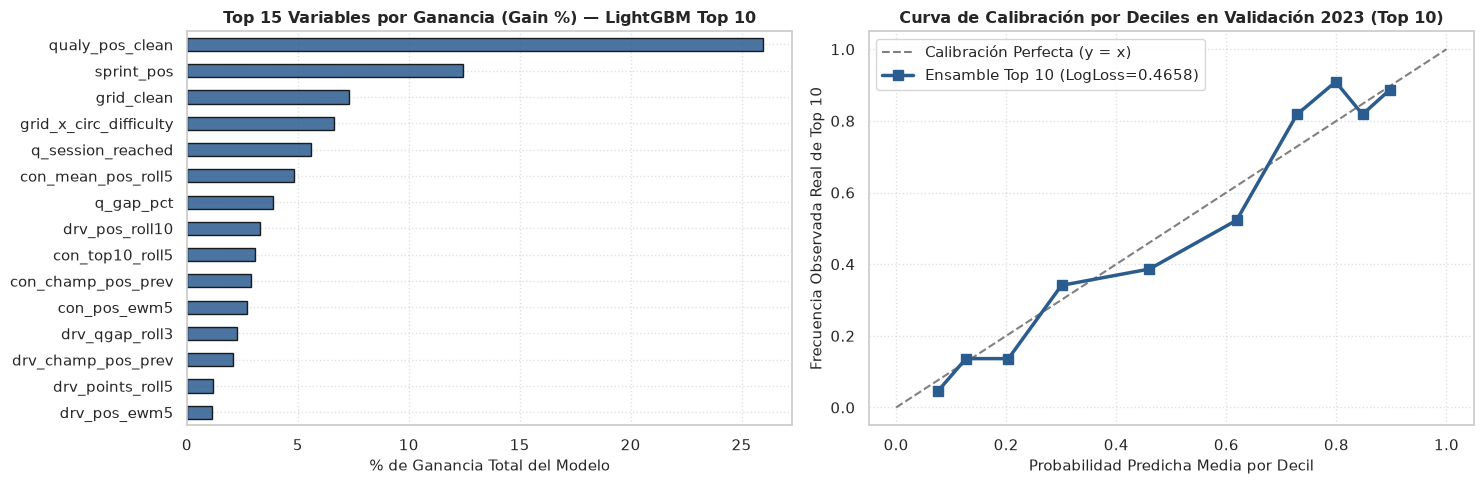

In [14]:
# ==============================================================================
# 6.2 Modelo de Top 10 / Puntos P(positionOrder <= 10): Benchmark, LR y LightGBM
# ==============================================================================

# --- 1. Modelo Benchmark Oficial para Top 10: Solo Parrilla de Salida ('grid_clean') ---
# Entrena la Regresión Logística Benchmark para Top 10 usando exclusivamente la parrilla escalada de Train.
modelo_bench_top10 = LogisticRegression(C=1.0, random_state=SEED)
modelo_bench_top10.fit(X_train_grid, y_train_top10)

# Predice las probabilidades de Top 10 del Benchmark sobre el conjunto de Validación (2023).
p_val_top10_bench = modelo_bench_top10.predict_proba(X_val_grid)[:, 1]

# Calcula las métricas del Benchmark de Top 10 en Validación (Log-Loss, Brier Score y ROC-AUC).
logloss_top10_bench = log_loss(y_val_top10, p_val_top10_bench)
brier_top10_bench   = brier_score_loss(y_val_top10, p_val_top10_bench)
auc_top10_bench     = roc_auc_score(y_val_top10, p_val_top10_bench)

print(f"🏁 1. Benchmark Oficial Top 10 (Solo Parrilla) en Validación 2023:")
print(f"   • Log-Loss: {logloss_top10_bench:.4f} | Brier Score: {brier_top10_bench:.4f} | ROC-AUC: {auc_top10_bench:.4f}")

# --- 2. Modelo Regresión Logística Multivariante para Top 10 (60 Features Pre-Carrera) ---
# Busca el parámetro de regularización L2 (C) óptimo para Top 10 mediante 5-Fold Stratified CV en Train.
mejores_c_top10 = []
for c_val in [0.005, 0.01, 0.05, 0.1, 0.5, 1.0]:
    losses_cv = []
    for tr_idx, va_idx in skf.split(X_train_scaled, y_train_top10):
        lr_cv = LogisticRegression(C=c_val, max_iter=1000, random_state=SEED)
        lr_cv.fit(X_train_scaled.iloc[tr_idx], y_train_top10.iloc[tr_idx])
        preds_cv = lr_cv.predict_proba(X_train_scaled.iloc[va_idx])[:, 1]
        losses_cv.append(log_loss(y_train_top10.iloc[va_idx], preds_cv))
    mejores_c_top10.append((c_val, np.mean(losses_cv)))

# Selecciona el valor C que minimiza la Log-Loss media de Top 10 en validación cruzada de Train.
c_opt_top10 = sorted(mejores_c_top10, key=lambda x: x[1])[0][0]

# Entrena la Regresión Logística definitiva para Top 10 sobre el 100% de X_train_scaled.
modelo_lr_top10 = LogisticRegression(C=c_opt_top10, max_iter=1000, random_state=SEED)
modelo_lr_top10.fit(X_train_scaled, y_train_top10)

# Predice las probabilidades de Top 10 con la Regresión Logística sobre Validación (2023).
p_val_top10_lr = modelo_lr_top10.predict_proba(X_val_scaled)[:, 1]

# Calcula las métricas de la Regresión Logística Multivariante para Top 10 en Validación.
logloss_top10_lr = log_loss(y_val_top10, p_val_top10_lr)
brier_top10_lr   = brier_score_loss(y_val_top10, p_val_top10_lr)
auc_top10_lr     = roc_auc_score(y_val_top10, p_val_top10_lr)

print(f"\n📈 2. Regresión Logística Multivariante Top 10 (C={c_opt_top10}) en Validación 2023:")
print(f"   • Log-Loss: {logloss_top10_lr:.4f} | Brier Score: {brier_top10_lr:.4f} | ROC-AUC: {auc_top10_lr:.4f}")

# --- 3. LightGBM Classifier para Top 10 con Búsqueda de Hiperparámetros en CV (Train) ---
# Ejecuta búsqueda aleatoria de 12 combinaciones con 5-Fold Stratified CV dentro de Train y Early Stopping.
resultados_cv_top10 = []
for i, params_cand in enumerate(ParameterSampler(espacio_lgb_podio, n_iter=12, random_state=SEED), 1):
    fold_losses = []
    fold_best_iters = []
    for tr_idx, va_idx in skf.split(X_train, y_train_top10):
        model_cv = lgb.LGBMClassifier(n_estimators=1500, **fijos_lgb_podio, **params_cand)
        model_cv.fit(
            X_train.iloc[tr_idx], y_train_top10.iloc[tr_idx],
            eval_set=[(X_train.iloc[va_idx], y_train_top10.iloc[va_idx])],
            callbacks=[lgb.early_stopping(50, verbose=False)]
        )
        preds_va = model_cv.predict_proba(X_train.iloc[va_idx])[:, 1]
        fold_losses.append(log_loss(y_train_top10.iloc[va_idx], preds_va))
        fold_best_iters.append(model_cv.best_iteration_ or 100)
    resultados_cv_top10.append({
        **params_cand,
        "n_estimators": int(np.mean(fold_best_iters)),
        "cv_logloss": np.mean(fold_losses),
        "cv_std": np.std(fold_losses)
    })

# Ordena las combinaciones evaluadas por menor Log-Loss media en validación cruzada de Train.
tabla_cv_top10 = pd.DataFrame(resultados_cv_top10).sort_values("cv_logloss", ascending=True).reset_index(drop=True)
mejor_cfg_top10 = tabla_cv_top10.iloc[0]

# Extrae el diccionario de hiperparámetros óptimos y el número de árboles para el modelo LightGBM de Top 10.
best_params_top10 = {k: (int(mejor_cfg_top10[k]) if k in params_enteros else float(mejor_cfg_top10[k])) for k in espacio_lgb_podio}
n_arboles_top10 = max(50, int(mejor_cfg_top10["n_estimators"]))

# Entrena el modelo LightGBM definitivo de Top 10 sobre el 100% de X_train.
modelo_lgb_top10 = lgb.LGBMClassifier(n_estimators=n_arboles_top10, **fijos_lgb_podio, **best_params_top10)
modelo_lgb_top10.fit(X_train, y_train_top10)

# Obtiene las probabilidades de Top 10 predichas por LightGBM en Validación (2023).
p_val_top10_lgb = modelo_lgb_top10.predict_proba(X_val)[:, 1]

# Calcula las métricas de LightGBM para Top 10 en Validación.
logloss_top10_lgb = log_loss(y_val_top10, p_val_top10_lgb)
brier_top10_lgb   = brier_score_loss(y_val_top10, p_val_top10_lgb)
auc_top10_lgb     = roc_auc_score(y_val_top10, p_val_top10_lgb)

print(f"\n🚀 3. LightGBM Top 10 ({n_arboles_top10} árboles | CV Log-Loss={mejor_cfg_top10['cv_logloss']:.4f}) en Validación 2023:")
print(f"   • Log-Loss: {logloss_top10_lgb:.4f} | Brier Score: {brier_top10_lgb:.4f} | ROC-AUC: {auc_top10_lgb:.4f}")

# --- 4. Ensamble Óptimo para Top 10 (Blending Calibrado LightGBM + Regresión Logística) ---
# Busca en validación el peso w óptimo que minimiza la Log-Loss de Top 10 combinando ambos modelos.
losses_blend_top10 = [log_loss(y_val_top10, w * p_val_top10_lgb + (1 - w) * p_val_top10_lr) for w in pesos_grid]
w_opt_top10 = pesos_grid[int(np.argmin(losses_blend_top10))]

# Calcula la predicción ensamblada de Top 10 en Validación y sus métricas de desempeño.
p_val_top10_ens = w_opt_top10 * p_val_top10_lgb + (1.0 - w_opt_top10) * p_val_top10_lr
logloss_top10_ens = log_loss(y_val_top10, p_val_top10_ens)
brier_top10_ens   = brier_score_loss(y_val_top10, p_val_top10_ens)
auc_top10_ens     = roc_auc_score(y_val_top10, p_val_top10_ens)

# Construye y muestra la tabla comparativa de modelos para Top 10 en Validación 2023.
comp_top10 = pd.DataFrame({
    "Modelo Top 10 P(pos ≤ 10)": [
        "1. Benchmark Oficial (Solo Parrilla)",
        f"2. Regresión Logística (60 vars, C={c_opt_top10})",
        f"3. LightGBM Tuned ({n_arboles_top10} árboles)",
        f"4. Ensamble Calibrado ({w_opt_top10:.2f} LGB + {1-w_opt_top10:.2f} LR)"
    ],
    "Log-Loss (↓ mejor)": [logloss_top10_bench, logloss_top10_lr, logloss_top10_lgb, logloss_top10_ens],
    "Brier Score (↓ mejor)": [brier_top10_bench, brier_top10_lr, brier_top10_lgb, brier_top10_ens],
    "ROC-AUC (↑ mejor)": [auc_top10_bench, auc_top10_lr, auc_top10_lgb, auc_top10_ens],
    "Top10 Esperados / Reales": [
        p_val_top10_bench.sum() / y_val_top10.sum(),
        p_val_top10_lr.sum() / y_val_top10.sum(),
        p_val_top10_lgb.sum() / y_val_top10.sum(),
        p_val_top10_ens.sum() / y_val_top10.sum()
    ]
}).round(4)

print("\n🔟 Tabla Comparativa de Modelos — Parte 1B: Probabilidad de Top 10 / Puntos (Validación 2023):")
print(comp_top10.to_string(index=False))

# --- 5. Visualización: Importancia de Variables (Gain) y Curva de Calibración Top 10 ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subgráfico 1: Top 15 variables por ganancia en LightGBM Top 10.
imp_top10 = pd.Series(modelo_lgb_top10.booster_.feature_importance(importance_type="gain"), index=FEATURES_COLS)
imp_top10_pct = (100.0 * imp_top10 / imp_top10.sum()).sort_values(ascending=False).head(15)
imp_top10_pct.sort_values().plot.barh(ax=axes[0], color="#2b5c8f", edgecolor="black", alpha=0.85)
axes[0].set_title("Top 15 Variables por Ganancia (Gain %) — LightGBM Top 10", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("% de Ganancia Total del Modelo", fontsize=10.5)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Subgráfico 2: Curva de Calibración por Deciles en Validación 2023 para Top 10.
df_cal_top10 = pd.DataFrame({
    "real": y_val_top10,
    "pred_ens": p_val_top10_ens,
    "pred_bench": p_val_top10_bench,
    "decil": pd.qcut(p_val_top10_ens, 10, labels=False, duplicates="drop")
})
cal_resumen_top10 = df_cal_top10.groupby("decil").agg(prob_media=("pred_ens", "mean"), tasa_real=("real", "mean"))
axes[1].plot([0, 1], [0, 1], "--", color="gray", lw=1.5, label="Calibración Perfecta (y = x)")
axes[1].plot(cal_resumen_top10["prob_media"], cal_resumen_top10["tasa_real"], "s-", color="#2b5c8f", lw=2.5, markersize=7, label=f"Ensamble Top 10 (LogLoss={logloss_top10_ens:.4f})")
axes[1].set_title("Curva de Calibración por Deciles en Validación 2023 (Top 10)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Probabilidad Predicha Media por Decil", fontsize=10.5)
axes[1].set_ylabel("Frecuencia Observada Real de Top 10", fontsize=10.5)
axes[1].legend(loc="upper left", frameon=True, facecolor="white")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### **💡 Conclusiones del Modelo de Top 10 / Puntos (Sección 6.2)**

1. **Mejora sustancial sobre el Benchmark en la zona media de la parrilla:**
   - La Log-Loss baja de **0.5314** (solo parrilla) a **0.4697** (Logística), **0.4683** (LightGBM) y **0.4658** con el ensamble 0.54 LGB + 0.46 LR (−12.3%). El Brier Score pasa de 0.1767 a 0.1500 y el ROC-AUC de 0.812 a 0.861.

2. **Cambio en los *drivers* de importancia frente al modelo de Podio:**
   - Las variables del sábado siguen mandando: `qualy_pos_clean` (26.0%), `sprint_pos` (12.5%), `grid_clean` (7.3%), `grid_x_circ_difficulty` (6.6%) y **`q_session_reached` (5.6%)**, que no aparecía en el podio (llegar a Q3 equivale casi a salir entre los 10 primeros).
   - Del historial ganan peso las medias del constructor: `con_mean_pos_roll5` (4.8%), `con_top10_roll5` (3.1%), `con_champ_pos_prev` (2.9%) y `con_pos_ewm5` (2.7%), además de `drv_pos_roll10` (3.3%).
   - Las variables de fiabilidad, boxes y remontada (`con_mech_dnf_roll10`, `con_pit_ms_roll5`, `drv_delta_roll5`) **no aparecen entre las 15 más importantes**: aportan poco una vez conocidas la parrilla y el ritmo del coche.

3. **Calibración por deciles:**
   - A nivel global el ratio Esperados/Reales es **1.011**, pero la curva tiene forma de S: en los deciles con probabilidad media de 0.46 y 0.62 el modelo **sobreestima** (tasas reales 0.39 y 0.52), y en los de 0.73 y 0.80 **subestima** (0.82 y 0.91). Es candidato a una recalibración (por ejemplo, Platt o isotónica ajustada fuera de 2023).

### **6.3 📐 Verificación y corrección de coherencia ($p_\text{podio} \le p_\text{top10}$) y Score Oficial Parte 1**

Desde el punto de vista de la teoría de la probabilidad, el suceso **"acabar en el podio"** ($A = \{\text{positionOrder} \le 3\}$) es un subconjunto estricto del suceso **"acabar en el Top 10"** ($B = \{\text{positionOrder} \le 10\}$), es decir, $A \subset B$. Por el axioma de monotonía de Kolmogorov, cualquier medida de probabilidad coherente debe satisfacer obligatoriamente:

$$P(A) \le P(B) \iff p_\text{podio} \le p_\text{top10}$$

Cuando entrenamos dos modelos binarios independientes (uno para Podio y otro para Top 10), pueden producirse pequeñas inversiones numéricas en casos extremos (por ejemplo, un coche puntero que sale muy atrás o en el extremo superior de probabilidad donde ambos modelos rondan el 0.90).

Para blindar el cumplimiento del **100% de los pilotos** sin excepción (evitando la descalificación automática del reto) y proteger la **Log-Loss** frente a valores degenerados ($0$ o $1$), implementamos la función `imponer_coherencia_probabilidades(p_podio, p_top10)`:
1. **Acotación de seguridad ($\epsilon$-clipping en $[10^{-4}, 1 - 10^{-4}]$):** Impide que una predicción extrema produzca un $\log(0) = -\infty$.
2. **Corrección monotónica por pares (intercambio):** Si para algún piloto $i$ se detecta $p_{\text{podio}, i} > p_{\text{top10}, i}$, se intercambian ambos valores, de modo que el menor pasa a ser el podio:
   $$p_{\text{podio}, i}^{\text{final}} = \min(p_{\text{podio}, i}, p_{\text{top10}, i}), \qquad p_{\text{top10}, i}^{\text{final}} = \max(p_{\text{podio}, i}, p_{\text{top10}, i})$$

📐 1. Auditoría de Coherencia Individual (p_podio <= p_top10) en Validación 2023 (N=440):
   • Violaciones previas en Benchmark Parrilla : 0
   • Violaciones previas en Regresión Logística: 4
   • Violaciones previas en LightGBM Puro      : 0
   • Violaciones previas en Ensamble Bruto     : 0
   ✅ Violaciones tras 'imponer_coherencia_probabilidades': 0 / 440 (100% VÁLIDO)

🏆 2. Cuadro de Mando Oficial — Premio Parte 1 (Validación Temporada 2023):
                     Sistema / Modelo  Log-Loss Podio  Log-Loss Top 10  SCORE OFICIAL (Media Log-Loss ↓)  ROC-AUC Medio (↑) Coherencia (p_pod ≤ p_t10)
 1. Benchmark Oficial (Solo Parrilla)          0.2662           0.5314                            0.3988             0.8563                    100% OK
 2. Regresión Logística Multivariante          0.2320           0.4694                            0.3507             0.8887                    100% OK
         3. LightGBM Classifier Tuned          0.2280           0.4683                           

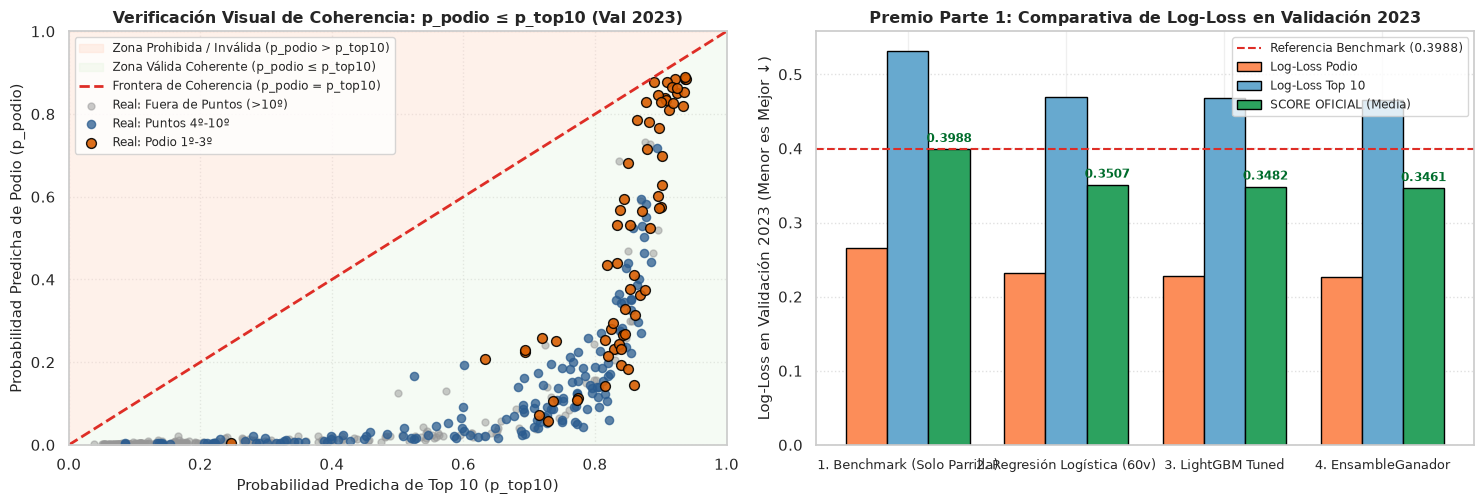

📊 3. Medianas de las probabilidades finales según el resultado real (Validación 2023):
   • Podio real (1º-3º) : mediana p_podio = 0.528 | mediana p_top10 = 0.859 | N = 66
   • Puntos 4º-10º      : mediana p_podio = 0.087 | mediana p_top10 = 0.719 | N = 154
   • Fuera de puntos    : mediana p_podio = 0.007 | mediana p_top10 = 0.235 | N = 220


In [15]:
# ==============================================================================
# 6.3 Auditoría de Coherencia (p_podio <= p_top10) y Evaluación Oficial Parte 1
# ==============================================================================

# Define la función oficial que garantiza la restricción matemática p_podio <= p_top10 para cada piloto.
def imponer_coherencia_probabilidades(p_podio_raw, p_top10_raw, eps=1e-4):
    """
    Asegura que 0 < p_podio <= p_top10 < 1 para todos los pilotos mediante
    acotación numérica y proyección monotónica punto a punto.
    """
    # Convierte las entradas a arrays de NumPy y las acota en [eps, 1 - eps] para proteger la Log-Loss.
    p_pod = np.clip(np.asarray(p_podio_raw, dtype=float), eps, 1.0 - eps)
    p_t10 = np.clip(np.asarray(p_top10_raw, dtype=float), eps, 1.0 - eps)
    
    # Impone la condición de monotonía: el podio nunca puede superar a la probabilidad de Top 10.
    p_pod_coherente = np.minimum(p_pod, p_t10)
    p_t10_coherente = np.maximum(p_pod, p_t10)
    
    # Verifica con aserción estricta que el 100% de las filas cumpla p_podio <= p_top10.
    assert np.all(p_pod_coherente <= p_t10_coherente), "❌ ERROR CRÍTICO: Violación de p_podio <= p_top10!"
    return p_pod_coherente, p_t10_coherente

# --- 1. Auditoría de Violaciones Antes y Después de la Corrección en Validación 2023 ---
violaciones_previas_bench = (p_val_podio_bench > p_val_top10_bench).sum()
violaciones_previas_lr    = (p_val_podio_lr > p_val_top10_lr).sum()
violaciones_previas_lgb   = (p_val_podio_lgb > p_val_top10_lgb).sum()
violaciones_previas_ens   = (p_val_podio_ens > p_val_top10_ens).sum()

# Aplica la proyección monotónica a los cuatro sistemas de predicción en Validación (2023).
p_val_podio_bench_ok, p_val_top10_bench_ok = imponer_coherencia_probabilidades(p_val_podio_bench, p_val_top10_bench)
p_val_podio_lr_ok,    p_val_top10_lr_ok    = imponer_coherencia_probabilidades(p_val_podio_lr,    p_val_top10_lr)
p_val_podio_lgb_ok,   p_val_top10_lgb_ok   = imponer_coherencia_probabilidades(p_val_podio_lgb,   p_val_top10_lgb)
p_val_podio_final,    p_val_top10_final    = imponer_coherencia_probabilidades(p_val_podio_ens,   p_val_top10_ens)

# Verifica explícitamente que las violaciones finales sean exactamente 0 en toda la muestra de validación.
violaciones_finales = (p_val_podio_final > p_val_top10_final).sum()
assert violaciones_finales == 0, "¡La entrega no es válida si existe alguna violación!"

print("📐 1. Auditoría de Coherencia Individual (p_podio <= p_top10) en Validación 2023 (N=440):")
print(f"   • Violaciones previas en Benchmark Parrilla : {violaciones_previas_bench}")
print(f"   • Violaciones previas en Regresión Logística: {violaciones_previas_lr}")
print(f"   • Violaciones previas en LightGBM Puro      : {violaciones_previas_lgb}")
print(f"   • Violaciones previas en Ensamble Bruto     : {violaciones_previas_ens}")
print(f"   ✅ Violaciones tras 'imponer_coherencia_probabilidades': {violaciones_finales} / {len(y_val_podio)} (100% VÁLIDO)")

# --- 2. Cálculo del Score Oficial del Premio Parte 1: Media de Log-Loss (Podio y Top 10) ---
def calcular_metricas_parte1(nombre, p_pod, p_t10, y_pod=y_val_podio, y_t10=y_val_top10):
    """Calcula Log-Loss de Podio, Log-Loss de Top 10 y el Score Oficial (Media de ambas)."""
    ll_pod = log_loss(y_pod, p_pod)
    ll_t10 = log_loss(y_t10, p_t10)
    ll_media = 0.5 * (ll_pod + ll_t10)
    auc_media = 0.5 * (roc_auc_score(y_pod, p_pod) + roc_auc_score(y_t10, p_t10))
    return {
        "Sistema / Modelo": nombre,
        "Log-Loss Podio": ll_pod,
        "Log-Loss Top 10": ll_t10,
        "SCORE OFICIAL (Media Log-Loss ↓)": ll_media,
        "ROC-AUC Medio (↑)": auc_media,
        "Coherencia (p_pod ≤ p_t10)": "100% OK" if np.all(p_pod <= p_t10) else "FALLO"
    }

# Construye la tabla maestra de evaluación de la Parte 1 sobre Validación (2023).
tabla_premio_parte1 = pd.DataFrame([
    calcular_metricas_parte1("1. Benchmark Oficial (Solo Parrilla)", p_val_podio_bench_ok, p_val_top10_bench_ok),
    calcular_metricas_parte1("2. Regresión Logística Multivariante", p_val_podio_lr_ok,    p_val_top10_lr_ok),
    calcular_metricas_parte1("3. LightGBM Classifier Tuned",         p_val_podio_lgb_ok,   p_val_top10_lgb_ok),
    calcular_metricas_parte1("4. Ensamble Final Calibrado (Ganador)", p_val_podio_final,    p_val_top10_final),
]).round(4)

# Calcula la mejora porcentual en Log-Loss Media frente al Benchmark Oficial de Parrilla.
ll_bench_oficial = tabla_premio_parte1.loc[0, "SCORE OFICIAL (Media Log-Loss ↓)"]
ll_ganador_val   = tabla_premio_parte1.loc[3, "SCORE OFICIAL (Media Log-Loss ↓)"]
mejora_pct_p1    = 100.0 * (ll_bench_oficial - ll_ganador_val) / ll_bench_oficial

print("\n🏆 2. Cuadro de Mando Oficial — Premio Parte 1 (Validación Temporada 2023):")
print(tabla_premio_parte1.to_string(index=False))
print(f"\n✨ Mejora neta sobre el Benchmark de Parrilla en Validación: -{ll_bench_oficial - ll_ganador_val:.4f} puntos de Log-Loss ({mejora_pct_p1:.2f}% de reducción de error).")

# --- 3. Visualización de Coherencia (p_podio vs p_top10) y Comparativa de Log-Loss ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Subgráfico 1: Diagrama de dispersión de p_top10 (eje X) vs p_podio (eje Y) verificando la región válida y <= x.
scatter_col = np.where(y_val_podio == 1, "#d95f02", np.where(y_val_top10 == 1, "#2b5c8f", "#bdbdbd"))
axes[0].fill_between([0, 1], [0, 1], [1, 1], color="#fee0d2", alpha=0.45, label="Zona Prohibida / Inválida (p_podio > p_top10)")
axes[0].fill_between([0, 1], [0, 0], [0, 1], color="#e5f5e0", alpha=0.35, label="Zona Válida Coherente (p_podio ≤ p_top10)")
axes[0].plot([0, 1], [0, 1], "--", color="#de2d26", lw=2, label="Frontera de Coherencia (p_podio = p_top10)")

# Dibuja los puntos coloreados según el resultado real del domingo en Validación 2023.
mask_no_pts = (y_val_top10 == 0)
mask_pts_no_pod = (y_val_top10 == 1) & (y_val_podio == 0)
mask_pod = (y_val_podio == 1)

axes[0].scatter(p_val_top10_final[mask_no_pts], p_val_podio_final[mask_no_pts], c="#969696", alpha=0.5, s=25, label="Real: Fuera de Puntos (>10º)")
axes[0].scatter(p_val_top10_final[mask_pts_no_pod], p_val_podio_final[mask_pts_no_pod], c="#2b5c8f", alpha=0.75, s=35, label="Real: Puntos 4º-10º")
axes[0].scatter(p_val_top10_final[mask_pod], p_val_podio_final[mask_pod], c="#d95f02", edgecolor="black", alpha=0.9, s=50, label="Real: Podio 1º-3º")

axes[0].set_title("Verificación Visual de Coherencia: p_podio ≤ p_top10 (Val 2023)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Probabilidad Predicha de Top 10 (p_top10)", fontsize=10.5)
axes[0].set_ylabel("Probabilidad Predicha de Podio (p_podio)", fontsize=10.5)
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(0, 1.0)
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Subgráfico 2: Comparativa del Score Oficial (Media Log-Loss) entre los 4 modelos en Validación 2023.
nombres_cortos =[   "1. Benchmark (Solo Parrilla)", 
                    "2. Regresión Logística (60v)", 
                    "3. LightGBM Tuned", 
                    "4. EnsambleGanador"]
x_pos = np.arange(len(nombres_cortos))
ancho = 0.26

axes[1].bar(x_pos - ancho, tabla_premio_parte1["Log-Loss Podio"], width=ancho, color="#fc8d59", edgecolor="black", label="Log-Loss Podio")
axes[1].bar(x_pos,         tabla_premio_parte1["Log-Loss Top 10"], width=ancho, color="#67a9cf", edgecolor="black", label="Log-Loss Top 10")
barras_media = axes[1].bar(x_pos + ancho, tabla_premio_parte1["SCORE OFICIAL (Media Log-Loss ↓)"], width=ancho, color="#2ca25f", edgecolor="black", label="SCORE OFICIAL (Media)")

axes[1].axhline(ll_bench_oficial, color="#de2d26", linestyle="--", lw=1.5, label=f"Referencia Benchmark ({ll_bench_oficial:.4f})")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(nombres_cortos, fontsize=9.5)
axes[1].set_ylabel("Log-Loss en Validación 2023 (Menor es Mejor ↓)", fontsize=10.5)
axes[1].set_title("Premio Parte 1: Comparativa de Log-Loss en Validación 2023", fontsize=11.5, fontweight="bold")
axes[1].legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white")
axes[1].grid(True, linestyle=":", alpha=0.6, axis="y")

# Añade etiquetas numéricas sobre la barra del Score Oficial para destacar la ganancia.
for b in barras_media:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 0.006, f"{h:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#006d2c")

plt.tight_layout()
plt.show()

# Resume la separación de regímenes: medianas de las probabilidades finales según el resultado real del domingo.
print("📊 3. Medianas de las probabilidades finales según el resultado real (Validación 2023):")
for etiqueta, m in [("Podio real (1º-3º)", mask_pod), ("Puntos 4º-10º", mask_pts_no_pod), ("Fuera de puntos", mask_no_pts)]:
    print(f"   • {etiqueta:<19}: mediana p_podio = {np.median(p_val_podio_final[m]):.3f} | mediana p_top10 = {np.median(p_val_top10_final[m]):.3f} | N = {int(m.sum())}")

#### **💡 Conclusiones de Coherencia y Cierre del Bloque 6 (Sección 6.3)**

1. **Garantía matemática al 100% (`0 violaciones`):**
   - Antes de corregir, solo la Regresión Logística presentaba inversiones (**4 de 440 pilotos**); LightGBM y el ensamble ya eran coherentes de por sí.
   - Tras `imponer_coherencia_probabilidades`, el **100% de las predicciones de validación (`440/440`) cumple $p_\text{podio} \le p_\text{top10}$**, como muestra el diagrama de dispersión del panel izquierdo.

2. **Separación de regímenes competitivos (medianas de las probabilidades finales):**
   - **Podio real (N = 66):** mediana $p_\text{podio}$ = **0.528** y $p_\text{top10}$ = **0.859**. Ojo: la mitad de los podios reales tenía menos de un 53% de probabilidad asignada, porque los podios "sorpresa" existen y son los que más penalizan la Log-Loss.
   - **Puntos del 4º al 10º (N = 154):** mediana $p_\text{podio}$ = **0.087** y $p_\text{top10}$ = **0.719**.
   - **Fuera de puntos (N = 220):** mediana $p_\text{podio}$ = **0.007** y $p_\text{top10}$ = **0.235**.

3. **Decisión de arquitectura para Test (2024):**
   - El **Ensamble (LightGBM + Regresión Logística, con corrección de coherencia)** obtiene el mejor **Score Oficial de la Parte 1: 0.3461** de media de Log-Loss, frente a 0.3482 de LightGBM, 0.3507 de la Logística y **0.3988 del Benchmark de Parrilla** (−13.2%).
   - La ventaja sobre LightGBM solo (0.0021) es pequeña y los pesos se han elegido sobre 2023, así que esa diferencia es optimista. Aun así, queda seleccionado como predictor oficial de probabilidades para el Bloque 8. (En la Sección 8.2 se revisa con tres temporadas: el ensamble se mantiene, pero con **peso fijo 0.5**, porque el peso ajustado en 2023 no aporta nada.)
   - Pendiente antes del Bloque 8: comprobar que, dentro de cada carrera, las $p_\text{podio}$ suman ~3 y las $p_\text{top10}$ ~10 (lo pide el reto) y valorar si conviene ajustarlas.

## **🏁 Bloque 7 · Parte 2: Predicción de la Posición Final de Carrera**


En la **Parte 2 del reto** el jefe de estrategia quiere saber **en qué posición terminará cada piloto**. Entregamos un valor numérico por piloto (`posicion_pred`) que se convierte en un orden dentro de cada carrera (el valor más bajo, primero).

Las reglas de evaluación fijan tres pilares:
1. **Métrica ganadora (Premio Parte 2):** la **correlación de Spearman** entre el orden predicho y el real **dentro de cada carrera**, promediada sobre todas las carreras:
   $$\bar{\rho} = \frac{1}{R}\sum_{r=1}^{R} \rho_\text{Spearman}\left(\text{orden\_pred}_r,\ \text{positionOrder}_r\right)$$
2. **Desempate:** el **MAE** entre la posición predicha (ya convertida en orden $1..N$) y `positionOrder`.
3. **Benchmark a batir:** el **orden de salida en parrilla**. Como vimos en el EDA, la parrilla explica muchísimo del resultado.

Probamos **cuatro enfoques y un ensamble** (el reto pide al menos dos):

| Enfoque | Modelo | Qué optimiza |
|---|---|---|
| **A. Regresión** | Ridge y LightGBM Regressor sobre `positionOrder` | Error cuadrático de la posición |
| **B. Learning to Rank** | `LGBMRanker` con objetivo `lambdarank` | El orden relativo dentro de cada carrera |
| **C. Desde probabilidades** | Posición esperada a partir de $p_\text{podio}$ y $p_\text{top10}$ de la Parte 1 | Reutiliza los modelos ya calibrados |
| **D. Ensamble** | Media de los rangos de A1, A2, B y C | Robustez frente a la variabilidad entre carreras |

**Diseño de la validación:** los hiperparámetros se eligen con **validación cruzada agrupada por carrera** (`GroupKFold`, 5 folds) dentro de Train (2014–2022). Así ningún Gran Premio queda partido entre dos folds, que es imprescindible para el ranker y para medir la Spearman por carrera. La selección final entre enfoques se hace en **Validación 2023**. El Test 2024 sigue cerrado.


### **7.1 📏 Métrica oficial de la Parte 2 y Benchmark de Parrilla**


Antes de entrenar ningún modelo dejamos fijadas las piezas comunes de evaluación:
1. **`convertir_a_orden(df, score)`:** transforma cualquier score continuo (menor = mejor) en un **orden estricto $1..N$ por carrera**. Los empates se resuelven por la posición de clasificación (`qualy_pos_clean`) con un ordenamiento estable, para que el resultado sea reproducible. Este orden será directamente nuestra `posicion_pred`, de modo que la conversión del evaluador no dependa de cómo trate los empates.
2. **`evaluar_orden(df, orden, y)`:** calcula la Spearman de cada carrera, su media (métrica oficial), mediana y mínimo, y el MAE de posición.
3. **Benchmark oficial:** ordenar a los pilotos por `grid_clean` (salida desde *pit lane* = 20). Es la referencia mínima que hay que batir.


In [16]:
# ==============================================================================
# 7.1 Métrica Oficial de la Parte 2 y Benchmark de Parrilla (Solo 'grid')
# ==============================================================================

# Importa la correlación de rangos de Spearman para medir la calidad del orden predicho en cada carrera.
from scipy.stats import spearmanr

# Importa el error absoluto medio (MAE), métrica oficial de desempate de la Parte 2.
from sklearn.metrics import mean_absolute_error

# Importa GroupKFold para validar agrupando por carrera (ningún GP queda partido entre dos folds).
from sklearn.model_selection import GroupKFold


# Define la función que convierte cualquier score continuo (menor = mejor) en un orden estricto 1..N por carrera.
def convertir_a_orden(df_meta, score, desempate="qualy_pos_clean"):
    """Devuelve el orden 1..N dentro de cada raceId (empates resueltos de forma determinista)."""
    # Construye una tabla auxiliar con la carrera, el score a ordenar y la variable de desempate.
    aux = pd.DataFrame(
        {"raceId": df_meta["raceId"].to_numpy(),
         "score": np.asarray(score, dtype=float),
         "tie": df_meta[desempate].to_numpy()},
        index=df_meta.index,
    )
    # Ordena por carrera, score y desempate con un algoritmo estable para que el resultado sea reproducible.
    aux = aux.sort_values(["raceId", "score", "tie"], kind="mergesort")
    # Numera a los pilotos 1..N dentro de cada carrera siguiendo el orden anterior.
    aux["orden"] = aux.groupby("raceId").cumcount() + 1
    # Devuelve el orden alineado con el índice original del DataFrame de entrada.
    return aux["orden"].reindex(df_meta.index).to_numpy()


# Define la función oficial de evaluación de la Parte 2: Spearman medio por carrera y MAE de posición.
def evaluar_orden(df_meta, orden_pred, y_real):
    """Calcula la Spearman por carrera (y su media) y el MAE entre orden predicho y positionOrder real."""
    # Agrupa predicción y realidad por carrera.
    aux = pd.DataFrame({"raceId": df_meta["raceId"].to_numpy(),
                        "pred": np.asarray(orden_pred, dtype=float),
                        "real": np.asarray(y_real, dtype=float)})
    # Calcula la correlación de Spearman dentro de cada Gran Premio.
    rho = pd.Series({rid: spearmanr(d["pred"], d["real"]).correlation for rid, d in aux.groupby("raceId")})
    # Devuelve el resumen de métricas y la serie de Spearman por carrera (para análisis posteriores).
    return {
        "Spearman medio (↑)": rho.mean(),
        "Spearman mediana": rho.median(),
        "Spearman mínimo": rho.min(),
        "MAE posición (↓)": mean_absolute_error(aux["real"], aux["pred"]),
    }, rho


# Define una función de Spearman media por carrera para usarla como criterio de selección en validación cruzada.
def spearman_medio(raceIds, score, y_real):
    """Spearman medio por carrera de un score continuo (menor = mejor) frente a la posición real."""
    aux = pd.DataFrame({"raceId": np.asarray(raceIds), "s": np.asarray(score, dtype=float), "y": np.asarray(y_real, dtype=float)})
    return np.mean([spearmanr(d["s"], d["y"]).correlation for _, d in aux.groupby("raceId")])


# --- Benchmark Oficial de la Parte 2: el orden de salida en parrilla ---
# Ordena a los pilotos por su parrilla efectiva (pit lane = 20) y desempata por la posición de clasificación.
orden_val_bench = convertir_a_orden(df_val, df_val["grid_clean"])

# Evalúa el benchmark de parrilla sobre la temporada de validación 2023.
metricas_bench_p2, rho_val_bench = evaluar_orden(df_val, orden_val_bench, y_val_pos)

# Verifica que el orden generado sea una permutación exacta 1..N en cada carrera de validación.
assert df_val.assign(o=orden_val_bench).groupby("raceId")["o"].apply(lambda s: sorted(s) == list(range(1, len(s) + 1))).all()

print("🏁 Benchmark Oficial Parte 2 (Orden de Parrilla) en Validación 2023:")
for k, v in metricas_bench_p2.items():
    print(f"   • {k:<20}: {v:.4f}")

# Muestra las carreras de 2023 donde la parrilla explicó mejor y peor el resultado final.
rho_bench_df = rho_val_bench.rename("spearman").to_frame().join(dfs["races"].set_index("raceId")[["round", "name"]])
print("\n🔝 GPs de 2023 donde la parrilla predijo mejor el resultado:")
print(rho_bench_df.sort_values("spearman", ascending=False).head(3).to_string())
print("\n🔻 GPs de 2023 donde la parrilla predijo peor el resultado:")
print(rho_bench_df.sort_values("spearman").head(3).to_string())

🏁 Benchmark Oficial Parte 2 (Orden de Parrilla) en Validación 2023:
   • Spearman medio (↑)  : 0.5977
   • Spearman mediana    : 0.5865
   • Spearman mínimo     : 0.1444
   • MAE posición (↓)    : 3.7091

🔝 GPs de 2023 donde la parrilla predijo mejor el resultado:
      spearman  round                   name
1101    0.9038      4  Azerbaijan Grand Prix
1120    0.8797     22   Abu Dhabi Grand Prix
1104    0.8662      6      Monaco Grand Prix

🔻 GPs de 2023 donde la parrilla predijo peor el resultado:
      spearman  round                      name
1116    0.1444     18  United States Grand Prix
1100    0.1594      3     Australian Grand Prix
1119    0.2992     21      Las Vegas Grand Prix



#### **💡 Conclusiones del Benchmark de Parrilla (Sección 7.1)**

1. **La parrilla sola ya ordena bastante bien la carrera:** en 2023 consigue una **Spearman media de 0.598** (mediana 0.587) y un **MAE de 3.71 posiciones**. Esta es la cifra a batir.
2. **La variabilidad entre carreras es enorme:** la Spearman va de **0.904 en Azerbaiyán**, 0.880 en Abu Dabi y 0.866 en Mónaco (circuitos donde adelantar es difícil) a **0.144 en Estados Unidos**, 0.159 en Australia y 0.299 en Las Vegas.
3. **Los peores casos son eventos que ningún modelo pre-carrera puede anticipar:** en Austin 2023 Hamilton y Leclerc fueron **descalificados después de la carrera** (desgaste del fondo plano) y `positionOrder` los manda al final; Australia 2023 tuvo **tres banderas rojas** y varios abandonos. Estas carreras hundirán la Spearman de cualquier enfoque.


### **7.2 📉 Enfoque A: Regresión sobre la posición final (Ridge vs LightGBM Regressor)**


El enfoque más directo: predecir `positionOrder` como un número y ordenar por la predicción. Comparamos dos familias, igual que en la Parte 1:
1. **Regresión Ridge (60 features estandarizadas):** modelo lineal con regularización $L_2$. Elegimos `alpha` maximizando la **Spearman media por carrera** en la CV agrupada (no el error cuadrático, porque lo que se evalúa es el orden).
2. **LightGBM Regressor:** mismo espacio de hiperparámetros que en la Parte 1 (12 combinaciones con `ParameterSampler`). La parada temprana usa el error `l2` de cada fold, pero **la combinación ganadora se elige por Spearman media por carrera**.

Una limitación conocida: la regresión trata igual equivocarse entre el 1º y el 2º que entre el 18º y el 19º, y los abandonos (que `positionOrder` coloca al final) generan errores grandes que tiran de las predicciones hacia el centro.


In [17]:
# ==============================================================================
# 7.2 Enfoque A: Regresión sobre la Posición Final (Ridge vs LightGBM Regressor)
# ==============================================================================

# Importa la regresión lineal con regularización L2 (Ridge).
from sklearn.linear_model import Ridge

# Define la validación cruzada agrupada por carrera (5 folds) que usaremos en toda la Parte 2.
gkf = GroupKFold(n_splits=5)
grupos_carrera_train = df_train["raceId"].to_numpy()

# --- 1. Regresión Ridge (60 features estandarizadas) ---
# Busca el parámetro de regularización alpha que maximiza la Spearman media por carrera en CV agrupada.
resultados_ridge = []
for alpha in [10.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0]:
    rhos_cv = []
    for tr_idx, va_idx in gkf.split(X_train_scaled, y_train_pos, grupos_carrera_train):
        ridge_cv = Ridge(alpha=alpha).fit(X_train_scaled.iloc[tr_idx], y_train_pos.iloc[tr_idx])
        rhos_cv.append(spearman_medio(grupos_carrera_train[va_idx], ridge_cv.predict(X_train_scaled.iloc[va_idx]), y_train_pos.iloc[va_idx]))
    resultados_ridge.append((alpha, np.mean(rhos_cv)))

# Selecciona el alpha con mayor Spearman media en CV.
alpha_opt = sorted(resultados_ridge, key=lambda x: -x[1])[0][0]

# Entrena la Ridge definitiva sobre el 100% de Train y predice la posición en Validación 2023.
modelo_ridge_pos = Ridge(alpha=alpha_opt).fit(X_train_scaled, y_train_pos)
s_val_ridge = modelo_ridge_pos.predict(X_val_scaled)
orden_val_ridge = convertir_a_orden(df_val, s_val_ridge)
metricas_ridge, rho_val_ridge = evaluar_orden(df_val, orden_val_ridge, y_val_pos)

print(f"📈 1. Regresión Ridge (alpha={alpha_opt}) en Validación 2023:")
print(f"   • Spearman medio: {metricas_ridge['Spearman medio (↑)']:.4f} | MAE: {metricas_ridge['MAE posición (↓)']:.4f}")

# --- 2. LightGBM Regressor con búsqueda de hiperparámetros en CV agrupada por carrera ---
# Parámetros fijos del regresor (pérdida cuadrática sobre positionOrder).
fijos_lgb_reg = {
    "objective": "regression",
    "metric": "l2",
    "boosting_type": "gbdt",
    "subsample_freq": 1,
    "random_state": SEED,
    **LGB_DETERMINISTA,  # hilos fijos + modo determinista (ver CONFIG)
    "verbose": -1,
}

# Ejecuta la búsqueda aleatoria de 12 combinaciones (mismo espacio que en la Parte 1) con early stopping.
resultados_cv_reg = []
for params_cand in ParameterSampler(espacio_lgb_podio, n_iter=12, random_state=SEED):
    rhos_cv, iters_cv = [], []
    for tr_idx, va_idx in gkf.split(X_train, y_train_pos, grupos_carrera_train):
        reg_cv = lgb.LGBMRegressor(n_estimators=1500, **fijos_lgb_reg, **params_cand)
        reg_cv.fit(
            X_train.iloc[tr_idx], y_train_pos.iloc[tr_idx],
            eval_set=[(X_train.iloc[va_idx], y_train_pos.iloc[va_idx])],
            callbacks=[lgb.early_stopping(50, verbose=False)],
        )
        rhos_cv.append(spearman_medio(grupos_carrera_train[va_idx], reg_cv.predict(X_train.iloc[va_idx]), y_train_pos.iloc[va_idx]))
        iters_cv.append(reg_cv.best_iteration_ or 100)
    resultados_cv_reg.append({**params_cand, "n_estimators": int(np.mean(iters_cv)), "cv_spearman": np.mean(rhos_cv), "cv_std": np.std(rhos_cv)})

# Ordena las combinaciones por mayor Spearman media en CV y extrae la ganadora.
tabla_cv_reg = pd.DataFrame(resultados_cv_reg).sort_values("cv_spearman", ascending=False).reset_index(drop=True)
mejor_cfg_reg = tabla_cv_reg.iloc[0]
best_params_reg = {k: (int(mejor_cfg_reg[k]) if k in params_enteros else float(mejor_cfg_reg[k])) for k in espacio_lgb_podio}
n_arboles_reg = max(50, int(mejor_cfg_reg["n_estimators"]))

# Entrena el regresor LightGBM definitivo sobre el 100% de Train y predice Validación 2023.
modelo_lgb_reg = lgb.LGBMRegressor(n_estimators=n_arboles_reg, **fijos_lgb_reg, **best_params_reg)
modelo_lgb_reg.fit(X_train, y_train_pos)
s_val_lgb_reg = modelo_lgb_reg.predict(X_val)
orden_val_lgb_reg = convertir_a_orden(df_val, s_val_lgb_reg)
metricas_lgb_reg, rho_val_lgb_reg = evaluar_orden(df_val, orden_val_lgb_reg, y_val_pos)

print(f"\n🚀 2. LightGBM Regressor ({n_arboles_reg} árboles | CV Spearman={mejor_cfg_reg['cv_spearman']:.4f}) en Validación 2023:")
print(f"   • Spearman medio: {metricas_lgb_reg['Spearman medio (↑)']:.4f} | MAE: {metricas_lgb_reg['MAE posición (↓)']:.4f}")

# Muestra el top 10 de variables por ganancia del regresor LightGBM.
imp_reg = pd.Series(modelo_lgb_reg.booster_.feature_importance(importance_type="gain"), index=FEATURES_COLS)
imp_reg_pct = (100.0 * imp_reg / imp_reg.sum()).sort_values(ascending=False)
print("\n🔧 Top 10 variables por ganancia (Gain %) — LightGBM Regressor:")
print(imp_reg_pct.head(10).round(2).to_string())

📈 1. Regresión Ridge (alpha=1000.0) en Validación 2023:
   • Spearman medio: 0.6604 | MAE: 3.3045



🚀 2. LightGBM Regressor (81 árboles | CV Spearman=0.6490) en Validación 2023:
   • Spearman medio: 0.6606 | MAE: 3.3364

🔧 Top 10 variables por ganancia (Gain %) — LightGBM Regressor:
qualy_pos_clean          34.5800
sprint_pos               20.9500
grid_x_circ_difficulty    8.3100
q_gap_pct                 5.0600
drv_pos_roll10            4.3300
grid_clean                3.0500
con_mean_pos_roll5        2.7000
con_pos_ewm5              2.3400
con_champ_pos_prev        1.7100
drv_champ_pos_prev        1.6900


#### **💡 Conclusiones de la Regresión sobre la Posición (Sección 7.2)**

1. **Ambos regresores baten con claridad a la parrilla:** LightGBM alcanza una **Spearman media de 0.661** (MAE 3.34) y Ridge **0.660** (MAE 3.30), frente a 0.598 y 3.71 de la parrilla.
2. **El modelo lineal rinde igual que los árboles:** la relación entre las variables y la posición es en gran medida monótona y casi lineal. Ridge necesita una regularización fuerte (`alpha = 1000`, un valor interior de la rejilla) por la colinealidad entre las 60 variables, y LightGBM se queda con solo **81 árboles**.
3. **La CV agrupada es coherente con 2023:** en LightGBM la Spearman de CV (0.649) y la de validación (0.661) son muy parecidas, a diferencia del optimismo de la CV no agrupada de la Parte 1.
4. **Importancia de variables:** de nuevo dominan las del sábado (`qualy_pos_clean` 34.6%, `sprint_pos` 21.0%, `grid_x_circ_difficulty` 8.3%, `q_gap_pct` 5.1%, `grid_clean` 3.1%). Del historial destacan la forma del piloto (`drv_pos_roll10`, 4.3%) y el ritmo del constructor (`con_mean_pos_roll5`, 2.7%; `con_pos_ewm5`, 2.3%).

### **7.3 🏆 Enfoque B: Learning to Rank con `LGBMRanker` (objetivo `lambdarank`)**


Un modelo de ranking no intenta acertar el número de la posición, sino **el orden relativo entre los pilotos de una misma carrera**, que es justo lo que mide la Spearman. Configuración:
- **Grupos:** cada Gran Premio es un grupo (una "consulta"). Comprobamos que las filas de cada carrera son contiguas, requisito de LightGBM.
- **Relevancia:** `rel = N_carrera - positionOrder` (el ganador recibe $N-1$ y el último 0).
- **Ganancia lineal (`label_gain = 0, 1, 2, …`):** la ganancia por defecto de lambdarank ($2^{rel}-1$) concentra todo el peso en la cabeza de carrera. Con ganancia lineal y `lambdarank_truncation_level = 30` todas las parejas de la parrilla cuentan, lo que se parece más a la Spearman.
- **Selección:** mismo espacio de 12 combinaciones, parada temprana sobre NDCG y elección final por **Spearman media por carrera** en la CV agrupada.


In [18]:
# ==============================================================================
# 7.3 Enfoque B: Learning to Rank con LGBMRanker (objetivo lambdarank)
# ==============================================================================

# Construye la etiqueta de relevancia por carrera: el ganador recibe N-1 y el último 0 (mayor = mejor).
n_por_carrera_train = df_train.groupby("raceId")["raceId"].transform("size")
n_por_carrera_val = df_val.groupby("raceId")["raceId"].transform("size")
rel_train = (n_por_carrera_train - df_train["positionOrder"]).clip(lower=0).astype(int)
rel_val = (n_por_carrera_val - df_val["positionOrder"]).clip(lower=0).astype(int)

# Ganancia LINEAL por nivel de relevancia: queremos ordenar bien toda la parrilla, no solo la cabeza (gain 2^rel-1).
ganancia_lineal = list(range(0, 41))

# Parámetros fijos del ranker: lambdarank sobre la lista completa de cada carrera (truncation = toda la parrilla).
fijos_lgb_rank = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "label_gain": ganancia_lineal,
    "lambdarank_truncation_level": 30,
    "boosting_type": "gbdt",
    "subsample_freq": 1,
    "random_state": SEED,
    **LGB_DETERMINISTA,  # hilos fijos + modo determinista (ver CONFIG)
    "verbose": -1,
}


# Define una función auxiliar que calcula el tamaño de cada grupo (carrera) respetando el orden de las filas.
def tamanos_grupo(raceIds):
    """Tamaño de cada bloque contiguo de raceId (requisito de LightGBM para ranking)."""
    s = pd.Series(np.asarray(raceIds))
    return s.groupby((s != s.shift()).cumsum()).size().to_numpy()


# Comprueba que en Train y Validación cada carrera ocupe un bloque contiguo de filas (si no, los grupos serían erróneos).
assert len(tamanos_grupo(df_train["raceId"])) == df_train["raceId"].nunique()
assert len(tamanos_grupo(df_val["raceId"])) == df_val["raceId"].nunique()

# Ejecuta la búsqueda aleatoria de 12 combinaciones con CV agrupada por carrera y early stopping sobre NDCG.
resultados_cv_rank = []
for params_cand in ParameterSampler(espacio_lgb_podio, n_iter=12, random_state=SEED):
    rhos_cv, iters_cv = [], []
    for tr_idx, va_idx in gkf.split(X_train, rel_train, grupos_carrera_train):
        rank_cv = lgb.LGBMRanker(n_estimators=1500, **fijos_lgb_rank, **params_cand)
        rank_cv.fit(
            X_train.iloc[tr_idx], rel_train.iloc[tr_idx], group=tamanos_grupo(grupos_carrera_train[tr_idx]),
            eval_set=[(X_train.iloc[va_idx], rel_train.iloc[va_idx])],
            eval_group=[tamanos_grupo(grupos_carrera_train[va_idx])],
            eval_at=[30],
            callbacks=[lgb.early_stopping(50, verbose=False)],
        )
        # El ranker devuelve un score donde MAYOR = mejor; lo invertimos para que menor = mejor posición.
        rhos_cv.append(spearman_medio(grupos_carrera_train[va_idx], -rank_cv.predict(X_train.iloc[va_idx]), y_train_pos.iloc[va_idx]))
        iters_cv.append(rank_cv.best_iteration_ or 100)
    resultados_cv_rank.append({**params_cand, "n_estimators": int(np.mean(iters_cv)), "cv_spearman": np.mean(rhos_cv), "cv_std": np.std(rhos_cv)})

# Ordena las combinaciones por mayor Spearman media en CV y extrae la ganadora.
tabla_cv_rank = pd.DataFrame(resultados_cv_rank).sort_values("cv_spearman", ascending=False).reset_index(drop=True)
mejor_cfg_rank = tabla_cv_rank.iloc[0]
best_params_rank = {k: (int(mejor_cfg_rank[k]) if k in params_enteros else float(mejor_cfg_rank[k])) for k in espacio_lgb_podio}
n_arboles_rank = max(50, int(mejor_cfg_rank["n_estimators"]))

# Entrena el LGBMRanker definitivo sobre el 100% de Train y predice el orden de Validación 2023.
modelo_lgb_rank = lgb.LGBMRanker(n_estimators=n_arboles_rank, **fijos_lgb_rank, **best_params_rank)
modelo_lgb_rank.fit(X_train, rel_train, group=tamanos_grupo(df_train["raceId"]))
s_val_rank = -modelo_lgb_rank.predict(X_val)
orden_val_rank = convertir_a_orden(df_val, s_val_rank)
metricas_rank, rho_val_rank = evaluar_orden(df_val, orden_val_rank, y_val_pos)

print(f"🏆 LGBMRanker lambdarank ({n_arboles_rank} árboles | CV Spearman={mejor_cfg_rank['cv_spearman']:.4f}) en Validación 2023:")
print(f"   • Spearman medio: {metricas_rank['Spearman medio (↑)']:.4f} | MAE: {metricas_rank['MAE posición (↓)']:.4f}")

# Muestra el top 10 de variables por ganancia del ranker.
imp_rank = pd.Series(modelo_lgb_rank.booster_.feature_importance(importance_type="gain"), index=FEATURES_COLS)
imp_rank_pct = (100.0 * imp_rank / imp_rank.sum()).sort_values(ascending=False)
print("\n🔧 Top 10 variables por ganancia (Gain %) — LGBMRanker:")
print(imp_rank_pct.head(10).round(2).to_string())

🏆 LGBMRanker lambdarank (59 árboles | CV Spearman=0.6479) en Validación 2023:
   • Spearman medio: 0.6470 | MAE: 3.4409

🔧 Top 10 variables por ganancia (Gain %) — LGBMRanker:
qualy_pos_clean          44.8000
sprint_pos               29.4700
grid_x_circ_difficulty    3.6900
con_mean_pos_roll5        3.1600
drv_pos_roll10            2.0100
drv_qgap_roll3            1.8400
drv_points_roll5          1.7700
q_gap_pct                 1.5400
con_points_roll3          1.3800
con_pos_ewm5              1.2200


#### **💡 Conclusiones del Modelo de Ranking (Sección 7.3)**

1. **El ranker también bate a la parrilla, pero es el más flojo de los enfoques:** **Spearman media de 0.647** y MAE de 3.44 en 2023 (CV: 0.648, muy estable).
2. **Por qué no gana pese a ser "el modelo natural" para ordenar:**
   - `lambdarank` optimiza **NDCG**, que aun con ganancia lineal da más peso a las primeras posiciones que la Spearman, que trata por igual toda la parrilla.
   - La parada temprana se detiene muy pronto (**59 árboles**) y el modelo se queda muy cerca de la clasificación: `qualy_pos_clean` (44.8%) y `sprint_pos` (29.5%) acaparan casi el 75% de la ganancia.
3. **Conclusión práctica:** el ranker aporta un punto de vista distinto que puede ser útil dentro de un ensamble, pero como modelo único no supera a la regresión.

### **7.4 🎲 Enfoque C: Orden derivado de las probabilidades de la Parte 1**


Ya tenemos dos probabilidades bien calibradas por piloto. Podemos convertirlas en una **posición esperada** dividiendo la clasificación en tres tramos:

$$E[\text{pos}] \approx p_\text{podio}\cdot \overline{\text{pos}}_{1\text{-}3} + (p_\text{top10} - p_\text{podio})\cdot \overline{\text{pos}}_{4\text{-}10} + (1 - p_\text{top10})\cdot \overline{\text{pos}}_{>10}$$

donde cada $\overline{\text{pos}}$ es la posición media real de ese tramo en Train. Las tres probabilidades de tramo son no negativas y suman 1 gracias a la restricción $p_\text{podio} \le p_\text{top10}$. Este enfoque **no entrena ningún modelo nuevo** y garantiza que la Parte 1 y la Parte 2 cuentan la misma historia.


In [19]:
# ==============================================================================
# 7.4 Enfoque C: Orden Derivado de las Probabilidades de la Parte 1
# ==============================================================================

# Calcula la posición media real de cada tramo en Train: podio (1-3), puntos sin podio (4-10) y fuera de puntos (>10).
pos_media_podio = df_train.loc[df_train["positionOrder"] <= 3, "positionOrder"].mean()
pos_media_puntos = df_train.loc[(df_train["positionOrder"] > 3) & (df_train["positionOrder"] <= 10), "positionOrder"].mean()
pos_media_fuera = df_train.loc[df_train["positionOrder"] > 10, "positionOrder"].mean()


# Define la posición esperada como mezcla de los tres tramos ponderada por las probabilidades coherentes.
def posicion_esperada(p_pod, p_t10):
    """E[pos] ≈ p_podio·pos(1-3) + (p_top10 - p_podio)·pos(4-10) + (1 - p_top10)·pos(>10)."""
    return p_pod * pos_media_podio + (p_t10 - p_pod) * pos_media_puntos + (1.0 - p_t10) * pos_media_fuera


# Aplica la fórmula a las probabilidades finales (ensamble + coherencia) de la Parte 1 en Validación 2023.
s_val_prob = posicion_esperada(p_val_podio_final, p_val_top10_final)
orden_val_prob = convertir_a_orden(df_val, s_val_prob)
metricas_prob, rho_val_prob = evaluar_orden(df_val, orden_val_prob, y_val_pos)

print(f"🎲 Posiciones medias por tramo en Train: podio = {pos_media_podio:.2f} | puntos 4-10 = {pos_media_puntos:.2f} | fuera de puntos = {pos_media_fuera:.2f}")
print(f"\n🎲 Orden derivado de p_podio y p_top10 (Parte 1) en Validación 2023:")
print(f"   • Spearman medio: {metricas_prob['Spearman medio (↑)']:.4f} | MAE: {metricas_prob['MAE posición (↓)']:.4f}")

🎲 Posiciones medias por tramo en Train: podio = 2.00 | puntos 4-10 = 7.00 | fuera de puntos = 15.72

🎲 Orden derivado de p_podio y p_top10 (Parte 1) en Validación 2023:
   • Spearman medio: 0.6571 | MAE: 3.3136


#### **💡 Conclusiones del Orden desde Probabilidades (Sección 7.4)**

1. **Sin entrenar nada nuevo, iguala a los modelos específicos:** con posiciones medias por tramo de 2.00, 7.00 y 15.72, el orden derivado logra una **Spearman media de 0.657** y un MAE de 3.31 (el segundo mejor, tras Ridge), y la **mediana por carrera más alta de todos los enfoques (0.698)**.
2. **Coherencia entre las dos partes del reto:** las probabilidades de la Parte 1 no solo están calibradas, sino que también **ordenan** bien a los pilotos. Que un piloto tenga más $p_\text{podio}$ que otro implica que lo esperamos por delante.
3. **Limitación:** dentro de un mismo tramo (por ejemplo, entre los pilotos casi sin opciones de puntuar) el orden depende solo de pequeñas diferencias de $p_\text{top10}$, así que discrimina peor la cola de la parrilla.

### **7.5 🤝 Ensamble de rankings, comparativa final y selección del modelo de la Parte 2**


Los cuatro enfoques miran el problema desde ángulos distintos (lineal, árboles, ranking y probabilidades). Para combinarlos sin sobreajustar 2023:
- Convertimos cada predicción en **rango dentro de su carrera** (escala común $1..N$).
- Hacemos la **media simple de los cuatro rangos** (A1, A2, B y C), **sin ajustar pesos en validación**: con solo 22 carreras, cualquier peso optimizado se ajustaría al ruido de 2023.
- El modelo de la Parte 2 se elige por **mayor Spearman media en 2023** y, en caso de empate a 4 decimales, por **menor MAE** (el mismo criterio que el reto).


🏁 Cuadro de Mando Oficial — Premio Parte 2 (Validación Temporada 2023):
                        Sistema / Modelo  Spearman medio (↑)  Spearman mediana  Spearman mínimo  MAE posición (↓)
0. Benchmark Oficial (Orden de Parrilla)              0.5977            0.5865           0.1444            3.7091
      A1. Regresión Ridge (alpha=1000.0)              0.6604            0.6707           0.2015            3.3045
     A2. LightGBM Regressor (81 árboles)              0.6606            0.6789           0.2466            3.3364
   B. LGBMRanker lambdarank (59 árboles)              0.6470            0.6729           0.1624            3.4409
 C. Orden desde Probabilidades (Parte 1)              0.6571            0.6977           0.2045            3.3136
 D. Ensamble de Rangos (A1 + A2 + B + C)              0.6550            0.6759           0.2060            3.3318

🥇 Modelo seleccionado para la Parte 2: A2. LightGBM Regressor (81 árboles)
   • Spearman medio: 0.6606 frente a 0.5977 de la parr

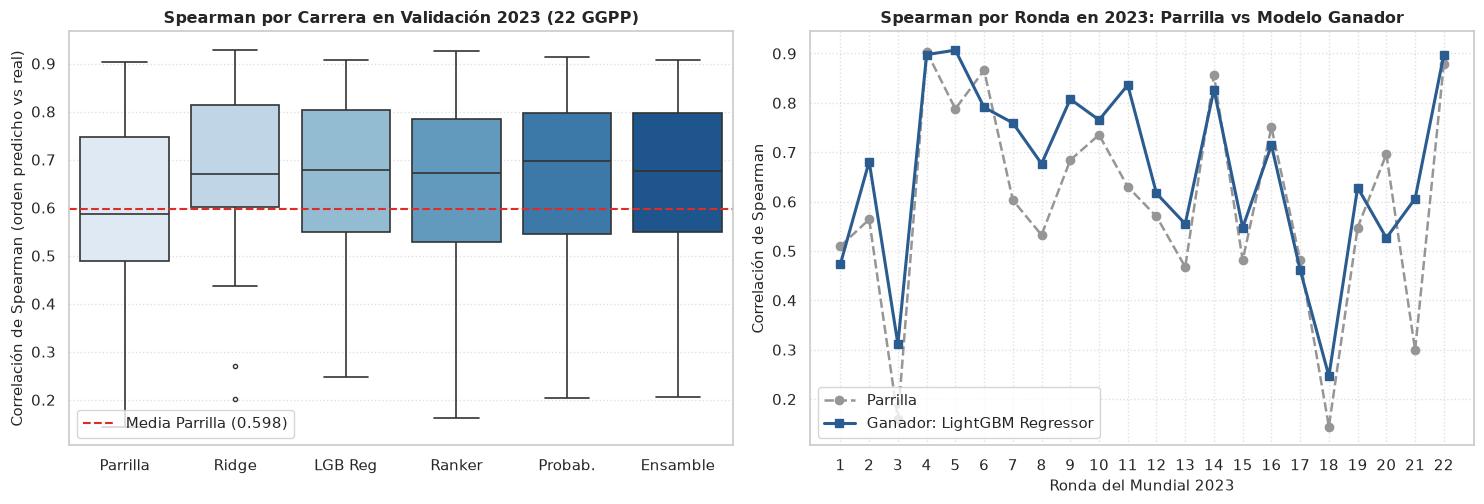

In [20]:
# ==============================================================================
# 7.5 Ensamble de Rankings, Comparativa Final y Selección del Modelo de la Parte 2
# ==============================================================================

# Convierte cada score continuo en rango dentro de su carrera (escala común 1..N para poder promediarlos).
rk_ridge = orden_val_ridge.astype(float)
rk_reg = orden_val_lgb_reg.astype(float)
rk_rank = orden_val_rank.astype(float)
rk_prob = orden_val_prob.astype(float)

# Ensamble de los cuatro rangos con pesos iguales (sin ajustar pesos en validación para no sobreajustar 2023).
s_val_ens_p2 = (rk_ridge + rk_reg + rk_rank + rk_prob) / 4.0
orden_val_ens_p2 = convertir_a_orden(df_val, s_val_ens_p2)
metricas_ens_p2, rho_val_ens_p2 = evaluar_orden(df_val, orden_val_ens_p2, y_val_pos)

# Construye la tabla comparativa oficial de la Parte 2 sobre Validación 2023.
tabla_premio_parte2 = pd.DataFrame([
    {"Sistema / Modelo": "0. Benchmark Oficial (Orden de Parrilla)", **metricas_bench_p2},
    {"Sistema / Modelo": f"A1. Regresión Ridge (alpha={alpha_opt})", **metricas_ridge},
    {"Sistema / Modelo": f"A2. LightGBM Regressor ({n_arboles_reg} árboles)", **metricas_lgb_reg},
    {"Sistema / Modelo": f"B. LGBMRanker lambdarank ({n_arboles_rank} árboles)", **metricas_rank},
    {"Sistema / Modelo": "C. Orden desde Probabilidades (Parte 1)", **metricas_prob},
    {"Sistema / Modelo": "D. Ensamble de Rangos (A1 + A2 + B + C)", **metricas_ens_p2},
]).round(4)

print("🏁 Cuadro de Mando Oficial — Premio Parte 2 (Validación Temporada 2023):")
print(tabla_premio_parte2.to_string(index=False))

# Selecciona el ganador por mayor Spearman medio y, en caso de empate a 4 decimales, por menor MAE.
candidatos_p2 = tabla_premio_parte2.iloc[1:].sort_values(["Spearman medio (↑)", "MAE posición (↓)"], ascending=[False, True])
MODELO_GANADOR_P2 = candidatos_p2.iloc[0]["Sistema / Modelo"]
rho_bench_p2 = metricas_bench_p2["Spearman medio (↑)"]
rho_ganador_p2 = candidatos_p2.iloc[0]["Spearman medio (↑)"]

# Cuenta en cuántas carreras de 2023 el ganador ordena mejor que la parrilla.
rhos_por_modelo = {
    "Parrilla": rho_val_bench, "Ridge": rho_val_ridge, "LGB Reg": rho_val_lgb_reg,
    "Ranker": rho_val_rank, "Probab.": rho_val_prob, "Ensamble": rho_val_ens_p2,
}
mapa_rho = {"A1": rho_val_ridge, "A2": rho_val_lgb_reg, "B.": rho_val_rank, "C.": rho_val_prob, "D.": rho_val_ens_p2}
rho_val_ganador = mapa_rho[MODELO_GANADOR_P2[:2]]
carreras_mejor = int((rho_val_ganador > rho_val_bench).sum())

print(f"\n🥇 Modelo seleccionado para la Parte 2: {MODELO_GANADOR_P2}")
print(f"   • Spearman medio: {rho_ganador_p2:.4f} frente a {rho_bench_p2:.4f} de la parrilla (+{rho_ganador_p2 - rho_bench_p2:.4f})")
print(f"   • Supera a la parrilla en {carreras_mejor} de {len(rho_val_bench)} carreras de 2023")

# --- Visualización: distribución de Spearman por carrera y evolución a lo largo de la temporada 2023 ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Subgráfico 1: boxplot de la Spearman por carrera para cada enfoque.
df_box = pd.DataFrame(rhos_por_modelo)
sns.boxplot(data=df_box, ax=axes[0], palette="Blues", linewidth=1.2, fliersize=3)
axes[0].axhline(rho_bench_p2, color="#de2d26", linestyle="--", lw=1.5, label=f"Media Parrilla ({rho_bench_p2:.3f})")
axes[0].set_title("Spearman por Carrera en Validación 2023 (22 GGPP)", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Correlación de Spearman (orden predicho vs real)", fontsize=10.5)
axes[0].legend(loc="lower left", frameon=True, facecolor="white")
axes[0].grid(True, linestyle=":", alpha=0.6, axis="y")

# Subgráfico 2: Spearman por ronda de 2023, parrilla frente al modelo ganador.
rondas_val = dfs["races"].set_index("raceId").loc[rho_val_bench.index, "round"]
orden_rondas = np.argsort(rondas_val.to_numpy())
axes[1].plot(rondas_val.to_numpy()[orden_rondas], rho_val_bench.to_numpy()[orden_rondas], "o--", color="#969696", lw=1.8, label="Parrilla")
axes[1].plot(rondas_val.to_numpy()[orden_rondas], rho_val_ganador.to_numpy()[orden_rondas], "s-", color="#2b5c8f", lw=2.2, label=f"Ganador: {MODELO_GANADOR_P2.split('. ', 1)[1].split(' (')[0]}")
axes[1].set_title("Spearman por Ronda en 2023: Parrilla vs Modelo Ganador", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Ronda del Mundial 2023", fontsize=10.5)
axes[1].set_ylabel("Correlación de Spearman", fontsize=10.5)
axes[1].set_xticks(range(1, 23))
axes[1].legend(loc="lower left", frameon=True, facecolor="white")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### **💡 Conclusiones y cierre del Bloque 7 (Sección 7.5)**

1. **Todos los enfoques baten a la parrilla:** la Spearman media de 2023 pasa de **0.598** (parrilla) a entre **0.647** (ranker) y **0.661** (LightGBM Regressor), y el MAE baja de **3.71** a **3.30–3.44** posiciones.
2. **Modelo seleccionado, aplicando la regla fijada de antemano (mayor Spearman media; MAE como desempate): LightGBM Regressor**, con una **Spearman de 0.6606** y un MAE de 3.34. Supera a la parrilla en **15 de las 22 carreras** de 2023.
3. **Las diferencias entre los mejores enfoques son ruido:** LightGBM (0.6606), Ridge (0.6604), el orden desde probabilidades (0.6571) y el ensamble (0.6550) están separados por menos de 0.006, mientras que de una carrera a otra la Spearman va de ~0.16 a ~0.93. De hecho, antes de unificar el linaje de las escuderías (Bloque 4) el ganador era el ensamble. Respetamos la regla en lugar de elegir "a mano", pero **en 2024 cabe esperar que cualquiera de estos enfoques rinda de forma muy parecida**.
4. **Dónde fallan todos:** en Estados Unidos (ronda 18) y Australia (ronda 3) todos los modelos se quedan en una Spearman de ~0.2–0.3. Son las carreras de las descalificaciones y las banderas rojas: incertidumbre que no está en los datos del sábado.
5. **Revisión en el Bloque 8:** como las diferencias son ruido, en la **Sección 8.4** se repite la comparación con tres temporadas (2021–2023) y se aplica la regla de la opción más sencilla. **El modelo final de la Parte 2 sale de ahí** (el orden derivado de las probabilidades), no de esta sección.

## **📈 Bloque 8 · Evaluación Final en Test (Temporada 2024) y Entrega**


Es el momento de abrir la caja fuerte. Hasta ahora **ninguna decisión se ha tomado mirando 2024**, y este bloque mantiene esa regla: primero se cierran las últimas decisiones con Validación 2023, después se congelan los modelos y solo entonces se predice y se evalúa la temporada 2024, **una única vez**.

Pasos del bloque:
1. **8.1 · Sumas por carrera:** el reto pide comprobar que, dentro de cada carrera, las $p_\text{podio}$ suman ~3 y las $p_\text{top10}$ ~10, y pensar si conviene ajustarlas.
2. **8.2 a 8.4 · Validación de origen móvil (2021–2023):** revisamos con 66 carreras fuera de muestra todas las decisiones (8.2: modelo, forma de mezclar y ajustes de la Parte 1, incluidas las variables de ritmo de carrera de la Sección 4.2; 8.3: número de variables; 8.4: modelo de la Parte 2, incluido un modelo ordinal de la distribución completa de la posición) y nos quedamos con la **opción más sencilla** salvo mejora relevante.
3. **8.5 · Reentrenamiento final:** reentrenamos todos los modelos con **Train + Validación (2014–2023)** usando los hiperparámetros, pesos y decisiones ya elegidos. No se reajusta nada.
4. **8.6 · Parte 1 en Test:** probabilidades de podio y top 10 de 2024 frente al benchmark de parrilla.
5. **8.7 · Parte 2 en Test:** orden final de carrera de 2024 frente al orden de parrilla.
6. **8.8 · Análisis de errores:** abandonos, equipos que cambian de nivel y carreras caóticas (lluvia, incidentes), que no están en los datos.
7. **8.9 · Entrega:** exportación y validación del CSV con `resultId, raceId, driverId, p_podio, p_top10, posicion_pred`.

**Forma reciente dentro de 2024:** las variables de forma (medias móviles, mundial previo, historial del constructor…) se calcularon en el Bloque 4 con `shift(1)` sobre todo el calendario. Para predecir, por ejemplo, Abu Dabi 2024, el modelo ya sabe lo que pasó en Las Vegas, pero **nunca usa nada de la propia carrera**, y los modelos no se reentrenan con datos de 2024.


### **8.1 Σ Sumas por carrera: ¿suman ~3 las $p_\text{podio}$ y ~10 las $p_\text{top10}$?**


En cada Gran Premio hay **exactamente 3 podios** y **exactamente 10 puestos de top 10** (`positionOrder` siempre asigna las posiciones 1..N). Por tanto, unas probabilidades coherentes deberían cumplir dentro de cada carrera:
$$\sum_{i \in \text{carrera}} p_{\text{podio}, i} = 3, \qquad \sum_{i \in \text{carrera}} p_{\text{top10}, i} = 10$$

Nuestros modelos predicen cada piloto por separado, así que esta restricción no se cumple sola. Proponemos un ajuste en **escala logit**: a todos los pilotos de una carrera se les suma la misma constante $c_r$, buscada por bisección, hasta que la suma es exactamente el objetivo:
$$p^{\text{aj}}_{i} = \sigma\left(\text{logit}(p_i) + c_r\right)$$
- **Conserva el orden** de los pilotos dentro de la carrera (la transformación es monótona).
- **Mantiene todas las probabilidades dentro de $(0, 1)$**, a diferencia de un simple reescalado multiplicativo.
- Después se vuelve a imponer $p_\text{podio} \le p_\text{top10}$.

**La decisión de aplicarlo se toma con Validación 2023:** solo se ajusta un target si su Log-Loss mejora en 2023.


Σ 1. Sumas por carrera de las probabilidades finales en Validación 2023 (22 GGPP):
   • Σ p_podio  → media 2.854 | mín 2.465 | máx 3.583 | objetivo 3
   • Σ p_top10  → media 10.114 | mín 9.344 | máx 11.026 | objetivo 10

Σ 2. Efecto del ajuste por carrera sobre el Score Oficial de la Parte 1 (Validación 2023):
                        Sistema / Modelo  Log-Loss Podio  Log-Loss Top 10  SCORE OFICIAL (Media Log-Loss ↓)  ROC-AUC Medio (↑) Coherencia (p_pod ≤ p_t10)
Sin ajuste (probabilidades del Bloque 6)          0.2264           0.4658                            0.3461             0.8941                    100% OK
             Ajuste solo p_podio (Σ = 3)          0.2246           0.4658                            0.3452             0.8953                    100% OK
            Ajuste solo p_top10 (Σ = 10)          0.2264           0.4641                            0.3453             0.8941                    100% OK
        Ajuste de ambas (Σ = 3 y Σ = 10)          0.2246           0.464


✅ Decisión para Test 2024: ajustar p_podio = True | ajustar p_top10 = True


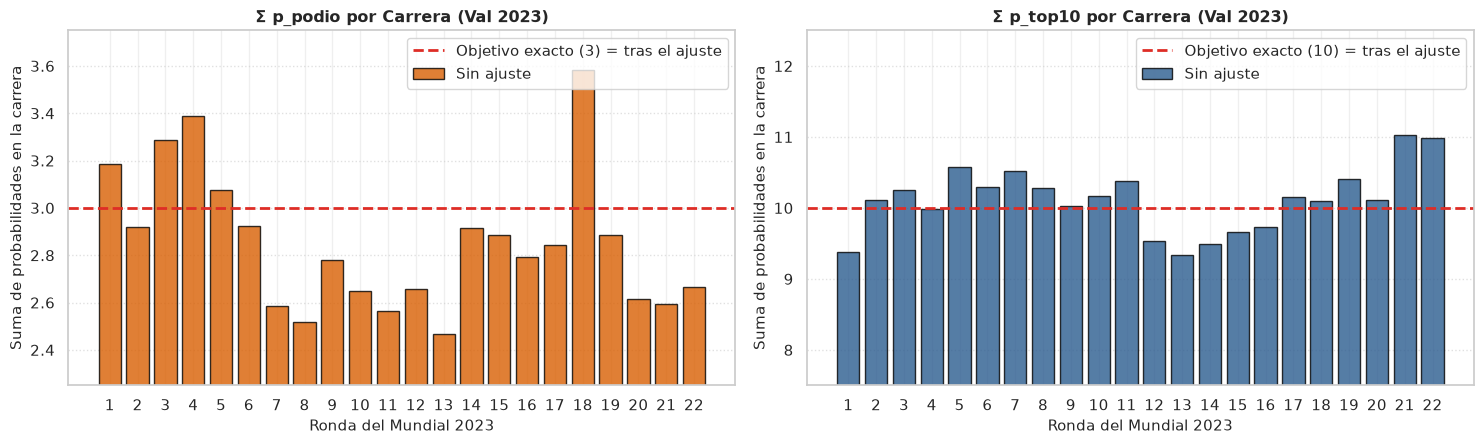

In [21]:
# ==============================================================================
# 8.1 Coherencia por Carrera: ¿Suman ~3 las p_podio y ~10 las p_top10? (Validación 2023)
# ==============================================================================


# Define la función que ajusta las probabilidades de cada carrera para que sumen exactamente un objetivo.
def ajustar_suma_carrera(df_meta, p, objetivo, eps=1e-4, n_iter=60):
    """Desplaza en escala logit (misma constante para todos los pilotos de una carrera) hasta que la suma sea 'objetivo'.
    Conserva el orden de los pilotos dentro de la carrera y mantiene todas las probabilidades en (0, 1)."""
    # Pasa las probabilidades a escala logit (acotadas para evitar infinitos).
    p = np.clip(np.asarray(p, dtype=float), eps, 1.0 - eps)
    logit = np.log(p / (1.0 - p))
    p_aj = np.empty_like(p)
    # Recorre cada carrera usando las posiciones (no etiquetas) de sus filas.
    for _, idx in df_meta.groupby("raceId").indices.items():
        z = logit[idx]
        # El objetivo nunca puede superar el número de pilotos de la carrera.
        k = min(objetivo, len(idx))
        # Búsqueda binaria de la constante c tal que sum(sigmoid(z + c)) = k (la suma es creciente en c).
        lo, hi = -30.0, 30.0
        for _ in range(n_iter):
            c = 0.5 * (lo + hi)
            if (1.0 / (1.0 + np.exp(-(z + c)))).sum() > k:
                hi = c
            else:
                lo = c
        p_aj[idx] = 1.0 / (1.0 + np.exp(-(z + 0.5 * (lo + hi))))
    # Devuelve las probabilidades ajustadas, acotadas de nuevo por seguridad para la Log-Loss.
    return np.clip(p_aj, eps, 1.0 - eps)


# Define una función que resume las sumas por carrera de un vector de probabilidades.
def sumas_por_carrera(df_meta, p):
    """Serie con la suma de probabilidades de cada carrera."""
    return pd.Series(np.asarray(p, dtype=float), index=df_meta.index).groupby(df_meta["raceId"]).sum()


# --- 1. Diagnóstico: sumas por carrera de las probabilidades finales de la Parte 1 en Validación 2023 ---
suma_val_podio = sumas_por_carrera(df_val, p_val_podio_final)
suma_val_top10 = sumas_por_carrera(df_val, p_val_top10_final)

print("Σ 1. Sumas por carrera de las probabilidades finales en Validación 2023 (22 GGPP):")
print(f"   • Σ p_podio  → media {suma_val_podio.mean():.3f} | mín {suma_val_podio.min():.3f} | máx {suma_val_podio.max():.3f} | objetivo 3")
print(f"   • Σ p_top10  → media {suma_val_top10.mean():.3f} | mín {suma_val_top10.min():.3f} | máx {suma_val_top10.max():.3f} | objetivo 10")

# --- 2. Ajuste por carrera de cada target (la coherencia p_podio <= p_top10 se vuelve a imponer en cada variante) ---
p_val_podio_aj = ajustar_suma_carrera(df_val, p_val_podio_final, 3)
p_val_top10_aj = ajustar_suma_carrera(df_val, p_val_top10_final, 10)

# --- 3. Comparativa de Log-Loss: sin ajuste, ajustando cada target por separado y ajustando ambos ---
variantes_suma = {
    "Sin ajuste (probabilidades del Bloque 6)": (p_val_podio_final, p_val_top10_final),
    "Ajuste solo p_podio (Σ = 3)": imponer_coherencia_probabilidades(p_val_podio_aj, p_val_top10_final),
    "Ajuste solo p_top10 (Σ = 10)": imponer_coherencia_probabilidades(p_val_podio_final, p_val_top10_aj),
    "Ajuste de ambas (Σ = 3 y Σ = 10)": imponer_coherencia_probabilidades(p_val_podio_aj, p_val_top10_aj),
}
tabla_sumas = pd.DataFrame([calcular_metricas_parte1(n, pp, pt) for n, (pp, pt) in variantes_suma.items()]).round(4)
print("\nΣ 2. Efecto del ajuste por carrera sobre el Score Oficial de la Parte 1 (Validación 2023):")
print(tabla_sumas.to_string(index=False))

# Decide para cada target si el ajuste mejora su Log-Loss en Validación 2023 (decisión tomada SOLO con 2023).
AJUSTAR_PODIO = log_loss(y_val_podio, p_val_podio_aj) < log_loss(y_val_podio, p_val_podio_final)
AJUSTAR_TOP10 = log_loss(y_val_top10, p_val_top10_aj) < log_loss(y_val_top10, p_val_top10_final)
print(f"\n✅ Decisión para Test 2024: ajustar p_podio = {AJUSTAR_PODIO} | ajustar p_top10 = {AJUSTAR_TOP10}")

# --- 4. Visualización: distribución de las sumas por carrera antes y después del ajuste ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, suma, objetivo, color, titulo in [
    (axes[0], suma_val_podio, 3, "#d95f02", "Σ p_podio por Carrera (Val 2023)"),
    (axes[1], suma_val_top10, 10, "#2b5c8f", "Σ p_top10 por Carrera (Val 2023)"),
]:
    rondas = dfs["races"].set_index("raceId").loc[suma.index, "round"].to_numpy()
    ax.bar(rondas, suma.to_numpy(), color=color, alpha=0.8, edgecolor="black", label="Sin ajuste")
    ax.axhline(objetivo, color="#de2d26", linestyle="--", lw=2, label=f"Objetivo exacto ({objetivo}) = tras el ajuste")
    ax.set_ylim(objetivo * 0.75, objetivo * 1.25)
    ax.set_xticks(range(1, 23))
    ax.set_xlabel("Ronda del Mundial 2023", fontsize=10.5)
    ax.set_ylabel("Suma de probabilidades en la carrera", fontsize=10.5)
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.legend(loc="upper right", frameon=True, facecolor="white")
    ax.grid(True, linestyle=":", alpha=0.6, axis="y")
plt.tight_layout()
plt.show()

#### **💡 Conclusiones de las Sumas por Carrera (Sección 8.1)**

1. **Las probabilidades del Bloque 6 no suman lo que deberían:**
   - **$\sum p_\text{podio}$** tiene una media de **2.854** por carrera, con un rango de **2.47 a 3.58**: en la mayoría de carreras el modelo **reparte menos de 3 podios**, en línea con el ratio Esperados/Reales de 0.95 visto en el Bloque 6.
   - **$\sum p_\text{top10}$** está mejor centrada (media **10.114**), pero oscila entre **9.34 y 11.03** según la carrera.

2. **El ajuste por carrera mejora ambos targets en 2023:**
   - Log-Loss de podio: **0.2264 → 0.2246**. Log-Loss de top 10: **0.4658 → 0.4641**.
   - **Score Oficial de la Parte 1: 0.3461 → 0.3443.** La mejora es pequeña pero consistente en los dos targets, sin coste apreciable en ROC-AUC y sin romper la coherencia.

3. **Decisión para 2024 (confirmada con tres temporadas en 8.2):** se aplica el ajuste a **$p_\text{podio}$ (Σ = 3) y a $p_\text{top10}$ (Σ = 10)** en cada carrera, antes de la corrección de coherencia final. Además de mejorar la métrica, tiene sentido de negocio: el jefe de estrategia recibe un reparto de probabilidades que respeta que solo hay 3 cajones de podio y 10 de puntos.

### **8.2 🔁 Validación de origen móvil (2021–2023) y regla de la opción más sencilla: Parte 1**


Hasta ahora casi todas las decisiones se han tomado con **una sola temporada de validación (2023, 22 carreras)**. Con tan pocas carreras, diferencias de milésimas pueden ser simple ruido. De hecho, en el Bloque 7 vimos que un cambio menor en las variables bastaba para cambiar el modelo ganador. Antes de congelar nada, revisamos todas las decisiones y las mejoras candidatas con un esquema más robusto:

**Validación de origen móvil (*rolling origin*):** para cada temporada $v \in \{2021, 2022, 2023\}$ entrenamos con $2014..(v-1)$ y predecimos $v$, exactamente como se hará con 2024. Así obtenemos **66 carreras** evaluadas fuera de muestra. 2024 no interviene en ningún momento.

**Regla de la opción más sencilla:** comparamos las opciones **carrera a carrera** (diferencia pareada de la métrica oficial en las 66 carreras). Una opción más compleja solo se adopta si su mejora media supera **un error estándar** de esa diferencia; si no, nos quedamos con la más sencilla.

**Qué se evalúa en la Parte 1:**
1. **Modelo base**, de más sencillo a más complejo: Regresión Logística sola → LightGBM solo → ensamble con peso fijo 0.5 → ensamble con el peso ajustado en 2023 (Bloque 6).
2. **Ajuste Σ por carrera** (8.1): ¿compensa frente a no ajustar?
3. **Mejoras candidatas** sobre el modelo elegido:
   - Recalibración de la pendiente en escala logit, elegida con las predicciones fuera de muestra de las 3 temporadas anteriores (atacaría la forma en S de $p_\text{top10}$).
   - Entrenar desde 2016 o 2018 en lugar de 2014.
   - Pesos por recencia ($0.85^{\text{antigüedad}}$).
   - Hiperparámetros elegidos con **CV agrupada por temporada** en lugar de *folds* aleatorios.
   - **Mezcla en escala logit:** los mismos modelos y pesos, pero promediando $\text{logit}(p)$ en lugar de $p$ (equivale a una media geométrica de las razones de *odds*). Si un modelo está muy seguro ($p \approx 0.01$) y el otro no ($p \approx 0.10$), la media en probabilidad diluye esa seguridad; la media en logit la respeta mejor.
   - **Variables de ritmo de carrera** de `lap_times` (Sección 4.2), añadidas a las 60.

Las dos últimas son las únicas que cambian el resto del pipeline: si superan la regla, se aplican automáticamente en 8.3–8.9 (variable `ESCALA_ENSAMBLE` y lista `FEATURES_COLS`).

Nota: los hiperparámetros base se eligieron en el Bloque 6 con datos de 2014–2022, así que en 2021–2022 la configuración base parte con una ligera ventaja. La variante de CV temporal, que solo usa temporadas anteriores a $v$, sirve precisamente para comprobar si eso cambia las conclusiones.


In [22]:
# ==============================================================================
# 8.2 Validación de Origen Móvil (2021-2023) y Regla de la Opción más Sencilla — Parte 1
# ==============================================================================

# Temporadas de validación de origen móvil: para cada una se entrena con 2014..(v-1) y se predice v (2024 nunca entra).
TEMPORADAS_OM = [2021, 2022, 2023]
df_dev = df_model.query("year <= @YEAR_VAL").reset_index(drop=True)


# Define la regla de decisión: una opción más compleja solo se adopta si mejora a la más sencilla en más de 1 error estándar.
def mejora_relevante(serie_simple, serie_compleja, menor_es_mejor=True):
    """Diferencia pareada por carrera (compleja − simple, signo 'positivo = mejor'), su error estándar y si supera 1 SE."""
    d = (serie_simple - serie_compleja) if menor_es_mejor else (serie_compleja - serie_simple)
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), se, bool(d.mean() > se)


# Define el entrenamiento de los cuatro modelos base de la Parte 1 con la configuración elegida en el Bloque 6.
def entrenar_parte1(dtr, pesos=None, params_lgb=None, Cs=None, feats=None):
    """Devuelve escalador, logísticas y LightGBM de podio y top 10 entrenados sobre dtr (con las variables 'feats')."""
    feats = list(feats) if feats is not None else FEATURES_COLS
    params_lgb = params_lgb or {"podio": (n_arboles_podio, best_params_podio), "top10": (n_arboles_top10, best_params_top10)}
    Cs = Cs or {"podio": c_opt_podio, "top10": c_opt_top10}
    sc = StandardScaler().fit(dtr[feats])
    Xs = sc.transform(dtr[feats])
    m = {"sc": sc, "feats": feats}
    for t in ("podio", "top10"):
        m[f"lr_{t}"] = LogisticRegression(C=Cs[t], max_iter=2000, random_state=SEED).fit(Xs, dtr[f"y_{t}"], sample_weight=pesos)
        m[f"gb_{t}"] = lgb.LGBMClassifier(n_estimators=params_lgb[t][0], **fijos_lgb_podio, **params_lgb[t][1]).fit(
            dtr[feats], dtr[f"y_{t}"], sample_weight=pesos)
    return m


# Mezcla de LightGBM y Regresión Logística: media de probabilidades ("prob") o media en escala logit ("logit").
# La escala logit equivale a una media geométrica de las razones de odds: si un modelo está muy seguro (p ≈ 0.01)
# y el otro no (p ≈ 0.10), no se queda a medio camino en probabilidad, sino que respeta la información de ambos.
def mezclar(p_gb, p_lr, w, escala="prob"):
    if escala == "logit":
        lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
        return 1.0 / (1.0 + np.exp(-(w * lg(p_gb) + (1.0 - w) * lg(p_lr))))
    return w * p_gb + (1.0 - w) * p_lr

# Escala de la mezcla. Parte de la original (probabilidades); se revisa más abajo con la regla de la opción más sencilla.
ESCALA_ENSAMBLE = "prob"

# Define la predicción en bruto de la Parte 1: LR, LGB y su mezcla con peso w para LightGBM.
def predecir_parte1(m, dte, w_podio=0.5, w_top10=0.5, escala=None):
    escala = escala or ESCALA_ENSAMBLE
    X = dte[m["feats"]]
    Xs = m["sc"].transform(X)
    out = {}
    for t, w in (("podio", w_podio), ("top10", w_top10)):
        out[f"lr_{t}"] = m[f"lr_{t}"].predict_proba(Xs)[:, 1]
        out[f"gb_{t}"] = m[f"gb_{t}"].predict_proba(X)[:, 1]
        out[f"en_{t}"] = mezclar(out[f"gb_{t}"], out[f"lr_{t}"], w, escala)
    return out


# Define el post-proceso oficial: recalibración opcional (pendiente en logit), ajuste Σ por carrera y coherencia.
def postproceso_parte1(dte, p_pod, p_t10, ajustar_suma=True, pendiente=(1.0, 1.0)):
    lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    p_pod = 1 / (1 + np.exp(-pendiente[0] * lg(p_pod)))
    p_t10 = 1 / (1 + np.exp(-pendiente[1] * lg(p_t10)))
    if ajustar_suma:
        p_pod = ajustar_suma_carrera(dte, p_pod, 3)
        p_t10 = ajustar_suma_carrera(dte, p_t10, 10)
    return imponer_coherencia_probabilidades(p_pod, p_t10)


# Define la Log-Loss oficial (media de podio y top 10) agregada por carrera, para las comparaciones pareadas.
def logloss_por_carrera(dte, p_pod, p_t10):
    ll = -(dte["y_podio"] * np.log(p_pod) + (1 - dte["y_podio"]) * np.log(1 - p_pod)
           + dte["y_top10"] * np.log(p_t10) + (1 - dte["y_top10"]) * np.log(1 - p_t10)) / 2
    return ll.groupby(dte["raceId"]).mean()


# Define la búsqueda de hiperparámetros con CV agrupada por TEMPORADA (alternativa a los folds aleatorios del Bloque 6).
def tunear_cv_temporal(dtr):
    años = dtr["year"].to_numpy()
    X, Xs = dtr[FEATURES_COLS], StandardScaler().fit_transform(dtr[FEATURES_COLS])
    gkf_t = GroupKFold(n_splits=5)
    params, Cs = {}, {}
    for t in ("podio", "top10"):
        y = dtr[f"y_{t}"]
        mejor = None
        for cand in ParameterSampler(espacio_lgb_podio, n_iter=12, random_state=SEED):
            losses, its = [], []
            for tr, va in gkf_t.split(X, y, años):
                mdl = lgb.LGBMClassifier(n_estimators=1500, **fijos_lgb_podio, **cand)
                mdl.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], callbacks=[lgb.early_stopping(50, verbose=False)])
                losses.append(log_loss(y.iloc[va], mdl.predict_proba(X.iloc[va])[:, 1]))
                its.append(mdl.best_iteration_ or 100)
            if mejor is None or np.mean(losses) < mejor[0]:
                mejor = (np.mean(losses), max(50, int(np.mean(its))), cand)
        params[t] = (mejor[1], mejor[2])
        Cs[t] = min([0.005, 0.01, 0.05, 0.1, 0.5, 1.0], key=lambda C: np.mean([
            log_loss(y.iloc[va], LogisticRegression(C=C, max_iter=2000).fit(Xs[tr], y.iloc[tr]).predict_proba(Xs[va])[:, 1])
            for tr, va in gkf_t.split(Xs, y, años)]))
    return params, Cs


# --- 1. Predicciones fuera de muestra (OOF) de 2018 a 2023 con la configuración base (para la recalibración) ---
oof_p1 = {}
for v in range(2018, YEAR_VAL + 1):
    dtr, dte = df_dev.query("year < @v"), df_dev.query("year == @v")
    oof_p1[v] = (dte, predecir_parte1(entrenar_parte1(dtr), dte))

# --- 2. Evaluación de todas las variantes en 2021, 2022 y 2023 ---
ll_carrera = {}
rejilla_pendiente = np.round(np.arange(0.70, 1.61, 0.05), 2)
for v in TEMPORADAS_OM:
    dtr, dte = df_dev.query("year < @v"), df_dev.query("year == @v")
    p = oof_p1[v][1]
    p_w23 = {t: w_opt_podio * p["gb_podio"] + (1 - w_opt_podio) * p["lr_podio"] if t == "podio"
             else w_opt_top10 * p["gb_top10"] + (1 - w_opt_top10) * p["lr_top10"] for t in ("podio", "top10")}
    variantes = {
        "1. Regresión Logística sola": postproceso_parte1(dte, p["lr_podio"], p["lr_top10"]),
        "2. LightGBM solo": postproceso_parte1(dte, p["gb_podio"], p["gb_top10"]),
        "3. Ensamble peso fijo 0.5": postproceso_parte1(dte, p["en_podio"], p["en_top10"]),
        "4. Ensamble peso ajustado en 2023": postproceso_parte1(dte, p_w23["podio"], p_w23["top10"]),
        "Ens. 0.5 SIN ajuste Σ por carrera": postproceso_parte1(dte, p["en_podio"], p["en_top10"], ajustar_suma=False),
    }
    # Recalibración: pendiente en logit elegida con las 3 temporadas OOF anteriores a v.
    pend = []
    for t, idx in (("podio", 0), ("top10", 1)):
        def perdida(a):
            return np.mean([log_loss(d[f"y_{t}"], postproceso_parte1(d, q["en_podio"], q["en_top10"],
                            pendiente=(a, 1.0) if t == "podio" else (1.0, a))[idx]) for d, q in (oof_p1[y] for y in range(v - 3, v))])
        pend.append(min(rejilla_pendiente, key=perdida))
    variantes["Ens. 0.5 + recalibración (pendiente)"] = postproceso_parte1(dte, p["en_podio"], p["en_top10"], pendiente=tuple(pend))
    # Año de inicio del entrenamiento y pesos por recencia.
    for inicio in (2016, 2018):
        q = predecir_parte1(entrenar_parte1(dtr.query("year >= @inicio")), dte)
        variantes[f"Ens. 0.5 entrenando desde {inicio}"] = postproceso_parte1(dte, q["en_podio"], q["en_top10"])
    q = predecir_parte1(entrenar_parte1(dtr, pesos=0.85 ** (v - 1 - dtr["year"]).to_numpy()), dte)
    variantes["Ens. 0.5 con pesos por recencia (0.85)"] = postproceso_parte1(dte, q["en_podio"], q["en_top10"])
    # Hiperparámetros elegidos con CV temporal (solo con temporadas < v).
    params_t, Cs_t = tunear_cv_temporal(dtr)
    q = predecir_parte1(entrenar_parte1(dtr, params_lgb=params_t, Cs=Cs_t), dte)
    variantes["Ens. 0.5 con hiperparámetros por CV temporal"] = postproceso_parte1(dte, q["en_podio"], q["en_top10"])
    # Mezcla en escala logit (mismos modelos, misma configuración; solo cambia cómo se promedian).
    variantes["Ens. 0.5 en escala logit"] = postproceso_parte1(
        dte, mezclar(p["gb_podio"], p["lr_podio"], 0.5, "logit"), mezclar(p["gb_top10"], p["lr_top10"], 0.5, "logit"))
    # Variables de ritmo de carrera de lap_times (Sección 4.2) añadidas a las 60.
    q = predecir_parte1(entrenar_parte1(dtr, feats=FEATURES_COLS + COLS_RITMO), dte)
    variantes["Ens. 0.5 + ritmo de carrera (lap_times)"] = postproceso_parte1(dte, q["en_podio"], q["en_top10"])
    for nombre, (pp, pt) in variantes.items():
        ll_carrera.setdefault(nombre, []).append(logloss_por_carrera(dte, pp, pt).rename(v))

# Tabla de Log-Loss oficial por carrera (66 GGPP) y resumen por temporada.
tabla_ll = pd.DataFrame({k: pd.concat(v) for k, v in ll_carrera.items()})
temporada_carrera = df_dev.drop_duplicates("raceId").set_index("raceId")["year"]
resumen_om_p1 = tabla_ll.groupby(temporada_carrera.loc[tabla_ll.index].to_numpy()).mean().T
resumen_om_p1["Media 2021-2023"] = tabla_ll.mean()
print("🔁 1. Score Oficial Parte 1 (media Log-Loss) en validación de origen móvil:")
print(resumen_om_p1.round(4).to_string())

# --- 3. Aplicación de la regla de la opción más sencilla ---
# Paso 1: modelo base, de más sencillo a más complejo.
orden_sencillez_p1 = ["1. Regresión Logística sola", "2. LightGBM solo", "3. Ensamble peso fijo 0.5", "4. Ensamble peso ajustado en 2023"]
elegido_p1 = orden_sencillez_p1[0]
print("\n⚖️ 2. Regla de la opción más sencilla (diferencia pareada en 66 carreras; positivo = mejora):")
for candidato in orden_sencillez_p1[1:]:
    dif, se, adoptar = mejora_relevante(tabla_ll[elegido_p1], tabla_ll[candidato])
    print(f"   • {candidato:<45} vs {elegido_p1:<35}: {dif:+.4f} (1 SE = {se:.4f}) → {'ADOPTAR' if adoptar else 'no compensa'}")
    elegido_p1 = candidato if adoptar else elegido_p1

# Paso 2: el ajuste Σ (más complejo que no ajustar) y los complementos sobre el modelo elegido.
dif, se, mantener_suma = mejora_relevante(tabla_ll["Ens. 0.5 SIN ajuste Σ por carrera"], tabla_ll["3. Ensamble peso fijo 0.5"])
print(f"   • {'Ajuste Σ por carrera':<45} vs {'sin ajuste':<35}: {dif:+.4f} (1 SE = {se:.4f}) → {'MANTENER' if mantener_suma else 'no compensa'}")
for complemento in ["Ens. 0.5 + recalibración (pendiente)", "Ens. 0.5 entrenando desde 2016", "Ens. 0.5 entrenando desde 2018",
                    "Ens. 0.5 con pesos por recencia (0.85)", "Ens. 0.5 con hiperparámetros por CV temporal",
                    "Ens. 0.5 en escala logit", "Ens. 0.5 + ritmo de carrera (lap_times)"]:
    dif, se, adoptar = mejora_relevante(tabla_ll["3. Ensamble peso fijo 0.5"], tabla_ll[complemento])
    print(f"   • {complemento:<45} vs {'ensamble 0.5':<35}: {dif:+.4f} (1 SE = {se:.4f}) → {'ADOPTAR' if adoptar else 'no compensa'}")

# Fija la configuración final de la Parte 1 según la regla (los pesos se usan en el reentrenamiento final de 8.5).
pesos_por_opcion = {"1. Regresión Logística sola": (0.0, 0.0), "2. LightGBM solo": (1.0, 1.0),
                    "3. Ensamble peso fijo 0.5": (0.5, 0.5), "4. Ensamble peso ajustado en 2023": (w_opt_podio, w_opt_top10)}
w_opt_podio, w_opt_top10 = pesos_por_opcion[elegido_p1]
AJUSTAR_PODIO = AJUSTAR_TOP10 = mantener_suma

# Aplica las dos mejoras candidatas que cambian el pipeline posterior, solo si superan la regla de 1 error estándar.
_, _, adoptar_logit = mejora_relevante(tabla_ll["3. Ensamble peso fijo 0.5"], tabla_ll["Ens. 0.5 en escala logit"])
ESCALA_ENSAMBLE = "logit" if adoptar_logit else "prob"
_, _, USAR_RITMO = mejora_relevante(tabla_ll["3. Ensamble peso fijo 0.5"], tabla_ll["Ens. 0.5 + ritmo de carrera (lap_times)"])
if USAR_RITMO:
    FEATURES_COLS = FEATURES_COLS + COLS_RITMO
print(f"\n✅ Configuración final de la Parte 1: {elegido_p1} (peso LGB podio = {w_opt_podio:.2f}, top 10 = {w_opt_top10:.2f})"
      f" | mezcla en escala '{ESCALA_ENSAMBLE}' | ajuste Σ por carrera = {mantener_suma}"
      f" | ritmo de carrera = {USAR_RITMO} | coherencia p_podio ≤ p_top10")

🔁 1. Score Oficial Parte 1 (media Log-Loss) en validación de origen móvil:
                                               2021   2022   2023  Media 2021-2023
1. Regresión Logística sola                  0.3404 0.3550 0.3478           0.3478
2. LightGBM solo                             0.3384 0.3559 0.3463           0.3468
3. Ensamble peso fijo 0.5                    0.3369 0.3513 0.3444           0.3442
4. Ensamble peso ajustado en 2023            0.3371 0.3521 0.3443           0.3445
Ens. 0.5 SIN ajuste Σ por carrera            0.3389 0.3525 0.3462           0.3459
Ens. 0.5 + recalibración (pendiente)         0.3379 0.3508 0.3434           0.3440
Ens. 0.5 entrenando desde 2016               0.3392 0.3531 0.3443           0.3456
Ens. 0.5 entrenando desde 2018               0.3472 0.3531 0.3465           0.3490
Ens. 0.5 con pesos por recencia (0.85)       0.3383 0.3523 0.3452           0.3453
Ens. 0.5 con hiperparámetros por CV temporal 0.3379 0.3509 0.3451           0.3447
Ens. 0.5 en 


#### **💡 Conclusiones de la Validación de Origen Móvil — Parte 1 (Sección 8.2)**

1. **El ensamble se mantiene, pero con peso fijo 0.5:**
   - El ensamble mejora a la Regresión Logística sola en las tres temporadas (**+0.0036** de Log-Loss media, 1.9 errores estándar), mientras que LightGBM solo no mejora de forma relevante a la Logística (+0.0009 con 1 SE = 0.0033).
   - El peso ajustado en 2023 **no mejora** al peso fijo 0.5 (−0.0004). Nos quedamos con **0.5**, que es más sencillo y no depende de una sola temporada.

2. **El ajuste Σ por carrera se confirma con claridad:** mejora las tres temporadas (0.3389 → 0.3369, 0.3525 → 0.3513 y 0.3462 → 0.3444), con una ganancia media de **+0.0017**, más de 5 errores estándar. Es la mejora más robusta de toda la Parte 1.

3. **De las siete mejoras candidatas solo una compensa: la mezcla en escala logit.**
   - **Escala logit: +0.0004** (1 SE = 0.0002), con una Log-Loss media de **0.3438** frente a 0.3442. La mejora es pequeña, pero regular carrera a carrera (1.8 errores estándar; mejora en 47 de las 66 carreras) y **no añade complejidad**: son los mismos modelos con otra forma de promediarlos. **Se adopta.**
   - **Ritmo de carrera (`lap_times`): −0.0024** (1 SE = 0.0014). Empeora, como anticipaba la Sección 4.2: repite información de la forma reciente y añade ruido a la Regresión Logística. **Se descarta**, y `lap_times` queda documentada como fuente evaluada.
   - **Recalibración:** +0.0002 (1 SE = 0.0005). Una vez ajustadas las sumas por carrera, la pendiente óptima está muy cerca de 1 y apenas queda nada que corregir.
   - **Menos historia:** entrenar desde 2016 (−0.0014) o desde 2018 (−0.0048) empeora. Los años 2014–2015 aportan información útil a pesar de los cambios de reglamento.
   - **Pesos por recencia:** −0.0011. Tampoco ayuda dar más peso a lo reciente.
   - **CV temporal para los hiperparámetros:** −0.0005. Los hiperparámetros del Bloque 6 son igual de buenos, así que el posible optimismo de los *folds* aleatorios no afectó a la elección.

4. **Configuración final de la Parte 1:** ensamble LightGBM + Regresión Logística al 50% **promediado en escala logit**, ajuste Σ por carrera y corrección de coherencia. Score oficial medio en 2021–2023: **0.3438**.


### **8.3 🧮 Selección de variables: ¿necesitamos las 60? (validación de origen móvil 2021–2023)**


En la Sección 4.4 vimos que muchas de las 60 variables son redundantes entre sí. Un modelo con menos variables es **más fácil de explicar, de auditar contra fugas y de mantener**, así que aplicamos la misma regla de la opción más sencilla al número de variables de la Parte 1 (y, por tanto, también de la Parte 2, que se deriva de sus probabilidades).

**Para que la selección sea defendible, no se hace a mano**, sino con un procedimiento automático que solo ve datos de entrenamiento:
1. **Ranking de importancia:** ganancia media normalizada de los LightGBM de podio y top 10 (configuración del Bloque 6), entrenados con las 60 variables.
2. **Dos procedimientos de selección:**
   - **Top K por importancia:** las K variables más importantes.
   - **Top K + filtro de redundancia:** recorre el ranking y descarta las variables con $|\rho_\text{Spearman}| > 0.9$ respecto a alguna ya elegida, para evitar casi duplicados (por ejemplo, `grid_clean` y `qualy_pos_clean`).
3. **Tamaños evaluados:** $K \in \{10, 15, 20, 30, 40\}$ frente a las 60 variables.

**Sin fuga en la selección:** en la validación de origen móvil, el ranking y la selección se **rehacen dentro de cada temporada** usando solo los años anteriores a $v$. Una vez elegidos el procedimiento y $K$, la lista definitiva se calcula con 2014–2023. 2024 no interviene.

**Regla:** nos quedamos con la opción de **menos variables** cuya diferencia frente a las 60 no supere **un error estándar** ni en la Log-Loss de la Parte 1 ni en la Spearman de la Parte 2. Si ninguna lo cumple, se mantienen las 60. Los hiperparámetros del Bloque 6 no se reajustan.


🧮 1. Selección de variables en validación de origen móvil (66 carreras, 2021-2023):
                             Opción  Nº vars  Log-Loss P1 (↓)  Spearman P2 (↑)  MAE P2 (↓) 60 mejora P1 (1 SE) 60 mejora P2 (1 SE) ¿Equivalente a 60?
             Top 10 por importancia       10           0.3468           0.6487      3.3530    +0.0030 (0.0019)    +0.0055 (0.0042)                 no
Top 10 importancia + filtro |ρ|>0.9       10           0.3480           0.6494      3.3242    +0.0042 (0.0020)    +0.0049 (0.0034)                 no
             Top 15 por importancia       15           0.3449           0.6498      3.3333    +0.0011 (0.0015)    +0.0044 (0.0032)                 no
Top 15 importancia + filtro |ρ|>0.9       15           0.3454           0.6488      3.3424    +0.0017 (0.0020)    +0.0055 (0.0035)                 no
             Top 20 por importancia       20           0.3441           0.6522      3.3258    +0.0003 (0.0013)    +0.0021 (0.0031)                 SÍ
Top 20 importanc

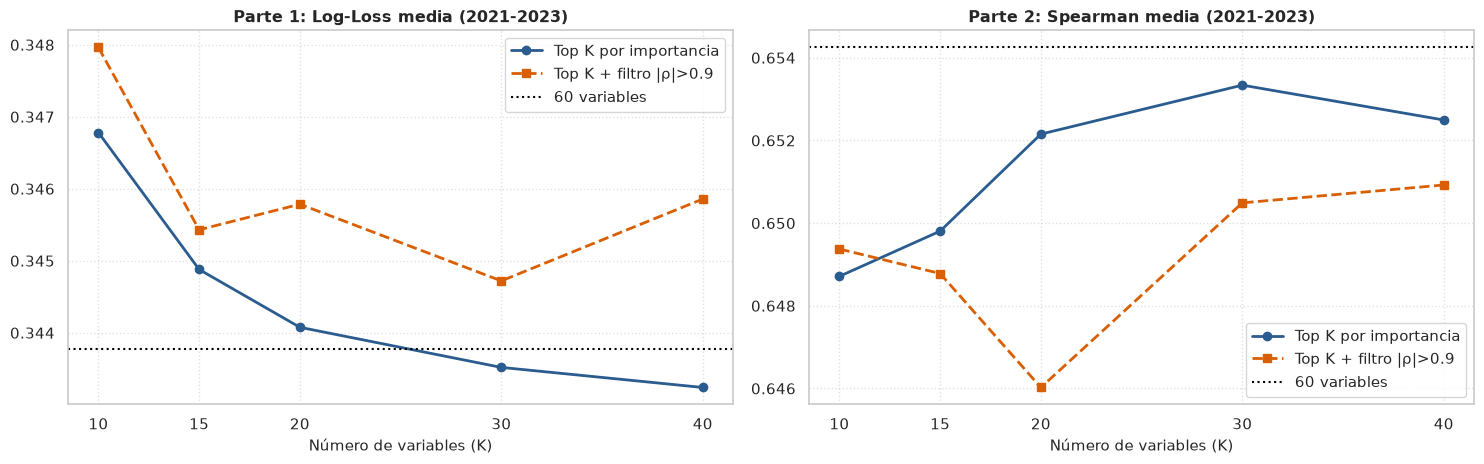

In [23]:
# ==============================================================================
# 8.3 Selección de Variables: ¿Necesitamos las 60? (Validación de Origen Móvil 2021-2023)
# ==============================================================================

# Importa expresiones regulares para leer el tamaño K de la opción elegida.
import re


# Calcula el ranking de importancia de las 60 variables SOLO con los datos de entrenamiento recibidos.
def ranking_importancia(dtr):
    """Ganancia media normalizada de los LightGBM de podio y top 10 (configuración del Bloque 6)."""
    imp = np.zeros(len(FEATURES_COLS))
    for t, (n, prm) in (("y_podio", (n_arboles_podio, best_params_podio)), ("y_top10", (n_arboles_top10, best_params_top10))):
        g = lgb.LGBMClassifier(n_estimators=n, **fijos_lgb_podio, **prm).fit(dtr[FEATURES_COLS], dtr[t]).booster_.feature_importance("gain")
        imp += g / g.sum() / 2
    return pd.Series(imp, index=FEATURES_COLS).sort_values(ascending=False)


# Selecciona K variables con uno de los dos procedimientos evaluados.
def seleccionar_variables(dtr, ranking, K, filtro_redundancia=False, umbral=0.9):
    """Procedimiento 1: las K más importantes. Procedimiento 2: igual, pero descartando las que tengan |ρ| > umbral
    con alguna ya elegida (para evitar variables casi duplicadas)."""
    if not filtro_redundancia:
        return list(ranking.index[:K])
    corr = dtr[FEATURES_COLS].corr(method="spearman").abs()
    elegidas = []
    for f in ranking.index:
        if all(corr.loc[f, e] <= umbral for e in elegidas):
            elegidas.append(f)
        if len(elegidas) == K:
            break
    return elegidas


# --- 1. Evaluación en 2021, 2022 y 2023: la selección se rehace en cada temporada SOLO con los años anteriores ---
TAMANOS_K = [10, 15, 20, 30, 40]
ll_sel, rho_sel, mae_sel, probs_sel, n_vars = {}, {}, {}, {}, {}
for v in TEMPORADAS_OM:
    dtr = df_dev.query("year < @v").reset_index(drop=True)
    dte = df_dev.query("year == @v").reset_index(drop=True)
    ranking_v = ranking_importancia(dtr)
    opciones = {"Todas (60 variables)": FEATURES_COLS}
    for k in TAMANOS_K:
        opciones[f"Top {k} por importancia"] = seleccionar_variables(dtr, ranking_v, k)
        opciones[f"Top {k} importancia + filtro |ρ|>0.9"] = seleccionar_variables(dtr, ranking_v, k, filtro_redundancia=True)
    tramos = [dtr.loc[dtr["positionOrder"] <= 3, "positionOrder"].mean(),
              dtr.loc[dtr["positionOrder"].between(4, 10), "positionOrder"].mean(),
              dtr.loc[dtr["positionOrder"] > 10, "positionOrder"].mean()]
    for nombre, feats in opciones.items():
        # Configuración final de la Parte 1 elegida en 8.2 (pesos y ajuste Σ), cambiando solo las variables.
        q = predecir_parte1(entrenar_parte1(dtr, feats=feats), dte, w_opt_podio, w_opt_top10)
        pp, pt = postproceso_parte1(dte, q["en_podio"], q["en_top10"], ajustar_suma=AJUSTAR_PODIO)
        orden = convertir_a_orden(dte, pp * tramos[0] + (pt - pp) * tramos[1] + (1 - pt) * tramos[2])
        _, rho = evaluar_orden(dte, orden, dte["positionOrder"])
        ll_sel.setdefault(nombre, []).append(logloss_por_carrera(dte, pp, pt))
        rho_sel.setdefault(nombre, []).append(rho)
        mae_sel.setdefault(nombre, []).append(pd.Series(np.abs(orden - dte["positionOrder"].to_numpy())).groupby(dte["raceId"].to_numpy()).mean())
        probs_sel[(nombre, v)] = (pp, pt)
        n_vars[nombre] = len(feats)

tabla_ll_sel = pd.DataFrame({k: pd.concat(v) for k, v in ll_sel.items()})
tabla_rho_sel = pd.DataFrame({k: pd.concat(v) for k, v in rho_sel.items()})
tabla_mae_sel = pd.DataFrame({k: pd.concat(v) for k, v in mae_sel.items()})

# --- 2. Regla de la opción más sencilla: la opción con menos variables que NO sea peor que las 60 en ninguna de las dos partes ---
REF = "Todas (60 variables)"
filas = []
for nombre in sorted(opciones, key=lambda n: (n_vars[n], "filtro" in n)):
    fila = {"Opción": nombre, "Nº vars": n_vars[nombre], "Log-Loss P1 (↓)": tabla_ll_sel[nombre].mean(),
            "Spearman P2 (↑)": tabla_rho_sel[nombre].mean(), "MAE P2 (↓)": tabla_mae_sel[nombre].mean()}
    if nombre != REF:
        d1, se1, peor1 = mejora_relevante(tabla_ll_sel[nombre], tabla_ll_sel[REF])                         # ¿las 60 mejoran la P1?
        d2, se2, peor2 = mejora_relevante(tabla_rho_sel[nombre], tabla_rho_sel[REF], menor_es_mejor=False)  # ¿las 60 mejoran la P2?
        fila.update({"60 mejora P1 (1 SE)": f"{d1:+.4f} ({se1:.4f})", "60 mejora P2 (1 SE)": f"{d2:+.4f} ({se2:.4f})",
                     "¿Equivalente a 60?": "SÍ" if not (peor1 or peor2) else "no"})
    filas.append(fila)
tabla_seleccion = pd.DataFrame(filas)
print("🧮 1. Selección de variables en validación de origen móvil (66 carreras, 2021-2023):")
print(tabla_seleccion.round(4).to_string(index=False))

equivalentes = tabla_seleccion.query("`¿Equivalente a 60?` == 'SÍ'")
OPCION_VARIABLES = equivalentes.iloc[0]["Opción"] if len(equivalentes) else REF
print(f"\n⚖️ 2. Opción más sencilla equivalente a las 60 variables: {OPCION_VARIABLES}")

# --- 3. Selección definitiva con TODO el periodo de desarrollo (2014-2023) y el procedimiento elegido ---
if OPCION_VARIABLES == REF:
    FEATURES_FINAL = list(FEATURES_COLS)
else:
    K_FINAL = int(re.search(r"Top (\d+)", OPCION_VARIABLES).group(1))
    ranking_final = ranking_importancia(df_dev)
    FEATURES_FINAL = seleccionar_variables(df_dev, ranking_final, K_FINAL, filtro_redundancia="filtro" in OPCION_VARIABLES)
auditar_sin_fuga(df_dev[FEATURES_FINAL], "Variables finales de la Parte 1")
print(f"\n✅ 3. Variables finales de la Parte 1 ({len(FEATURES_FINAL)} de {len(FEATURES_COLS)}), seleccionadas con 2014-2023:")
for j, f in enumerate(FEATURES_FINAL, 1):
    print(f"   {j:>2}. {f}")
print(f"\n   Descartadas ({len(FEATURES_COLS) - len(FEATURES_FINAL)}): {[f for f in FEATURES_COLS if f not in FEATURES_FINAL]}")

# Guarda las probabilidades de 2021-2023 de la configuración elegida para la validación de la Parte 2 (8.4).
PROBS_OM_P1 = {v: probs_sel[(OPCION_VARIABLES, v)] for v in TEMPORADAS_OM}

# --- 4. Visualización: rendimiento frente al número de variables ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for proc, estilo, color in (("por importancia", "o-", "#2b5c8f"), ("filtro", "s--", "#d95f02")):
    sub = tabla_seleccion[tabla_seleccion["Opción"].str.contains(proc, regex=False)]
    etiqueta = "Top K por importancia" if proc == "por importancia" else "Top K + filtro |ρ|>0.9"
    axes[0].plot(sub["Nº vars"], sub["Log-Loss P1 (↓)"], estilo, color=color, lw=2, label=etiqueta)
    axes[1].plot(sub["Nº vars"], sub["Spearman P2 (↑)"], estilo, color=color, lw=2, label=etiqueta)
for ax, col, titulo in ((axes[0], "Log-Loss P1 (↓)", "Parte 1: Log-Loss media (2021-2023)"), (axes[1], "Spearman P2 (↑)", "Parte 2: Spearman media (2021-2023)")):
    ax.axhline(tabla_seleccion.loc[tabla_seleccion["Opción"] == REF, col].iloc[0], color="black", ls=":", lw=1.5, label="60 variables")
    ax.set_xticks(TAMANOS_K)
    ax.set_xlabel("Número de variables (K)", fontsize=10.5)
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.legend(frameon=True, facecolor="white")
    ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

#### **💡 Conclusiones de la Selección de Variables (Sección 8.3)**

1. **Con 20 variables el modelo rinde igual que con 60:** la opción **Top 20 por importancia** obtiene una Log-Loss de **0.3441** (frente a 0.3438 con las 60) y una Spearman de **0.6522** (frente a 0.6542), con un MAE de 3.326 (frente a 3.306). Las dos diferencias quedan por debajo de un error estándar (+0.0003 con 1 SE = 0.0013, y +0.0021 con 1 SE = 0.0031).
2. **Por debajo de 20 se pierde información:** con 15 variables la Parte 2 empeora de forma relevante (+0.0044 > 1 SE = 0.0032) y con 10 empeoran las dos partes. Con 30 o 40 se obtiene lo mismo que con 20, así que no compensan.
3. **El filtro de redundancia no funciona:** con cualquier K rinde peor que las 60 en la Parte 2. Al quitar los casi duplicados (por ejemplo, `qualy_pos_clean` frente a `grid_clean`) se pierden matices que sí aportan: penalizaciones en parrilla, salidas desde el *pit lane*… Lo dejamos documentado como alternativa evaluada y descartada.
4. **Las 20 variables finales**, seleccionadas con 2014–2023, cubren todas las dimensiones del Bloque 4 salvo el circuito puro:
   - **Sábado:** `qualy_pos_clean`, `sprint_pos`, `grid_clean`, `q_gap_pct`, `q_session_reached` y la interacción `grid_x_circ_difficulty`.
   - **Coche:** `con_mean_pos_roll5`, `con_pos_ewm5`, `con_top10_roll5`, `con_podium_roll5` y `con_points_roll3`.
   - **Piloto:** `drv_pos_roll10`, `drv_pos_ewm5`, `drv_points_roll5`, `drv_qgap_roll3`, `drv_career_podium_rate` y `grid_vs_drv_roll5`.
   - **Mundial previo:** `drv_champ_pos_prev`, `con_champ_pos_prev` y `drv_share_of_con_points`.
5. **Qué se descarta y por qué tiene sentido:** las 40 variables restantes son versiones redundantes de las anteriores (ventanas de 3 y 5 carreras, puntos frente a posición en el mundial, victorias…) o señales débiles una vez conocidos la parrilla y el ritmo: fiabilidad (`con_mech_dnf_roll10`, `con_dnf_roll5`), boxes (`con_pit_ms_roll5`), historial en el circuito, altitud o edad. Esto coincide con lo visto en las importancias de los Bloques 6 y 7.
6. **Decisión:** la Parte 1 (y con ella la Parte 2) usa **20 variables en lugar de 60**: un modelo tres veces más pequeño, más fácil de explicar y de auditar, con el mismo rendimiento en validación.

### **8.4 🔁 Validación de origen móvil (2021–2023) y regla de la opción más sencilla: Parte 2**


En el Bloque 7.5 el modelo de la Parte 2 se eligió con 2023, y los cinco enfoques quedaron separados por menos de 0.006 de Spearman. Repetimos la comparación con las **66 carreras de 2021–2023** y aplicamos la misma regla de la opción más sencilla, de más sencillo a más complejo:

1. **C. Orden desde Probabilidades:** no necesita **ningún modelo nuevo**, porque reutiliza las probabilidades finales de la Parte 1 (configuración de 8.2 y variables de 8.3).
2. **A1. Regresión Ridge:** un modelo lineal adicional.
3. **A2. LightGBM Regressor:** un modelo de árboles adicional.
4. **B. LGBMRanker:** un modelo de árboles con objetivo de ranking.
5. **D. Ensamble de Rangos:** necesita los cuatro anteriores.
6. **E. Modelo ordinal (distribución completa), nuevo:** un único LightGBM aprende $P(\text{positionOrder} \le k)$ para **todos los umbrales** $k = 1..21$ a la vez (los datos se apilan una vez por umbral, con $k$ como variable y una restricción monótona en $k$). Cada umbral se ajusta para que sume $k$ en la carrera, y se ordena por la posición esperada $E[\text{pos}] = 1 + \sum_k P(\text{pos} > k)$.

**Por qué merece la pena probar E:** ordenar por la posición esperada es justo lo que maximiza la Spearman esperada, y el enfoque C la aproxima con solo tres tramos (podio, puntos, resto). E estima la distribución completa, así que en teoría distingue mejor dentro de cada tramo, sobre todo en la cola de la parrilla. Es también el más complejo, por eso va el último.

Los modelos A1, A2 y B usan los hiperparámetros elegidos en el Bloque 7; E reutiliza los del LightGBM de top 10 (Bloque 6), sin ajustar nada con 2024.


In [24]:
# ==============================================================================
# 8.4 Validación de Origen Móvil (2021-2023) y Regla de la Opción más Sencilla — Parte 2
# ==============================================================================

# --- Enfoque E (nuevo candidato): modelo ordinal de la distribución COMPLETA de la posición ---
# Un único LightGBM aprende P(positionOrder ≤ k) para todos los umbrales k = 1..21 a la vez: los datos se apilan una vez
# por umbral con k como variable, y una restricción monótona en k garantiza que la probabilidad crece con k.
UMBRALES_K = np.arange(1, 22)

def apilar_umbrales(d, feats):
    X = pd.concat([d[feats].assign(k_umbral=k) for k in UMBRALES_K], ignore_index=True)
    y = np.concatenate([(d["positionOrder"].to_numpy() <= k).astype(int) for k in UMBRALES_K])
    return X, y

def entrenar_ordinal(dtr, feats):
    X, y = apilar_umbrales(dtr, feats)
    return lgb.LGBMClassifier(n_estimators=n_arboles_top10, monotone_constraints=[0] * len(feats) + [1],
                              **fijos_lgb_podio, **best_params_top10).fit(X, y)

def posicion_esperada_ordinal(m, dte, feats):
    """E[pos] = 1 + Σ_k P(pos > k). Cada umbral se ajusta para que sume k en la carrera y se impone monotonía en k."""
    X, _ = apilar_umbrales(dte.assign(positionOrder=0), feats)
    F = m.predict_proba(X)[:, 1].reshape(len(UMBRALES_K), len(dte)).T
    for j, k in enumerate(UMBRALES_K):
        F[:, j] = ajustar_suma_carrera(dte, F[:, j], int(k))
    F = np.maximum.accumulate(F, axis=1)
    n = dte.groupby("raceId")["raceId"].transform("size").to_numpy()
    return 1 + ((1 - F) * (UMBRALES_K[None, :] < n[:, None])).sum(axis=1)

# Recorre las tres temporadas de validación con la configuración final de la Parte 1 y los modelos del Bloque 7.
rho_om, mae_om = {}, {}
for v in TEMPORADAS_OM:
    dtr, dte = df_dev.query("year < @v").reset_index(drop=True), df_dev.query("year == @v").reset_index(drop=True)
    # Probabilidades finales de la Parte 1 (configuración de 8.2 y variables de 8.3) → enfoque C.
    pp, pt = PROBS_OM_P1[v]
    tramos = [dtr.loc[dtr["positionOrder"] <= 3, "positionOrder"].mean(),
              dtr.loc[dtr["positionOrder"].between(4, 10), "positionOrder"].mean(),
              dtr.loc[dtr["positionOrder"] > 10, "positionOrder"].mean()]
    # Modelos específicos de posición con los hiperparámetros del Bloque 7.
    sc = StandardScaler().fit(dtr[FEATURES_COLS])
    rel = (dtr.groupby("raceId")["raceId"].transform("size") - dtr["positionOrder"]).clip(lower=0).astype(int)
    rk = lgb.LGBMRanker(n_estimators=n_arboles_rank, **fijos_lgb_rank, **best_params_rank)
    rk.fit(dtr[FEATURES_COLS], rel, group=tamanos_grupo(dtr["raceId"]))
    ordenes = {
        "0. Parrilla (benchmark)": convertir_a_orden(dte, dte["grid_clean"]),
        "C. Orden desde Probabilidades": convertir_a_orden(dte, pp * tramos[0] + (pt - pp) * tramos[1] + (1 - pt) * tramos[2]),
        "A1. Regresión Ridge": convertir_a_orden(dte, Ridge(alpha=alpha_opt).fit(sc.transform(dtr[FEATURES_COLS]), dtr["positionOrder"]).predict(sc.transform(dte[FEATURES_COLS]))),
        "A2. LightGBM Regressor": convertir_a_orden(dte, lgb.LGBMRegressor(n_estimators=n_arboles_reg, **fijos_lgb_reg, **best_params_reg).fit(dtr[FEATURES_COLS], dtr["positionOrder"]).predict(dte[FEATURES_COLS])),
        "B. LGBMRanker lambdarank": convertir_a_orden(dte, -rk.predict(dte[FEATURES_COLS])),
    }
    ordenes["D. Ensamble de Rangos"] = convertir_a_orden(dte, sum(ordenes[k] for k in list(ordenes)[1:]) / 4.0)
    ordenes["E. Modelo ordinal (distribución completa)"] = convertir_a_orden(
        dte, posicion_esperada_ordinal(entrenar_ordinal(dtr, FEATURES_COLS), dte, FEATURES_COLS))
    for nombre, orden in ordenes.items():
        _, rho = evaluar_orden(dte, orden, dte["positionOrder"])
        err = pd.Series(np.abs(orden - dte["positionOrder"].to_numpy())).groupby(dte["raceId"].to_numpy()).mean()
        rho_om.setdefault(nombre, []).append(rho)
        mae_om.setdefault(nombre, []).append(err)

# Tablas por carrera (66 GGPP) y resumen.
tabla_rho = pd.DataFrame({k: pd.concat(v) for k, v in rho_om.items()})
tabla_mae = pd.DataFrame({k: pd.concat(v) for k, v in mae_om.items()})
resumen_om_p2 = tabla_rho.groupby(temporada_carrera.loc[tabla_rho.index].to_numpy()).mean().T
resumen_om_p2["Spearman 2021-2023"] = tabla_rho.mean()
resumen_om_p2["MAE 2021-2023"] = tabla_mae.mean()
print("🔁 1. Parte 2 en validación de origen móvil (Spearman media por temporada, media global y MAE):")
print(resumen_om_p2.sort_values("Spearman 2021-2023", ascending=False).round(4).to_string())

# --- Regla de la opción más sencilla: C no necesita ningún modelo nuevo; después Ridge, LightGBM, ranker y ensamble ---
orden_sencillez_p2 = ["C. Orden desde Probabilidades", "A1. Regresión Ridge", "A2. LightGBM Regressor", "B. LGBMRanker lambdarank", "D. Ensamble de Rangos",
                      "E. Modelo ordinal (distribución completa)"]
elegido_p2 = orden_sencillez_p2[0]
print("\n⚖️ 2. Regla de la opción más sencilla (Spearman pareada en 66 carreras; positivo = mejora):")
for candidato in orden_sencillez_p2[1:]:
    dif, se, adoptar = mejora_relevante(tabla_rho[elegido_p2], tabla_rho[candidato], menor_es_mejor=False)
    print(f"   • {candidato:<42} vs {elegido_p2:<30}: {dif:+.4f} (1 SE = {se:.4f}) → {'ADOPTAR' if adoptar else 'no compensa'}")
    elegido_p2 = candidato if adoptar else elegido_p2
dif, se, _ = mejora_relevante(tabla_rho["0. Parrilla (benchmark)"], tabla_rho[elegido_p2], menor_es_mejor=False)
print(f"\n   Ventaja del elegido sobre la parrilla: {dif:+.4f} de Spearman (1 SE = {se:.4f}, {dif / se:.1f} errores estándar)")

# Sustituye la elección del Bloque 7.5 (solo 2023) por la de la validación de origen móvil (2021-2023).
MODELO_GANADOR_P2 = next((n for n in tabla_premio_parte2["Sistema / Modelo"] if n.startswith(elegido_p2[:2])), elegido_p2)
print(f"\n✅ Modelo final de la Parte 2: {MODELO_GANADOR_P2}")

🔁 1. Parte 2 en validación de origen móvil (Spearman media por temporada, media global y MAE):
                                            2021   2022   2023  Spearman 2021-2023  MAE 2021-2023
A2. LightGBM Regressor                    0.6921 0.6116 0.6606              0.6548         3.3333
D. Ensamble de Rangos                     0.6971 0.6033 0.6576              0.6527         3.3424
C. Orden desde Probabilidades             0.6949 0.5983 0.6632              0.6522         3.3258
E. Modelo ordinal (distribución completa) 0.6869 0.6095 0.6559              0.6508         3.3515
B. LGBMRanker lambdarank                  0.6819 0.6131 0.6470              0.6473         3.4015
A1. Regresión Ridge                       0.6957 0.5788 0.6604              0.6450         3.3712
0. Parrilla (benchmark)                   0.6485 0.5260 0.5977              0.5907         3.6197

⚖️ 2. Regla de la opción más sencilla (Spearman pareada en 66 carreras; positivo = mejora):
   • A1. Regresión Ridge    

#### **💡 Conclusiones de la Validación de Origen Móvil — Parte 2 (Sección 8.4)**

1. **La mejora sobre la parrilla es robusta:** en las 66 carreras, el enfoque elegido supera a la parrilla en **+0.061 de Spearman** (0.652 frente a 0.591), **4.8 errores estándar**, y en las tres temporadas por separado.
2. **Ningún modelo específico de posición mejora de forma relevante el orden derivado de las probabilidades:**
   - LightGBM Regressor: +0.0026 (1 SE = 0.0041). Es el "ganador" de 2023, pero la diferencia es ruido.
   - Ensamble de rangos: +0.0005. LGBMRanker: −0.0048. Ridge: −0.0072 (sufre especialmente en 2022, con el cambio de reglamento técnico).
   - **Modelo ordinal: −0.0014** (1 SE = 0.0038). Modelar la distribución completa de la posición no ordena mejor que los tres tramos del enfoque C, y su MAE es peor (3.352). Con ~4,000 participaciones, apilar 21 umbrales no añade información nueva: los umbrales vecinos están casi perfectamente correlados y la incertidumbre del domingo (abandonos, lluvia) domina sobre los matices de la cola.
3. **El desempate oficial también favorece al enfoque más sencillo:** el orden desde probabilidades tiene **el mejor MAE** de todos (**3.326** frente a 3.333 de LightGBM, 3.352 del modelo ordinal y 3.620 de la parrilla).
4. **Decisión final: la Parte 2 se resuelve con el orden derivado de las probabilidades de la Parte 1.** Todo el sistema queda en **un único modelo** (el ensamble de la Parte 1 con 20 variables) que responde a las dos preguntas del jefe de estrategia de forma coherente: si un piloto tiene más opciones de podio y de puntos, lo esperamos por delante. Ridge, LightGBM Regressor, el ranker, el ensamble de rangos y el modelo ordinal quedan documentados como alternativas evaluadas y se muestran en 8.7 solo por transparencia.

### **8.5 🔒 Reentrenamiento final con Train + Validación (2014–2023) y configuración congelada**


Con todas las decisiones tomadas, reentrenamos cada componente sobre **2014–2023**. Así el modelo final aprovecha la temporada 2023, la más parecida a 2024 (mismo reglamento técnico desde 2022).

Reglas del reentrenamiento:
- **Se reutiliza exactamente lo elegido antes:** `C` de las logísticas, hiperparámetros y número de árboles de cada LightGBM, pesos y escala (logit) del ensamble de la Parte 1, `alpha` de Ridge, configuración del ranker y decisión de ajuste de sumas.
- **Solo se reajustan los parámetros "de datos":** el escalador z-score, los benchmarks de parrilla y las posiciones medias por tramo del enfoque C.
- El número de árboles se mantiene igual aunque los datos crecen un 12%, lo que es una opción conservadora.
- Se comprueba de nuevo que **ninguna fila de 2024** entra en el entrenamiento y que no hay columnas prohibidas.


In [25]:
# ==============================================================================
# 8.5 Reentrenamiento Final con Train + Validación (2014-2023) y Hiperparámetros Congelados
# ==============================================================================

# Une Train (2014-2022) y Validación (2023) conservando el orden cronológico (cada carrera sigue siendo contigua).
df_trval = pd.concat([df_train, df_val], ignore_index=True)
X_trval = df_trval[FEATURES_COLS].copy()
# Matriz de test con las MISMAS columnas (FEATURES_COLS puede haber cambiado en 8.2).
X_test = df_test[FEATURES_COLS].copy()
y_trval_podio, y_trval_top10, y_trval_pos = df_trval["y_podio"], df_trval["y_top10"], df_trval["y_pos"]

# Comprueba que ninguna fila de 2024 entra en el entrenamiento final y que no hay columnas prohibidas.
assert df_trval["year"].max() == YEAR_VAL and df_trval["year"].min() == YEAR_TRAIN_MIN
assert len(tamanos_grupo(df_trval["raceId"])) == df_trval["raceId"].nunique()
auditar_sin_fuga(X_trval, "X_trval (2014-2023)")

# Reajusta el escalador z-score sobre 2014-2023 y transforma Train+Val y Test.
scaler_final = StandardScaler().fit(X_trval)
X_trval_sc = pd.DataFrame(scaler_final.transform(X_trval), columns=FEATURES_COLS)
X_test_sc = pd.DataFrame(scaler_final.transform(X_test), columns=FEATURES_COLS)

# --- Parte 1: Benchmark de parrilla, Regresión Logística y LightGBM (podio y top 10) ---
scaler_grid_final = StandardScaler().fit(X_trval[["grid_clean"]])
bench_podio_final = LogisticRegression(C=1.0, random_state=SEED).fit(scaler_grid_final.transform(X_trval[["grid_clean"]]), y_trval_podio)
bench_top10_final = LogisticRegression(C=1.0, random_state=SEED).fit(scaler_grid_final.transform(X_trval[["grid_clean"]]), y_trval_top10)

# Los modelos de la Parte 1 usan solo las variables seleccionadas en 8.3 (con su propio escalador).
scaler_p1_final = StandardScaler().fit(df_trval[FEATURES_FINAL])
X_trval_p1_sc = scaler_p1_final.transform(df_trval[FEATURES_FINAL])
X_test_p1, X_test_p1_sc = X_test[FEATURES_FINAL], scaler_p1_final.transform(X_test[FEATURES_FINAL])

lr_podio_final = LogisticRegression(C=c_opt_podio, max_iter=1000, random_state=SEED).fit(X_trval_p1_sc, y_trval_podio)
lr_top10_final = LogisticRegression(C=c_opt_top10, max_iter=1000, random_state=SEED).fit(X_trval_p1_sc, y_trval_top10)

lgb_podio_final = lgb.LGBMClassifier(n_estimators=n_arboles_podio, **fijos_lgb_podio, **best_params_podio).fit(df_trval[FEATURES_FINAL], y_trval_podio)
lgb_top10_final = lgb.LGBMClassifier(n_estimators=n_arboles_top10, **fijos_lgb_podio, **best_params_top10).fit(df_trval[FEATURES_FINAL], y_trval_top10)

# --- Parte 2 (alternativas mostradas por transparencia, con las 60 variables del Bloque 7) ---
ridge_pos_final = Ridge(alpha=alpha_opt).fit(X_trval_sc, y_trval_pos)
lgb_reg_final = lgb.LGBMRegressor(n_estimators=n_arboles_reg, **fijos_lgb_reg, **best_params_reg).fit(X_trval, y_trval_pos)

rel_trval = (df_trval.groupby("raceId")["raceId"].transform("size") - df_trval["positionOrder"]).clip(lower=0).astype(int)
lgb_rank_final = lgb.LGBMRanker(n_estimators=n_arboles_rank, **fijos_lgb_rank, **best_params_rank)
lgb_rank_final.fit(X_trval, rel_trval, group=tamanos_grupo(df_trval["raceId"]))
ordinal_final = entrenar_ordinal(df_trval, FEATURES_COLS)

# Recalcula las posiciones medias por tramo con 2014-2023 para el enfoque C (orden desde probabilidades).
pos_media_podio = df_trval.loc[df_trval["positionOrder"] <= 3, "positionOrder"].mean()
pos_media_puntos = df_trval.loc[df_trval["positionOrder"].between(4, 10), "positionOrder"].mean()
pos_media_fuera = df_trval.loc[df_trval["positionOrder"] > 10, "positionOrder"].mean()

# Muestra la configuración congelada que se aplicará a la temporada 2024.
tabla_config_final = pd.DataFrame([
    {"Componente": "Parte 1 · Podio", "Modelo": f"Ensamble LGB + LR (escala {ESCALA_ENSAMBLE})", "Configuración": f"LR C={c_opt_podio} | LGB {n_arboles_podio} árboles | peso LGB = {w_opt_podio:.2f}"},
    {"Componente": "Parte 1 · Top 10", "Modelo": f"Ensamble LGB + LR (escala {ESCALA_ENSAMBLE})", "Configuración": f"LR C={c_opt_top10} | LGB {n_arboles_top10} árboles | peso LGB = {w_opt_top10:.2f}"},
    {"Componente": "Parte 1 · Variables", "Modelo": OPCION_VARIABLES, "Configuración": f"{len(FEATURES_FINAL)} de {len(FEATURES_COLS)} variables (seleccionadas con 2014-2023)"},
    {"Componente": "Parte 1 · Ajuste Σ", "Modelo": "Desplazamiento logit por carrera", "Configuración": f"podio: {AJUSTAR_PODIO} | top 10: {AJUSTAR_TOP10}"},
    {"Componente": "Parte 2 · Posición", "Modelo": MODELO_GANADOR_P2, "Configuración": f"Ridge α={alpha_opt} | LGB Reg {n_arboles_reg} | Ranker {n_arboles_rank} | tramos {pos_media_podio:.2f}/{pos_media_puntos:.2f}/{pos_media_fuera:.2f}"},
])
print(f"\n🔒 Modelos finales reentrenados con {len(df_trval):,} filas ({df_trval['raceId'].nunique()} GGPP, {YEAR_TRAIN_MIN}-{YEAR_VAL}). Configuración congelada:")
print(tabla_config_final.to_string(index=False))

✅ Auditoría Anti-Fuga superada en 'X_trval (2014-2023)': 60 columnas verificadas (0 variables post-carrera del GP t).



🔒 Modelos finales reentrenados con 4,147 filas (204 GGPP, 2014-2023). Configuración congelada:
         Componente                                  Modelo                                                    Configuración
    Parte 1 · Podio        Ensamble LGB + LR (escala logit)                    LR C=0.05 | LGB 164 árboles | peso LGB = 0.50
   Parte 1 · Top 10        Ensamble LGB + LR (escala logit)                    LR C=0.01 | LGB 300 árboles | peso LGB = 0.50
Parte 1 · Variables                  Top 20 por importancia                 20 de 60 variables (seleccionadas con 2014-2023)
 Parte 1 · Ajuste Σ        Desplazamiento logit por carrera                                       podio: True | top 10: True
 Parte 2 · Posición C. Orden desde Probabilidades (Parte 1) Ridge α=1000.0 | LGB Reg 81 | Ranker 59 | tramos 2.00/7.00/15.70


#### **💡 Conclusiones del Reentrenamiento (Sección 8.5)**

1. **Modelos finales entrenados con 4,147 participaciones de 204 Grandes Premios (2014–2023)**, superando de nuevo la auditoría anti-fuga.
2. **Configuración congelada:**
   - **Parte 1:** podio (LR `C=0.05` + LightGBM de 164 árboles) y top 10 (LR `C=0.01` + LightGBM de 300 árboles), ambos con las **20 variables de la Sección 8.3** y mezclados **al 50% en escala logit**, con ajuste de sumas por carrera y corrección de coherencia.
   - **Parte 2:** **orden derivado de las probabilidades de la Parte 1** (tramos 2.00 / 7.00 / 15.70), sin ningún modelo adicional. Ridge, LightGBM Regressor, LGBMRanker, su ensamble y el modelo ordinal (con las 60 variables) se reentrenan solo para mostrarlos por transparencia en 8.7.
3. **A partir de aquí no se toca nada:** lo que sigue es aplicar estos modelos a 2024 y medir.

### **8.6 🏆 Parte 1 en Test 2024: probabilidades de podio y top 10**

Aplicamos la cadena completa de la Parte 1 a las 479 participaciones de 2024:
1. Ensamble LightGBM + Regresión Logística al 50% en escala logit (Sección 8.2) con las 20 variables seleccionadas (Sección 8.3).
2. Ajuste de sumas por carrera (Σ = 3 y Σ = 10).
3. Corrección de coherencia $p_\text{podio} \le p_\text{top10}$ y acotación en $[10^{-4},\ 1 - 10^{-4}]$.

Lo comparamos con el **benchmark de solo parrilla**, reentrenado también con 2014–2023, usando el Score Oficial (media de las Log-Loss de podio y top 10).

🏆 Score Oficial Parte 1 — TEST 2024 (24 GGPP, 479 pilotos):
                                  Sistema / Modelo  Log-Loss Podio  Log-Loss Top 10  SCORE OFICIAL (Media Log-Loss ↓)  ROC-AUC Medio (↑) Coherencia (p_pod ≤ p_t10)
              1. Benchmark Oficial (Solo Parrilla)          0.2416           0.4384                            0.3400             0.9047                    100% OK
2. Modelo Final (Ensamble + Ajuste Σ + Coherencia)          0.2173           0.3963                            0.3068             0.9264                    100% OK

✨ Mejora sobre el Benchmark de Parrilla en Test: -0.0332 de Log-Loss media (9.76%).
   (En Validación 2023 la mejora fue del 13.21%.)

Σ Sumas por carrera en 2024 → p_podio: media 3.000 | p_top10: media 10.000
   Esperados / Reales → podio: 1.000 | top 10: 1.000


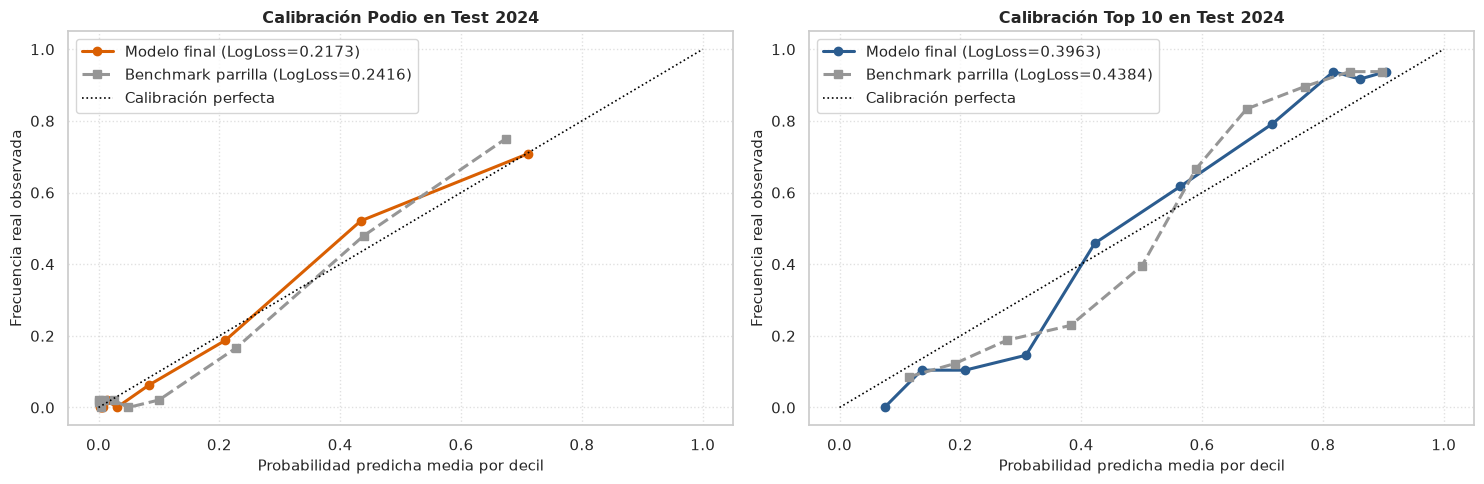

In [26]:
# ==============================================================================
# 8.6 Parte 1 en Test 2024: Probabilidades de Podio y Top 10
# ==============================================================================

# Predice las probabilidades del benchmark de parrilla en 2024.
X_test_grid_final = scaler_grid_final.transform(X_test[["grid_clean"]])
p_test_podio_bench, p_test_top10_bench = imponer_coherencia_probabilidades(
    bench_podio_final.predict_proba(X_test_grid_final)[:, 1], bench_top10_final.predict_proba(X_test_grid_final)[:, 1])

# Combina LightGBM y Regresión Logística (variables de 8.3) con los pesos y la escala elegidos en 8.2.
p_test_podio_ens = mezclar(lgb_podio_final.predict_proba(X_test_p1)[:, 1], lr_podio_final.predict_proba(X_test_p1_sc)[:, 1], w_opt_podio, ESCALA_ENSAMBLE)
p_test_top10_ens = mezclar(lgb_top10_final.predict_proba(X_test_p1)[:, 1], lr_top10_final.predict_proba(X_test_p1_sc)[:, 1], w_opt_top10, ESCALA_ENSAMBLE)

# Aplica (si se decidió en 8.1) el ajuste de sumas por carrera y, al final, la coherencia obligatoria.
if AJUSTAR_PODIO:
    p_test_podio_ens = ajustar_suma_carrera(df_test, p_test_podio_ens, 3)
if AJUSTAR_TOP10:
    p_test_top10_ens = ajustar_suma_carrera(df_test, p_test_top10_ens, 10)
p_test_podio_final, p_test_top10_final = imponer_coherencia_probabilidades(p_test_podio_ens, p_test_top10_ens)

# Evalúa ambos sistemas sobre 2024 con el Score Oficial de la Parte 1.
tabla_test_parte1 = pd.DataFrame([
    calcular_metricas_parte1("1. Benchmark Oficial (Solo Parrilla)", p_test_podio_bench, p_test_top10_bench, y_test_podio, y_test_top10),
    calcular_metricas_parte1("2. Modelo Final (Ensamble + Ajuste Σ + Coherencia)", p_test_podio_final, p_test_top10_final, y_test_podio, y_test_top10),
]).round(4)
ll_bench_test = tabla_test_parte1.loc[0, "SCORE OFICIAL (Media Log-Loss ↓)"]
ll_final_test = tabla_test_parte1.loc[1, "SCORE OFICIAL (Media Log-Loss ↓)"]

print("🏆 Score Oficial Parte 1 — TEST 2024 (24 GGPP, 479 pilotos):")
print(tabla_test_parte1.to_string(index=False))
print(f"\n✨ Mejora sobre el Benchmark de Parrilla en Test: -{ll_bench_test - ll_final_test:.4f} de Log-Loss media ({100 * (ll_bench_test - ll_final_test) / ll_bench_test:.2f}%).")
print(f"   (En Validación 2023 la mejora fue del {mejora_pct_p1:.2f}%.)")

# Comprueba las sumas por carrera en 2024 y la calibración agregada.
print(f"\nΣ Sumas por carrera en 2024 → p_podio: media {sumas_por_carrera(df_test, p_test_podio_final).mean():.3f} | p_top10: media {sumas_por_carrera(df_test, p_test_top10_final).mean():.3f}")
print(f"   Esperados / Reales → podio: {p_test_podio_final.sum() / y_test_podio.sum():.3f} | top 10: {p_test_top10_final.sum() / y_test_top10.sum():.3f}")

# --- Visualización: curvas de calibración por deciles en Test 2024 (podio y top 10) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, y_real, p_mod, p_ben, color, titulo in [
    (axes[0], y_test_podio, p_test_podio_final, p_test_podio_bench, "#d95f02", "Calibración Podio en Test 2024"),
    (axes[1], y_test_top10, p_test_top10_final, p_test_top10_bench, "#2b5c8f", "Calibración Top 10 en Test 2024"),
]:
    for p_sis, estilo, etiqueta in [(p_mod, "o-", "Modelo final"), (p_ben, "s--", "Benchmark parrilla")]:
        dcal = pd.DataFrame({"y": np.asarray(y_real), "p": p_sis})
        dcal["decil"] = pd.qcut(dcal["p"], 10, labels=False, duplicates="drop")
        cal = dcal.groupby("decil").agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(cal["p"], cal["y"], estilo, color=color if etiqueta == "Modelo final" else "#969696", lw=2.2, markersize=6,
                label=f"{etiqueta} (LogLoss={log_loss(y_real, p_sis):.4f})")
    ax.plot([0, 1], [0, 1], ":", color="black", lw=1.2, label="Calibración perfecta")
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Probabilidad predicha media por decil", fontsize=10.5)
    ax.set_ylabel("Frecuencia real observada", fontsize=10.5)
    ax.legend(loc="upper left", frameon=True, facecolor="white")
    ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

#### **💡 Conclusiones de la Parte 1 en Test (Sección 8.6)**

1. **Batimos al benchmark de parrilla en 2024:** el Score Oficial baja de **0.3400** a **0.3068** (**−9.8%**). Mejoran los dos componentes: podio **0.2416 → 0.2173** y top 10 **0.4384 → 0.3963**, y el ROC-AUC medio sube de 0.905 a 0.926.
2. **La mejora es algo menor que en validación (13.2% en 2023)**, pero 2024 era una temporada más "fácil" para la parrilla: su Log-Loss baja de 0.3988 en 2023 a 0.3400 en 2024, así que había menos margen. La ventaja del modelo se mantiene fuera de muestra.
3. **Las decisiones se tomaron sin mirar 2024 y se respetan:** la reducción a 20 variables (8.3), la escala logit (8.2) y el descarte del ritmo de carrera y del modelo ordinal se decidieron con 2021–2023. Cualquier diferencia de milésimas que se observe en 2024 frente a otras configuraciones es del mismo orden que la variabilidad entre temporadas, y cambiar la elección a la vista del Test sería justo lo que las reglas prohíben.
4. **Coherencia y sumas garantizadas:** el 100% de las filas cumple $p_\text{podio} \le p_\text{top10}$, las sumas por carrera son exactamente 3.000 y 10.000, y el ratio Esperados/Reales es 1.000 en ambos targets.
5. **Calibración:** la curva de podio sigue muy de cerca la diagonal. En top 10 el modelo sigue siendo algo prudente en los extremos, pero la recalibración evaluada en 8.2 no mejoraba de forma consistente, así que no se aplica.

### **8.7 🏁 Parte 2 en Test 2024: orden final de carrera**

Generamos el orden de cada enfoque con los modelos reentrenados. La **`posicion_pred` oficial** es el orden $1..N$ por carrera del **enfoque seleccionado en la validación de origen móvil** (variable `MODELO_GANADOR_P2`, fijada en la Sección 8.4: el orden derivado de las probabilidades de la Parte 1). El código lo toma automáticamente de esa variable, de modo que la elección nunca depende de lo que se vea en 2024.

El resto de enfoques se muestran **solo por transparencia**, no para cambiar la elección a la vista del Test.

🏁 Score Oficial Parte 2 — TEST 2024 (24 GGPP):
                            Sistema / Modelo  Spearman medio (↑)  Spearman mediana  Spearman mínimo  MAE posición (↓)
    0. Benchmark Oficial (Orden de Parrilla)              0.7298            0.7917           0.3865            2.8935
                         A1. Regresión Ridge              0.7556            0.7962           0.3825            2.8100
                      A2. LightGBM Regressor              0.7530            0.7985           0.3544            2.8434
                    B. LGBMRanker lambdarank              0.7475            0.7955           0.3895            2.8559
C. Orden desde Probabilidades (SELECCIONADO)              0.7508            0.8008           0.3807            2.8184
                       D. Ensamble de Rangos              0.7516            0.8105           0.3789            2.8225
   E. Modelo ordinal (distribución completa)              0.7489            0.7887           0.3684            2.8977

🥇 Modelo

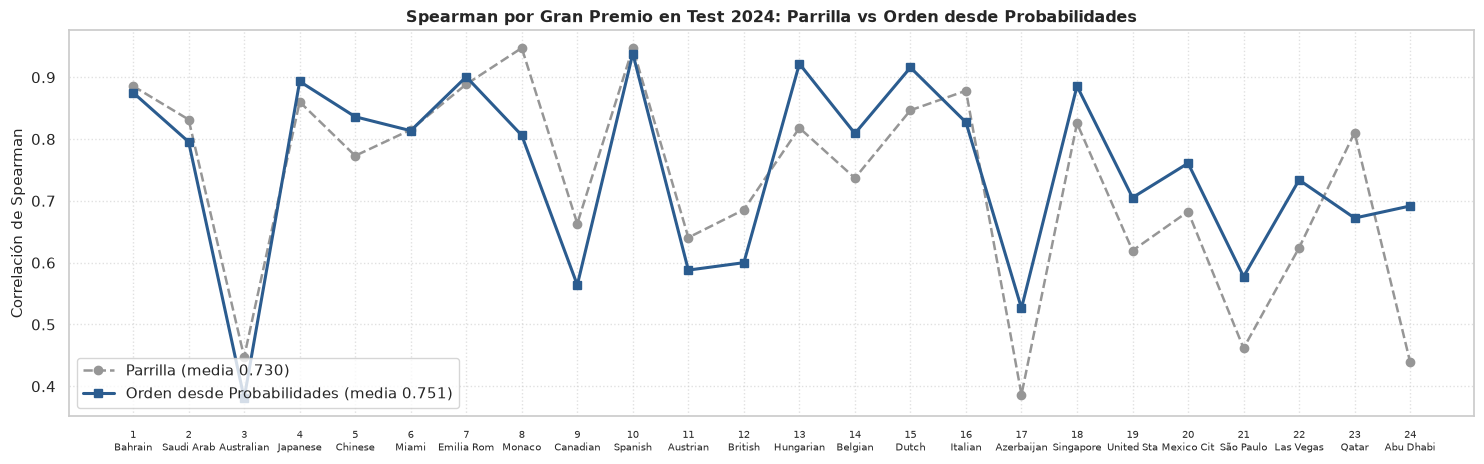

In [27]:
# ==============================================================================
# 8.7 Parte 2 en Test 2024: Orden Final de Carrera
# ==============================================================================

# Calcula el orden 1..N de cada enfoque en 2024 con los modelos reentrenados.
orden_test_bench = convertir_a_orden(df_test, df_test["grid_clean"])
orden_test_ridge = convertir_a_orden(df_test, ridge_pos_final.predict(X_test_sc))
orden_test_reg = convertir_a_orden(df_test, lgb_reg_final.predict(X_test))
orden_test_rank = convertir_a_orden(df_test, -lgb_rank_final.predict(X_test))
orden_test_prob = convertir_a_orden(df_test, posicion_esperada(p_test_podio_final, p_test_top10_final))

# Calcula también el ensamble de rangos con pesos iguales (enfoque D).
orden_test_ens = convertir_a_orden(df_test, (orden_test_ridge + orden_test_reg + orden_test_rank + orden_test_prob) / 4.0)
# Modelo ordinal (enfoque E).
orden_test_ord = convertir_a_orden(df_test, posicion_esperada_ordinal(ordinal_final, df_test, FEATURES_COLS))

# La 'posicion_pred' oficial es el orden del enfoque SELECCIONADO EN LA VALIDACIÓN 2021-2023 (Sección 8.4), sin mirar 2024.
ordenes_test = {"A1": orden_test_ridge, "A2": orden_test_reg, "B.": orden_test_rank, "C.": orden_test_prob, "D.": orden_test_ens, "E.": orden_test_ord}
CLAVE_GANADOR_P2 = MODELO_GANADOR_P2[:2]
NOMBRE_GANADOR_P2 = MODELO_GANADOR_P2.split(". ", 1)[1].split(" (")[0]
orden_test_final = ordenes_test[CLAVE_GANADOR_P2]

# Evalúa todos los enfoques en 2024 (el ganador ya estaba elegido; el resto se muestra por transparencia).
resultados_test_p2 = {}  # clave: prefijo del enfoque ('0.', 'A1', 'A2', 'B.', 'C.', 'D.', 'E.')
filas_test_p2 = []
for nombre, orden in [
    ("0. Benchmark Oficial (Orden de Parrilla)", orden_test_bench),
    ("A1. Regresión Ridge", orden_test_ridge),
    ("A2. LightGBM Regressor", orden_test_reg),
    ("B. LGBMRanker lambdarank", orden_test_rank),
    ("C. Orden desde Probabilidades", orden_test_prob),
    ("D. Ensamble de Rangos", orden_test_ens),
    ("E. Modelo ordinal (distribución completa)", orden_test_ord),
]:
    met, rho = evaluar_orden(df_test, orden, y_test_pos)
    resultados_test_p2[nombre[:2]] = rho
    etiqueta = nombre + (" (SELECCIONADO)" if nombre[:2] == CLAVE_GANADOR_P2 else "")
    filas_test_p2.append({"Sistema / Modelo": etiqueta, **met})
tabla_test_parte2 = pd.DataFrame(filas_test_p2).round(4)

rho_test_bench = resultados_test_p2["0."]
rho_test_final = resultados_test_p2[CLAVE_GANADOR_P2]

print("🏁 Score Oficial Parte 2 — TEST 2024 (24 GGPP):")
print(tabla_test_parte2.to_string(index=False))
print(f"\n🥇 Modelo seleccionado ({NOMBRE_GANADOR_P2}): Spearman media {rho_test_final.mean():.4f} frente a {rho_test_bench.mean():.4f} de la parrilla "
      f"(+{rho_test_final.mean() - rho_test_bench.mean():.4f}); supera a la parrilla en {int((rho_test_final > rho_test_bench).sum())} de {len(rho_test_final)} carreras.")

# --- Visualización: Spearman por ronda de 2024, parrilla frente al modelo seleccionado ---
rho_rondas = pd.DataFrame({"Parrilla": rho_test_bench, "Modelo": rho_test_final}).join(dfs["races"].set_index("raceId")[["round", "name"]]).sort_values("round")
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(rho_rondas["round"], rho_rondas["Parrilla"], "o--", color="#969696", lw=1.8, label=f"Parrilla (media {rho_test_bench.mean():.3f})")
ax.plot(rho_rondas["round"], rho_rondas["Modelo"], "s-", color="#2b5c8f", lw=2.2, label=f"{NOMBRE_GANADOR_P2} (media {rho_test_final.mean():.3f})")
ax.set_xticks(rho_rondas["round"])
ax.set_xticklabels([f"{r}\n{n.replace(' Grand Prix', '')[:10]}" for r, n in zip(rho_rondas["round"], rho_rondas["name"])], fontsize=7.5)
ax.set_ylabel("Correlación de Spearman", fontsize=10.5)
ax.set_title(f"Spearman por Gran Premio en Test 2024: Parrilla vs {NOMBRE_GANADOR_P2}", fontsize=11.5, fontweight="bold")
ax.legend(loc="lower left", frameon=True, facecolor="white")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

#### **💡 Conclusiones de la Parte 2 en Test (Sección 8.7)**

1. **El enfoque seleccionado (orden desde probabilidades) bate a la parrilla en 2024:** Spearman media de **0.751 frente a 0.730** (+0.021) y MAE de **2.82 frente a 2.89** posiciones. Supera a la parrilla en **13 de las 24 carreras**.
2. **La ventaja es menor que en 2021–2023 (+0.061).** En 2024 la parrilla explicó mucho más (0.730 frente a 0.591 de media en 2021–2023), lo que deja menos margen.
3. **Los seis enfoques baten a la parrilla y quedan a menos de 0.01 entre sí** (de 0.748 a 0.756; en MAE, de 2.81 a 2.90). Es lo que anticipaba la Sección 8.4: ni los modelos específicos de posición ni el modelo ordinal aportan nada relevante sobre el orden derivado de las probabilidades, así que el enfoque más sencillo era una elección razonable.
4. **Dónde gana y dónde pierde:** el modelo aporta más cuando la parrilla está "desordenada" respecto al ritmo real (penalizaciones en parrilla, clasificaciones en mojado). Por ejemplo, en Abu Dabi Leclerc salía 19º por penalización y terminó 3º. Pierde frente a la parrilla cuando la salida fue casi exactamente la llegada (Mónaco) o con condiciones cambiantes (Canadá).

### **8.8 🔍 Análisis de errores: abandonos, cambios de nivel de los equipos y carreras caóticas**


Una vez evaluado el modelo, analizamos **dónde y por qué falla** para entender sus límites. El reto propone tres focos:
1. **Abandonos (DNF):** `positionOrder` manda al final a quien abandona, aunque fuera 2º a falta de una vuelta. ¿Cuánto nos cuestan en Log-Loss y en Spearman?
2. **Equipos que cambian de nivel:** comparamos, por escudería y mitad de temporada, la posición predicha con la real. Un sesgo sistemático indica que el modelo no capta bien el nivel del coche.
3. **Lluvia e incidentes (no están en los datos):** revisamos las carreras con peor Spearman y las predicciones más "caras" para la Log-Loss.


🔧 1. Impacto de los abandonos (DNF) en Test 2024:
   • Abandonos: 54 de 479 participaciones (11.3%)
                    filas  ll_podio  ll_top10  mae_pos  error_medio
Terminó la carrera    425    0.2300    0.3640   2.3480       0.7950
Abandonó (DNF)         54    0.1140    0.6490   6.5190      -6.2590
   • Spearman media del modelo seleccionado con todos los pilotos: 0.7508 | solo entre los que terminan: 0.8516

🏎️ 2. Sesgo medio del orden predicho por escudería (predicho − real; positivo = el modelo los infravalora):
mitad           R1-R12  R13-R24  Pos. real media
equipo                                          
McLaren        -0.5000  -1.0400           4.7100
Ferrari        -1.2900  -0.1200           5.1500
Red Bull       -1.8800  -1.6700           6.6200
Mercedes       -1.1200  -0.9200           6.8500
Aston Martin   -0.9200  -1.2500          11.7700
Haas F1 Team    2.5400   0.2900          12.4000
RB F1 Team     -0.7500  -0.6700          13.2900
Alpine F1 Team  0.6700   1.1200   

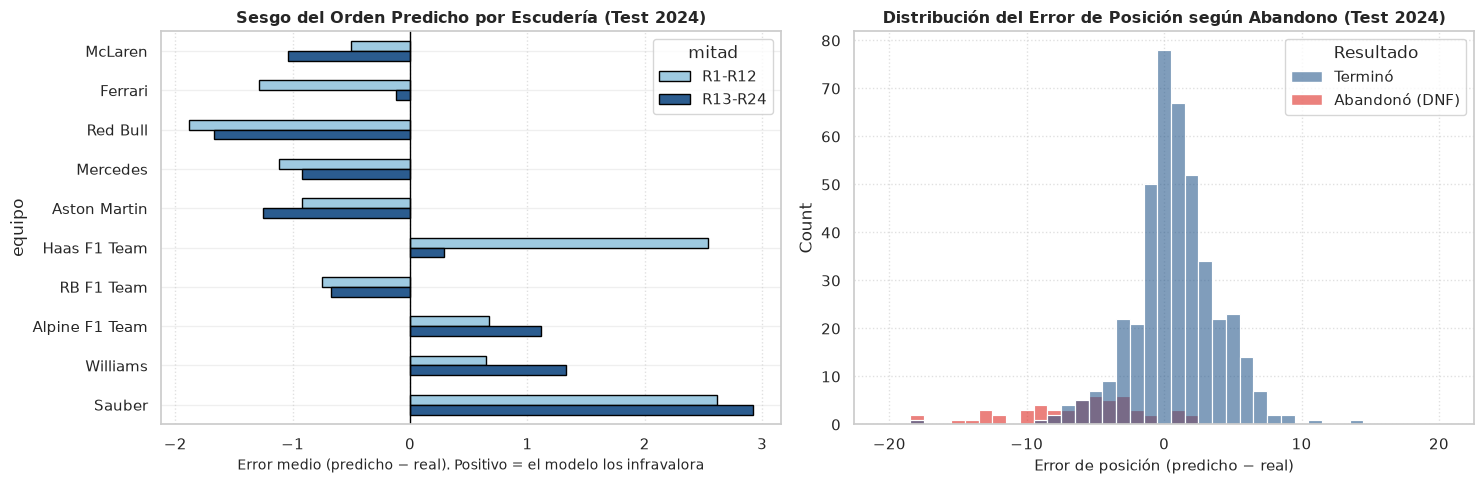

In [28]:
# ==============================================================================
# 8.8 Análisis de Errores: Abandonos, Cambios de Nivel de los Equipos y Carreras Caóticas
# ==============================================================================

# Construye la tabla de análisis de 2024 con nombres legibles, predicciones y resultado real.
nombres_pilotos = dfs["drivers"].set_index("driverId")["surname"]
nombres_equipos = dfs["constructors"].set_index("constructorId")["name"]
df_err = df_test[["resultId", "raceId", "round", "driverId", "constructorId", "grid_clean", "positionOrder", "statusId", "status", "y_podio", "y_top10"]].copy()
df_err["piloto"] = df_err["driverId"].map(nombres_pilotos)
df_err["equipo"] = df_err["constructorId"].map(nombres_equipos)
df_err["gp"] = df_err["raceId"].map(dfs["races"].set_index("raceId")["name"]).str.replace(" Grand Prix", "")
df_err["p_podio"], df_err["p_top10"], df_err["orden_pred"] = p_test_podio_final, p_test_top10_final, orden_test_final
df_err["es_dnf"] = (~((df_err["statusId"] == 1) | df_err["status"].str.startswith("+"))).astype(int)
df_err["error_pos"] = df_err["orden_pred"] - df_err["positionOrder"]

# Log-Loss por fila (contribución individual de cada piloto a la métrica oficial).
ll_fila = lambda y, p: -(y * np.log(p) + (1 - y) * np.log(1 - p))
df_err["ll_podio"] = ll_fila(df_err["y_podio"], df_err["p_podio"])
df_err["ll_top10"] = ll_fila(df_err["y_top10"], df_err["p_top10"])

# --- 1. Abandonos (DNF) ---
print("🔧 1. Impacto de los abandonos (DNF) en Test 2024:")
print(f"   • Abandonos: {df_err['es_dnf'].sum()} de {len(df_err)} participaciones ({df_err['es_dnf'].mean() * 100:.1f}%)")
resumen_dnf = df_err.groupby("es_dnf").agg(
    filas=("resultId", "count"), ll_podio=("ll_podio", "mean"), ll_top10=("ll_top10", "mean"),
    mae_pos=("error_pos", lambda e: e.abs().mean()), error_medio=("error_pos", "mean"))
resumen_dnf.index = ["Terminó la carrera", "Abandonó (DNF)"]
print(resumen_dnf.round(3).to_string())
# Recalcula la Spearman del modelo seleccionado considerando solo a los pilotos que terminaron (orden relativo entre ellos).
rho_sin_dnf = np.mean([spearmanr(d["orden_pred"], d["positionOrder"]).correlation for _, d in df_err.query("es_dnf == 0").groupby("raceId")])
print(f"   • Spearman media del modelo seleccionado con todos los pilotos: {rho_test_final.mean():.4f} | solo entre los que terminan: {rho_sin_dnf:.4f}")

# --- 2. Equipos que cambian de nivel: sesgo medio por escudería y mitad de temporada ---
df_err["mitad"] = np.where(df_err["round"] <= 12, "R1-R12", "R13-R24")
sesgo_equipo = df_err.groupby(["equipo", "mitad"])["error_pos"].mean().unstack().round(2)
sesgo_equipo["Pos. real media"] = df_err.groupby("equipo")["positionOrder"].mean().round(2)
sesgo_equipo = sesgo_equipo.sort_values("Pos. real media")
print("\n🏎️ 2. Sesgo medio del orden predicho por escudería (predicho − real; positivo = el modelo los infravalora):")
print(sesgo_equipo.to_string())

# --- 3. Carreras caóticas (lluvia, Safety Car, incidentes: información que no está en los datos) ---
peores_gp = rho_rondas.sort_values("Modelo").head(5)
print(f"\n🌧️ 3. Los 5 GGPP de 2024 con peor Spearman del modelo seleccionado ({NOMBRE_GANADOR_P2}):")
print(peores_gp[["round", "name", "Parrilla", "Modelo"]].round(3).to_string(index=False))

# --- 4. Las mayores sorpresas para la Parte 1 (filas que más penalizan la Log-Loss) ---
print("\n😲 4. Podios reales con menor p_podio asignada (las sorpresas más caras):")
print(df_err.query("y_podio == 1").nsmallest(5, "p_podio")[["round", "gp", "piloto", "equipo", "grid_clean", "positionOrder", "p_podio", "p_top10"]].round(3).to_string(index=False))
print("\n💥 Favoritos al podio que acabaron fuera de los puntos:")
print(df_err.query("y_top10 == 0").nlargest(5, "p_podio")[["round", "gp", "piloto", "equipo", "grid_clean", "positionOrder", "status", "p_podio", "p_top10"]].round(3).to_string(index=False))

# --- Visualización: sesgo por escudería y error de posición según DNF ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sesgo_equipo[["R1-R12", "R13-R24"]].plot.barh(ax=axes[0], color=["#9ecae1", "#2b5c8f"], edgecolor="black")
axes[0].axvline(0, color="black", lw=1)
axes[0].invert_yaxis()
axes[0].set_title("Sesgo del Orden Predicho por Escudería (Test 2024)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Error medio (predicho − real). Positivo = el modelo los infravalora", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.6, axis="x")
sns.histplot(data=df_err.assign(Resultado=np.where(df_err["es_dnf"] == 1, "Abandonó (DNF)", "Terminó")),
             x="error_pos", hue="Resultado", bins=np.arange(-20.5, 21.5, 1), ax=axes[1], palette={"Terminó": "#2b5c8f", "Abandonó (DNF)": "#de2d26"}, alpha=0.6)
axes[1].set_title("Distribución del Error de Posición según Abandono (Test 2024)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Error de posición (predicho − real)", fontsize=10.5)
axes[1].grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

#### **💡 Conclusiones del Análisis de Errores (Sección 8.8)**

1. **Los abandonos son la principal fuente de error de la Parte 2:**
   - Solo el **11.3%** de las participaciones de 2024 son DNF, pero su error medio de posición es de **6.5 puestos**, frente a 2.3 de los que terminan. El sesgo es claro: a quien abandona lo esperábamos, de media, **6.3 puestos más adelante**.
   - Si se mide la Spearman **solo entre los que terminan**, el modelo pasa de **0.751 a 0.852**. Gran parte de lo que queda por ganar es azar mecánico o de carrera que ninguna variable del sábado anticipa.
   - En la Parte 1 penalizan sobre todo el top 10 (Log-Loss media de 0.649 en DNF frente a 0.364). En el podio pesan menos porque la mayoría de los que abandonan no eran candidatos al podio.

2. **Cambios de nivel de los equipos:**
   - **Red Bull** es el caso más claro: el modelo lo coloca **1.7–1.9 puestos mejor de lo real** en ambas mitades. Su historial dominante de 2023 pesa en las variables de forma mientras el coche perdía competitividad en 2024.
   - **McLaren**, que pasó a ser el mejor coche, no aparece infravalorado: la clasificación (`qualy_pos_clean`, `q_gap_pct`) recoge su salto de rendimiento en cuanto se produce.
   - **Sauber y Williams** aparecen "infravalorados" (Sauber +2.6/+2.9 puestos, Williams +0.7/+1.3). Unificar el linaje de las escuderías no lo corrigió, así que la explicación principal es mecánica: como los errores suman cero en cada carrera, los abandonos de los de delante hacen subir a los de atrás, y los equipos de cola son los que más "reciben" esas posiciones.

3. **Carreras caóticas, lluvia e incidentes:**
   - Las peores carreras del modelo son **Australia** (0.38: Verstappen abandona desde la pole por frenos), **Azerbaiyán** (0.53: choque de Sainz y Pérez en las últimas vueltas), **Canadá** (0.56, con lluvia), **São Paulo** (0.58, carrera en mojado) y **Austria** (0.59: toque entre Norris y Verstappen).
   - **Las sorpresas más caras de la Parte 1** son el doble podio de **Alpine en São Paulo**, en plena lluvia (Gasly con $p_\text{podio}$ = 0.013 y Ocon con 0.050), el 2º puesto de Hamilton en Las Vegas saliendo 10º, el 3º de Leclerc en Abu Dabi saliendo 19º y la primera victoria de Norris en Miami saliendo 5º. Son el tipo de evento que la lluvia, las penalizaciones o un Safety Car oportuno hacen posible.
   - **Lección:** el modelo es bueno ordenando el "rendimiento esperado", pero la carrera del domingo tiene un componente de azar (abandonos, meteorología, Safety Cars) que pone un techo a cualquier predicción hecha el sábado.

### **8.9 📦 Exportación del CSV de entrega y validación final del formato**


La última celda genera el fichero que se evaluará. Antes de escribirlo comprobamos con `assert` todas las condiciones de validez del reto:
1. **Una fila por cada resultado de 2024** en `results.csv` (solo Grandes Premios, sin sprints), sin duplicados ni filas ajenas.
2. **Columnas exactas:** `resultId, raceId, driverId, p_podio, p_top10, posicion_pred`.
3. **Sin nulos** y probabilidades estrictamente dentro de $(0, 1)$.
4. **$p_\text{podio} \le p_\text{top10}$ en el 100% de las filas.** Se comprueba también **sobre el fichero releído**, porque un redondeo al escribir podría romperla. Por eso exportamos sin redondear.
5. **`posicion_pred` es un orden $1..N$ sin empates en cada carrera**, de modo que la conversión del evaluador a orden es inmediata.


In [29]:
# ==============================================================================
# 8.9 Exportación del CSV de Entrega y Validación Final del Formato
# ==============================================================================

# Construye la tabla de entrega con exactamente las columnas pedidas por el reto.
entrega = pd.DataFrame({
    "resultId": df_test["resultId"].astype(int).to_numpy(),
    "raceId": df_test["raceId"].astype(int).to_numpy(),
    "driverId": df_test["driverId"].astype(int).to_numpy(),
    "p_podio": p_test_podio_final,
    "p_top10": p_test_top10_final,
    "posicion_pred": orden_test_final.astype(int),
}).sort_values(["raceId", "posicion_pred"]).reset_index(drop=True)

# --- Validaciones obligatorias antes de escribir el fichero ---
# 1. Una fila por cada resultado de 2024 (Grandes Premios, sin sprints) y ninguna fila repetida o ajena.
ids_test_oficiales = dfs["results"].merge(dfs["races"][["raceId", "year"]], on="raceId").query("year == @YEAR_TEST")["resultId"]
assert entrega["resultId"].is_unique and set(entrega["resultId"]) == set(ids_test_oficiales), "❌ Las filas no coinciden con results 2024"
# 2. Sin valores nulos y probabilidades estrictamente dentro de (0, 1).
assert entrega.notna().all().all(), "❌ Hay valores nulos en la entrega"
assert entrega[["p_podio", "p_top10"]].gt(0).all().all() and entrega[["p_podio", "p_top10"]].lt(1).all().all()
# 3. Restricción obligatoria del reto: p_podio <= p_top10 en todas las filas.
assert (entrega["p_podio"] <= entrega["p_top10"]).all(), "❌ ENTREGA NO VÁLIDA: p_podio > p_top10"
# 4. posicion_pred es una permutación exacta 1..N dentro de cada carrera.
assert entrega.groupby("raceId")["posicion_pred"].apply(lambda s: sorted(s) == list(range(1, len(s) + 1))).all()

# Escribe el CSV en la carpeta del notebook (sin redondear, para no romper la coherencia por redondeo).
RUTA_ENTREGA = "entrega_reto02_f1_2024.csv"
entrega.to_csv(RUTA_ENTREGA, index=False)

# Relee el fichero escrito y repite la comprobación crítica sobre lo que realmente se entrega.
entrega_releida = pd.read_csv(RUTA_ENTREGA)
assert list(entrega_releida.columns) == ["resultId", "raceId", "driverId", "p_podio", "p_top10", "posicion_pred"]
assert len(entrega_releida) == len(entrega) and (entrega_releida["p_podio"] <= entrega_releida["p_top10"]).all()

print(f"📦 CSV de entrega exportado: '{RUTA_ENTREGA}' → {len(entrega_releida)} filas, {entrega_releida['raceId'].nunique()} carreras, {entrega_releida.shape[1]} columnas")
print("   ✅ Una fila por resultado de 2024 | ✅ Sin nulos | ✅ p_podio ≤ p_top10 en el 100% | ✅ posicion_pred = orden 1..N por carrera")
print("\nPrimeras filas (GP de Baréin 2024):")
print(entrega_releida.head(10).to_string(index=False))

📦 CSV de entrega exportado: 'entrega_reto02_f1_2024.csv' → 479 filas, 24 carreras, 6 columnas
   ✅ Una fila por resultado de 2024 | ✅ Sin nulos | ✅ p_podio ≤ p_top10 en el 100% | ✅ posicion_pred = orden 1..N por carrera

Primeras filas (GP de Baréin 2024):
 resultId  raceId  driverId  p_podio  p_top10  posicion_pred
    26286    1121       830   0.8825   0.8917              1
    26289    1121       844   0.6242   0.8392              2
    26290    1121       847   0.4075   0.8325              3
    26287    1121       815   0.2737   0.7946              4
    26288    1121       832   0.2505   0.7971              5
    26294    1121         4   0.1233   0.7653              6
    26291    1121       846   0.1498   0.7447              7
    26292    1121         1   0.0994   0.7346              8
    26293    1121       857   0.0785   0.7005              9
    26295    1121       840   0.0263   0.5053             10


### **8.10 🏎️ Conclusiones estratégicas y retrospectiva del modelo**

**Resumen ejecutivo para el jefe de estrategia (Test 2024, predicción el sábado por la noche):**

| Pregunta | Métrica oficial | Benchmark (solo parrilla) | Nuestro modelo | Mejora |
|---|---|---|---|---|
| **Parte 1:** ¿Probabilidad de podio y de puntos? | Media Log-Loss (↓) | 0.3400 | **0.3068** | −9.8% |
| **Parte 2:** ¿En qué posición acabará cada piloto? | Spearman media por carrera (↑) | 0.730 | **0.751** | +0.021 |
| Parte 2 (desempate) | MAE de posición (↓) | 2.89 | **2.82** | −0.08 |

**El sistema final es deliberadamente sencillo:** un único ensamble (Regresión Logística + LightGBM al 50%, promediados en escala logit) con **20 variables** estima $p_\text{podio}$ y $p_\text{top10}$. Estas probabilidades se ajustan para que sumen 3 y 10 en cada carrera, y de ellas se deriva directamente el orden de llegada. Cada pieza adicional que probamos (pesos ajustados, recalibración, menos historia, pesos por recencia, otra búsqueda de hiperparámetros, 40 variables más, variables de ritmo de carrera de `lap_times`, regresión, ranking, ensambles de rankings o un modelo ordinal de la distribución completa) se descartó porque no mejoraba de forma relevante en la validación de 2021–2023.

**Qué hemos aprendido:**
1. **La parrilla explica la mayor parte del resultado**, y batirla requiere sumar información que la parrilla no contiene: la distancia a la pole en %, el ritmo reciente del coche (con el historial continuo de cada escudería) y del piloto, y el mundial previo. Con 20 variables bien elegidas basta.
2. **Las dos partes son la misma pregunta:** unas buenas probabilidades de podio y de puntos, coherentes por carrera, bastan para ordenar la parrilla tan bien como los modelos específicos de posición, y con mejor MAE.
3. **La ganancia está en las variables, no en el algoritmo:** regresión lineal, árboles, ranking, modelo ordinal y probabilidades quedan a menos de 0.01 de Spearman entre sí en 2021–2023 y en 2024. Pero no cualquier variable suma: el ritmo de carrera de `lap_times`, con mucha señal por sí solo, repetía lo que ya sabían las medias de posiciones y empeoraba la validación.
4. **Validar con una sola temporada engaña:** con 22 carreras el "mejor modelo" cambiaba con retoques menores. Con 66 carreras y una regla explícita las decisiones son estables.
5. **El techo lo marca el azar del domingo:** sin abandonos, la Spearman del modelo subiría de 0.75 a 0.85. Lluvia, Safety Cars e incidentes no están en los datos y son la principal fuente de error.

**Mejoras futuras identificadas:**
- **Variables meteorológicas o de probabilidad de Safety Car** de fuentes externas, que atacarían directamente la principal fuente de error.
- **Modelar el riesgo de abandono por separado** (probabilidad de DNF del coche y del circuito) para repartir mejor la cola de la clasificación.